# Descriptive & Predictive Analytics of the NOAA Hurricane Database (HURDAT2)
**25CS5004 / CS5010 Analytics & Systems of Big Data Practice — End-semester (Nov 2025)**

**Submitted by:** Umesh Chandra (Roll No. CS23I1036)

Dataset: <https://www.kaggle.com/noaa/hurricane-database> — `atlantic.csv` (1851–2015) and `pacific.csv` (1949–2015),
six-hourly position and intensity of every tropical cyclone.

This notebook runs the complete implementation, with outputs and interpretations. Every cell is taken from the
source files in `src/`, so the notebook and the scripts are the same code. The final PDF report
(`report/Hurricane_Analytics_Report.pdf`) is generated in the last section from the outputs of this run.

| Part | Content | Source file |
|---|---|---|
| 1 | Data preprocessing — (i) cleaning, (ii) selection, (iii) transformation | `01_preprocessing.py` |
| 2 | Descriptive statistics + 15 visualisations with inferences | `02_visualization.py` |
| 3 | Association rules with **DIC** | `03_dic.py` |
| 4 | **Decision Tree** classifier | `05_decision_tree.py` |
| 5 | **DBSCAN** clustering (+ dendrogram) | `06_dbscan.py` |
| 6 | Closed frequent itemsets / closed rules with **A-CLOSE** | `04_aclose.py` |
| 7 | PySpark test drive 1 — A-CLOSE on Spark | `07_pyspark_aclose.py` |
| 8 | PySpark test drive 2 — Decision Tree on Spark MLlib | `08_pyspark_decision_tree.py` |
| 9 | Report generation and conclusions | `09_build_report.py` |

**Assumed parameters:** min_support = 5 %, min_confidence = 70 %, DIC block size M = 5000; decision-tree
criterion/depth chosen by 5-fold GroupKFold CV with a storm-wise 70/30 split; DBSCAN with haversine distance,
MinPts = 15, eps from the k-distance knee.

In [1]:
# ---- Setup: make src/ importable, run from the project root, helper to display saved figures ----
import os, sys, warnings
ROOT = os.path.abspath(".")
SRC = os.path.join(ROOT, "src")
if SRC not in sys.path:
    sys.path.insert(0, SRC)
warnings.filterwarnings("ignore")
from IPython.display import Image, display

def show(*names, width=820):
    """Display figures saved by the analysis code in outputs/figures."""
    for n in names:
        display(Image(filename=os.path.join(ROOT, "outputs", "figures", n), width=width))

print("Python", sys.version.split()[0], "| project root:", ROOT)

Python 3.13.14 | project root: f:\4-1\Big_Data\hackathon


## 1. Data preprocessing
The raw files contain several kinds of noise that must be handled before any analysis:
`-999`/`-99` sentinel values for missing data, coordinates stored as strings (`28.0N`, `94.8W`), white-space
padding, separate date and time integers, inconsistent status codes between the two basins, and records whose
status contradicts their own wind speed.

* **(i) Data cleaning** — steps 1–11 below (missing values, noise, inconsistencies, outliers).
* **(ii) Data selection** — keep only task-relevant attributes, justified by missing-value % and correlation.
* **(iii) Data transformation** — attribute construction, discretisation, concept hierarchy, normalisation,
  aggregation to storm level and transaction encoding for association-rule mining.

In [2]:
import numpy as np
import pandas as pd

from common import (RAW_FILES, CLEAN_TRACKS, STORMS, TRANSACTIONS, Logger, save_json)

log = Logger("01_preprocessing")
stats = {}

RADII_COLS = [f"{lvl} Wind {q}" for lvl in ("Low", "Moderate", "High")
              for q in ("NE", "SE", "SW", "NW")]

In [3]:
# =========================================================================
# 0. LOAD
# =========================================================================
frames = []
for basin, path in RAW_FILES.items():
    d = pd.read_csv(path, dtype={"Date": str, "Time": int})
    d["Basin"] = basin
    frames.append(d)
    log(f"Loaded {basin:8s}: {d.shape[0]:6d} rows x {d.shape[1]} cols, {d['ID'].nunique()} storms")
raw = pd.concat(frames, ignore_index=True)
stats["raw_rows"] = len(raw)
stats["raw_cols"] = raw.shape[1] - 1           # without the added Basin column
stats["raw_storms"] = raw["ID"].nunique()
log(f"Combined raw data: {raw.shape}")

Loaded Atlantic:  49105 rows x 23 cols, 1814 storms
Loaded Pacific :  26137 rows x 23 cols, 1050 storms
Combined raw data: (75242, 23)


In [4]:
# =========================================================================
# (i) DATA CLEANING
# =========================================================================
log("\n================ (i) DATA CLEANING ================")
df = raw.copy()


================ (i) DATA CLEANING ================


In [5]:
# --- 1. Strip the padding white-space present in Name / Event / Status -----
for c in ("ID", "Name", "Event", "Status"):
    df[c] = df[c].astype(str).str.strip()
log("1. Stripped leading/trailing white-space from ID, Name, Event, Status "
    "(e.g. '            UNNAMED' -> 'UNNAMED', ' HU' -> 'HU').")

1. Stripped leading/trailing white-space from ID, Name, Event, Status (e.g. '            UNNAMED' -> 'UNNAMED', ' HU' -> 'HU').


In [6]:
# --- 2. Sentinel values (-999 / -99) are NOT measurements -> NaN -------------
num_cols = ["Maximum Wind", "Minimum Pressure"] + RADII_COLS
sentinel_counts = {}
for c in num_cols:
    mask = df[c] < 0                         # -999 and -99 are the only negatives
    sentinel_counts[c] = int(mask.sum())
    df.loc[mask, c] = np.nan
log("2. Sentinel values (-999, -99) replaced by NaN:")
for c, n in sentinel_counts.items():
    log(f"     {c:20s}: {n:6d} ({100*n/len(df):5.1f} %)")
stats["sentinels"] = sentinel_counts

2. Sentinel values (-999, -99) replaced by NaN:
     Maximum Wind        :    338 (  0.4 %)
     Minimum Pressure    :  43473 ( 57.8 %)
     Low Wind NE         :  62934 ( 83.6 %)
     Low Wind SE         :  62934 ( 83.6 %)
     Low Wind SW         :  62934 ( 83.6 %)
     Low Wind NW         :  62934 ( 83.6 %)
     Moderate Wind NE    :  62934 ( 83.6 %)
     Moderate Wind SE    :  62934 ( 83.6 %)
     Moderate Wind SW    :  62934 ( 83.6 %)
     Moderate Wind NW    :  62934 ( 83.6 %)
     High Wind NE        :  62934 ( 83.6 %)
     High Wind SE        :  62934 ( 83.6 %)
     High Wind SW        :  62934 ( 83.6 %)
     High Wind NW        :  62934 ( 83.6 %)


In [7]:
# --- 3. Parse coordinates '28.0N' / '94.8W' into signed decimal degrees -----
def parse_coord(s):
    s = str(s).strip()
    val, hemi = float(s[:-1]), s[-1]
    return -val if hemi in ("S", "W") else val

df["Latitude"] = df["Latitude"].map(parse_coord)
df["Longitude"] = df["Longitude"].map(parse_coord)
log("3. Latitude/Longitude strings (e.g. '28.0N','94.8W') converted to signed floats "
    "(S and W negative).")

3. Latitude/Longitude strings (e.g. '28.0N','94.8W') converted to signed floats (S and W negative).


In [8]:
# --- 4. Build a proper timestamp from Date (YYYYMMDD) + Time (HHMM) --------
df["Datetime"] = pd.to_datetime(df["Date"] + df["Time"].astype(str).str.zfill(4),
                                format="%Y%m%d%H%M", errors="coerce")
bad_dt = int(df["Datetime"].isna().sum())
log(f"4. Date+Time combined into a Datetime; unparsable timestamps: {bad_dt}")
df = df[df["Datetime"].notna()]

4. Date+Time combined into a Datetime; unparsable timestamps: 0


In [9]:
# --- 5. Duplicate records ---------------------------------------------------
n0 = len(df)
df = df.drop_duplicates()
exact_dups = n0 - len(df)
n0 = len(df)
df = df.sort_values(["ID", "Datetime"]).drop_duplicates(["ID", "Datetime"], keep="first")
key_dups = n0 - len(df)
log(f"5. Exact duplicate rows removed: {exact_dups}; duplicate (ID, Datetime) fixes removed: {key_dups}")
stats["dups_removed"] = exact_dups + key_dups

5. Exact duplicate rows removed: 0; duplicate (ID, Datetime) fixes removed: 0

In [10]:
# --- 6. Inconsistent categorical codes ---------------------------------------
before = df["Status"].value_counts().to_dict()
STATUS_FIX = {"ET": "EX",    # Pacific file uses ET and EX for the same thing (extratropical)
              "PT": "EX",    # post-tropical -> treated as extratropical remnant
              "ST": "HU"}    # 'ST' = Super Typhoon (Genevieve 2014 after crossing the dateline,
                             #  130-140 kt) -> a hurricane-strength tropical cyclone
df["Status"] = df["Status"].replace(STATUS_FIX)
log(f"6. Status code harmonisation {STATUS_FIX}; raw codes were {before}")
stats["status_fix"] = {k: int(before.get(k, 0)) for k in STATUS_FIX}

6. Status code harmonisation {'ET': 'EX', 'PT': 'EX', 'ST': 'HU'}; raw codes were {'TS': 27880, 'HU': 21303, 'TD': 16856, 'EX': 4908, 'LO': 2833, 'SS': 564, 'DB': 321, 'SD': 297, 'ET': 152, 'WV': 116, 'PT': 6, 'ST': 6}


In [11]:
# --- 7. Physical range checks (noise): values outside plausible limits ------
#     Wind  : 10 .. 200 kt   (record is 185 kt, Patricia 2015)
#     Press.: 870 .. 1030 hPa (record is 872 hPa, Patricia 2015 / 882 Wilma 2005)
#     Lat   : -90 .. 90 ; Lon must lie in -180 .. 180
rng_wind = df["Maximum Wind"].notna() & ~df["Maximum Wind"].between(10, 200)
rng_pres = df["Minimum Pressure"].notna() & ~df["Minimum Pressure"].between(870, 1030)
df.loc[rng_wind, "Maximum Wind"] = np.nan
df.loc[rng_pres, "Minimum Pressure"] = np.nan
log(f"7. Out-of-range values set to NaN -> wind: {int(rng_wind.sum())}, pressure: {int(rng_pres.sum())}")
# Longitudes such as '359.1W' (AL051952) are typing noise for 0.9E -> repaired by wrapping
bad_lon = ~df["Longitude"].between(-180, 180)
log("   Longitude outside +/-180 (repaired by wrapping into [-180,180]):\n" +
    df.loc[bad_lon, ["ID", "Datetime", "Latitude", "Longitude"]].to_string(index=False))
df.loc[bad_lon, "Longitude"] = (df.loc[bad_lon, "Longitude"] + 180) % 360 - 180
stats["lon_repaired"] = int(bad_lon.sum())
bad_lat = ~df["Latitude"].between(-90, 90)
df = df[~bad_lat]
log(f"   Latitude outside +/-90: {int(bad_lat.sum())}. (Fixes up to 81N exist - extratropical "
    "remnants of AL091951 reaching the Arctic - and are genuine, so they are kept.)")

7. Out-of-range values set to NaN -> wind: 0, pressure: 0
   Longitude outside +/-180 (repaired by wrapping into [-180,180]):
      ID            Datetime  Latitude  Longitude
AL051952 1952-09-14 06:00:00      43.2     -359.1
AL051952 1952-09-14 12:00:00      44.0     -358.4
   Latitude outside +/-90: 0. (Fixes up to 81N exist - extratropical remnants of AL091951 reaching the Arctic - and are genuine, so they are kept.)


In [12]:
# --- 8. Missing target attribute: Maximum Wind is the key intensity variable
n0 = len(df)
all_missing = df.groupby("ID")["Maximum Wind"].apply(lambda s: s.isna().all())
df = df[df["Maximum Wind"].notna()]
miss_wind = n0 - len(df)
log(f"8. Rows with missing Maximum Wind dropped: {miss_wind}. {int(all_missing.sum())} storms "
    f"(1967-68 Atlantic depressions, e.g. {', '.join(all_missing[all_missing].index[:3])}) had NO "
    "wind value at all and therefore disappear completely.")
stats["storms_no_wind"] = int(all_missing.sum())
stats["missing_wind_dropped"] = miss_wind

8. Rows with missing Maximum Wind dropped: 338. 19 storms (1967-68 Atlantic depressions, e.g. AL011967, AL021967, AL031967) had NO wind value at all and therefore disappear completely.


In [13]:
# --- 9. Logical inconsistency between Status and Maximum Wind ---------------
#     By definition  TD < 34 kt ; 34 <= TS <= 63 kt ; HU >= 64 kt
w = df["Maximum Wind"]
incons = (((df["Status"] == "HU") & (w < 64)) |
          ((df["Status"] == "TS") & ((w < 34) | (w > 63))) |
          ((df["Status"] == "TD") & (w >= 34)))
log(f"9. Status/Wind contradictions (e.g. Status=HU but wind<64 kt): {int(incons.sum())} "
    f"-> removed as noisy records")
log("   examples:\n" + df.loc[incons, ["ID", "Datetime", "Status", "Maximum Wind"]]
    .head(6).to_string(index=False))
stats["status_wind_inconsistent"] = int(incons.sum())
df = df[~incons]

9. Status/Wind contradictions (e.g. Status=HU but wind<64 kt): 7 -> removed as noisy records
   examples:
      ID            Datetime Status  Maximum Wind
AL041946 1946-09-12 23:00:00     TS          65.0
AL052005 2005-07-20 18:00:00     TS          70.0
AL101958 1958-10-06 21:00:00     HU          60.0
AL101958 1958-10-06 23:00:00     HU          60.0
EP022012 2012-05-22 00:00:00     TD          35.0
EP032013 2013-06-26 12:00:00     TS          65.0


In [14]:
# --- 10. Kinematic noise: impossible jumps between consecutive fixes -------
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

def add_motion(d):
    d = d.sort_values(["ID", "Datetime"]).copy()
    g = d.groupby("ID")
    d["dt_h"] = g["Datetime"].diff().dt.total_seconds() / 3600
    d["step_km"] = haversine_km(g["Latitude"].shift(), g["Longitude"].shift(),
                                d["Latitude"], d["Longitude"])
    d["Speed_kmh"] = d["step_km"] / d["dt_h"]
    return d

df = add_motion(df)
jump = df["Speed_kmh"] > 150          # tropical cyclones never move > ~110 km/h
log(f"10. Fixes implying a translation speed > 150 km/h (position noise): {int(jump.sum())} -> removed")
stats["speed_noise"] = int(jump.sum())
df = add_motion(df[~jump])             # recompute motion after removal

10. Fixes implying a translation speed > 150 km/h (position noise): 2 -> removed


In [15]:
# --- 11. Outlier inspection (IQR rule) - reported, NOT removed --------------
for c in ("Maximum Wind", "Minimum Pressure"):
    q1, q3 = df[c].quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    log(f"11. IQR outliers in {c}: {n_out} (fences {lo:.1f} .. {hi:.1f}). Kept: these are "
        "genuine extreme storms (e.g. Patricia 2015, Wilma 2005), not errors.")
    stats[f"iqr_outliers_{c}"] = n_out

stats["clean_rows"] = len(df)
stats["clean_storms"] = df["ID"].nunique()
log(f"\nAfter cleaning: {len(df)} rows, {df['ID'].nunique()} storms "
    f"({100*(1-len(df)/len(raw)):.2f} % of rows removed)")

11. IQR outliers in Maximum Wind: 312 (fences -30.0 .. 130.0). Kept: these are genuine extreme storms (e.g. Patricia 2015, Wilma 2005), not errors.
11. IQR outliers in Minimum Pressure: 1775 (fences 954.5 .. 1038.5). Kept: these are genuine extreme storms (e.g. Patricia 2015, Wilma 2005), not errors.

After cleaning: 74895 rows, 2845 storms (0.46 % of rows removed)


In [16]:
# =========================================================================
# (ii) DATA SELECTION
# =========================================================================
log("\n================ (ii) DATA SELECTION ================")
missing_pct = (df[num_cols].isna().mean() * 100).round(1)
log("Missing % after cleaning:\n" + missing_pct.to_string())
radii_first_year = int(df.loc[df["Low Wind NE"].notna(), "Datetime"].dt.year.min())
log(f"-> 12 wind-radii columns are {missing_pct[RADII_COLS].min()}-{missing_pct[RADII_COLS].max()} % "
    f"missing (only recorded since {radii_first_year}) -> DROPPED.")
log("-> 'Date','Time' replaced by the derived 'Datetime'.")
log("-> 'Event' kept only as a binary 'Landfall' flag (it is blank for 98 % of rows).")
log("-> 'Minimum Pressure' kept (missing mostly before 1979) - used where available.")
stats["missing_pct"] = missing_pct.to_dict()
stats["radii_first_year"] = radii_first_year

# Correlation used to justify that Pressure is redundant-but-useful with Wind
r = df[["Maximum Wind", "Minimum Pressure"]].corr().iloc[0, 1]
log(f"Pearson r(Maximum Wind, Minimum Pressure) = {r:.3f} (strong inverse relation)")
stats["corr_wind_pressure"] = round(float(r), 3)

df["Landfall"] = (df["Event"] == "L").astype(int)
SELECTED = ["ID", "Name", "Basin", "Datetime", "Status", "Latitude", "Longitude",
            "Maximum Wind", "Minimum Pressure", "Landfall", "dt_h", "step_km", "Speed_kmh"]
df = df[SELECTED].rename(columns={"Maximum Wind": "Wind", "Minimum Pressure": "Pressure"})
log(f"Selected attributes ({len(SELECTED)}): {SELECTED}")


================ (ii) DATA SELECTION ================
Missing % after cleaning:
Maximum Wind         0.0
Minimum Pressure    57.6
Low Wind NE         83.6
Low Wind SE         83.6
Low Wind SW         83.6
Low Wind NW         83.6
Moderate Wind NE    83.6
Moderate Wind SE    83.6
Moderate Wind SW    83.6
Moderate Wind NW    83.6
High Wind NE        83.6
High Wind SE        83.6
High Wind SW        83.6
High Wind NW        83.6
-> 12 wind-radii columns are 83.6-83.6 % missing (only recorded since 2004) -> DROPPED.
-> 'Date','Time' replaced by the derived 'Datetime'.
-> 'Event' kept only as a binary 'Landfall' flag (it is blank for 98 % of rows).
-> 'Minimum Pressure' kept (missing mostly before 1979) - used where available.
Pearson r(Maximum Wind, Minimum Pressure) = -0.944 (strong inverse relation)
Selected attributes (13): ['ID', 'Name', 'Basin', 'Datetime', 'Status', 'Latitude', 'Longitude', 'Maximum Wind', 'Minimum Pressure', 'Landfall', 'dt_h', 'step_km', 'Speed_kmh']


In [17]:
# =========================================================================
# (iii) DATA TRANSFORMATION
# =========================================================================
log("\n================ (iii) DATA TRANSFORMATION ================")
df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month
df["Hour"] = df["Datetime"].dt.hour
df["Decade"] = (df["Year"] // 10) * 10
df["Wind_kmh"] = (df["Wind"] * 1.852).round(1)                 # unit conversion kt->km/h
log("a) Temporal features: Year, Month, Hour, Decade; unit conversion Wind kt -> km/h")

# Saffir-Simpson category (discretisation of Wind by domain thresholds)
SS_BINS = [0, 33, 63, 82, 95, 112, 136, 999]
SS_LABELS = ["TD", "TS", "Cat1", "Cat2", "Cat3", "Cat4", "Cat5"]
df["SS_Category"] = pd.cut(df["Wind"], SS_BINS, labels=SS_LABELS).astype(str)
log("b) Discretisation: Wind -> Saffir-Simpson category " + str(dict(zip(SS_LABELS, SS_BINS[1:]))))

# Status grouping (concept hierarchy: raw code -> family)
STATUS_GROUP = {"TD": "TD", "TS": "TS", "HU": "HU", "EX": "EX",
                "SD": "SUB", "SS": "SUB", "LO": "LOW", "WV": "LOW", "DB": "LOW"}
df["StatusGroup"] = df["Status"].map(STATUS_GROUP)
log("c) Concept hierarchy: Status codes -> " + str(STATUS_GROUP))

# Per-storm dynamics
g = df.groupby("ID")
df["HoursSinceGenesis"] = (df["Datetime"] - g["Datetime"].transform("min")).dt.total_seconds() / 3600
dlon = g["Longitude"].diff()
dlon = (dlon + 180) % 360 - 180                                  # dateline-safe
df["dLat"] = g["Latitude"].diff()
df["dLon"] = dlon
df["dWind"] = g["Wind"].diff()
df["Heading"] = np.where(df["dLon"].isna(), np.nan,
                         (np.degrees(np.arctan2(df["dLon"], df["dLat"])) + 360) % 360)
log("d) Derived dynamics: HoursSinceGenesis, dLat, dLon, dWind, Heading (deg), Speed_kmh")

# Min-max normalisation example (used for plots / clustering)
for c in ("Wind", "Latitude", "Longitude"):
    df[c + "_norm"] = (df[c] - df[c].min()) / (df[c].max() - df[c].min())
log("e) Min-max normalisation of Wind, Latitude, Longitude to [0,1] (columns *_norm)")

df.to_csv(CLEAN_TRACKS, index=False)
log(f"Saved {CLEAN_TRACKS}  shape={df.shape}")


================ (iii) DATA TRANSFORMATION ================
a) Temporal features: Year, Month, Hour, Decade; unit conversion Wind kt -> km/h
b) Discretisation: Wind -> Saffir-Simpson category {'TD': 33, 'TS': 63, 'Cat1': 82, 'Cat2': 95, 'Cat3': 112, 'Cat4': 136, 'Cat5': 999}


c) Concept hierarchy: Status codes -> {'TD': 'TD', 'TS': 'TS', 'HU': 'HU', 'EX': 'EX', 'SD': 'SUB', 'SS': 'SUB', 'LO': 'LOW', 'WV': 'LOW', 'DB': 'LOW'}
d) Derived dynamics: HoursSinceGenesis, dLat, dLon, dWind, Heading (deg), Speed_kmh
e) Min-max normalisation of Wind, Latitude, Longitude to [0,1] (columns *_norm)


Saved f:\4-1\Big_Data\hackathon\outputs\data\clean_tracks.csv  shape=(74895, 28)


In [18]:
# ---- Storm-level aggregation (data reduction / cube roll-up) -------------
first = g.first()
storms = pd.DataFrame({
    "Name": first["Name"],
    "Basin": first["Basin"],
    "Year": first["Year"],
    "GenesisMonth": first["Month"],
    "GenesisLat": first["Latitude"],
    "GenesisLon": first["Longitude"],
    "Start": g["Datetime"].min(),
    "End": g["Datetime"].max(),
    "MaxWind": g["Wind"].max(),
    "MinPressure": g["Pressure"].min(),
    "NumObs": g.size(),
    "TrackKm": g["step_km"].sum(),
    "Landfall": g["Landfall"].max(),
    "BecameHurricane": g["Status"].apply(lambda s: int((s == "HU").any())),
    "BecameExtratropical": g["Status"].apply(lambda s: int((s == "EX").any())),
    "Max24hIntensification": g["dWind"].apply(lambda s: s.rolling(4, min_periods=1).sum().max()),
})
storms["DurationH"] = (storms["End"] - storms["Start"]).dt.total_seconds() / 3600
storms["MaxCategory"] = pd.cut(storms["MaxWind"], SS_BINS, labels=SS_LABELS).astype(str)
storms.index.name = "ID"
storms.to_csv(STORMS)
log(f"f) Aggregation to storm level -> {STORMS}  shape={storms.shape}")
stats["n_storms"] = len(storms)

f) Aggregation to storm level -> f:\4-1\Big_Data\hackathon\outputs\data\storms.csv  shape=(2845, 18)


In [19]:
# ---- Transactions for association-rule mining ----------------------------
# Each cleaned observation becomes a transaction of categorical items
# (discretisation + attribute=value encoding).
def season(m):
    return "Jan-Jul" if m <= 7 else ("Aug-Sep" if m <= 9 else "Oct-Dec")

def lat_band(x):
    return "<15N" if x < 15 else ("15-25N" if x < 25 else ("25-35N" if x < 35 else ">=35N"))

def pres_band(p):
    if pd.isna(p):
        return None
    return "<980" if p < 980 else ("980-999" if p < 1000 else ">=1000")

def era(y):
    return "1851-1949" if y < 1950 else ("1950-1989" if y < 1990 else "1990-2015")

def speed_band(s):
    if pd.isna(s):
        return None
    return "Slow(<15)" if s < 15 else ("Medium(15-30)" if s <= 30 else "Fast(>30)")

items = []
for row in df.itertuples(index=False):
    t = [f"Basin={row.Basin}", f"Season={season(row.Month)}", f"Lat={lat_band(row.Latitude)}",
         f"Status={row.StatusGroup}", f"Era={era(row.Year)}"]
    p = pres_band(row.Pressure)
    if p:
        t.append(f"Pressure={p}")
    s = speed_band(row.Speed_kmh)
    if s:
        t.append(f"Speed={s}")
    if not pd.isna(row.dLon) and row.dLon != 0:
        t.append("Motion=Eastward" if row.dLon > 0 else "Motion=Westward")
    if row.Landfall:
        t.append("Landfall=Yes")
    items.append("|".join(sorted(t)))
pd.DataFrame({"items": items}).to_csv(TRANSACTIONS, index=False)
uniq = sorted({i for t in items for i in t.split("|")})
log(f"g) {len(items)} transactions over {len(uniq)} distinct items -> {TRANSACTIONS}")
log("   items: " + ", ".join(uniq))
log("   example transaction: " + items[100])
stats["n_transactions"] = len(items)
stats["n_items"] = len(uniq)
stats["items"] = uniq

save_json(stats, "preprocessing")
log.close()

g) 74895 transactions over 27 distinct items -> f:\4-1\Big_Data\hackathon\outputs\data\transactions.csv
   items: Basin=Atlantic, Basin=Pacific, Era=1851-1949, Era=1950-1989, Era=1990-2015, Landfall=Yes, Lat=15-25N, Lat=25-35N, Lat=<15N, Lat=>=35N, Motion=Eastward, Motion=Westward, Pressure=980-999, Pressure=<980, Pressure=>=1000, Season=Aug-Sep, Season=Jan-Jul, Season=Oct-Dec, Speed=Fast(>30), Speed=Medium(15-30), Speed=Slow(<15), Status=EX, Status=HU, Status=LOW, Status=SUB, Status=TD, Status=TS
   example transaction: Basin=Atlantic|Era=1851-1949|Lat=25-35N|Motion=Westward|Season=Aug-Sep|Speed=Slow(<15)|Status=TS


**Interpretation of preprocessing**
* 75,242 → **74,895** observations (0.46 % removed) and 2,864 → **2,845** storms. The cleaning removes only
  impossible or contradictory records and keeps genuine extremes (Patricia 2015: 185 kt / 872 hPa).
* Data issues found: the Pacific code **ST = Super Typhoon** (Genevieve 2014, 130–140 kt), which is mapped to HU
  (mapping it to "subtropical" would create impossible 140-kt subtropical storms); `359.1W` longitudes, which are
  typing errors and are repaired; 19 storms from 1967–68 with no wind value at all; 7 status/wind contradictions.
* The 12 wind-radii columns are 83.6 % missing (only recorded since 2004) and are dropped. Pressure is kept
  despite 57.6 % missing values because it is strongly linked to wind (r = −0.944) but physically independent of
  the Status definition.

## 2. Descriptive statistics and visualisation (15 plot types)
Plots used: histogram, box plot, quantile plot, Q-Q plot, scatter plot, scatter-plot matrix, correlation
heat-map, grouped bar chart, line chart, pie chart, violin plot, geographic track map, parallel coordinates,
hexbin density plot and a 100 % stacked bar chart. Atlantic = blue, Pacific = orange throughout.
Each figure is followed by its key inferences.

In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st
from pandas.plotting import parallel_coordinates

from common import CLEAN_TRACKS, STORMS, FIG_DIR, Logger, save_json

log = Logger("02_visualization")
res = {}

In [21]:
# ---- consistent styling: Atlantic = blue, Pacific = orange everywhere -------
BASIN_COL = {"Atlantic": "#2a78d6", "Pacific": "#eb6834"}
CAT_COLS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = "Blues"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titleweight": "bold",
    "legend.frameon": False,
})

def save(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)
    log(f"   -> saved {name}")

df = pd.read_csv(CLEAN_TRACKS, parse_dates=["Datetime"])
storms = pd.read_csv(STORMS, parse_dates=["Start", "End"])
SS_ORDER = ["TD", "TS", "Cat1", "Cat2", "Cat3", "Cat4", "Cat5"]

In [22]:
# =========================================================================
# Descriptive statistics (central tendency + dispersion)
# =========================================================================
log("=========== DESCRIPTIVE STATISTICS ===========")
num = df[["Wind", "Pressure", "Latitude", "Longitude", "Speed_kmh"]]
desc = num.describe().T
desc["median"] = num.median()
desc["mode"] = num.mode().iloc[0]
desc["skew"] = num.skew()
desc["kurtosis"] = num.kurt()
desc["IQR"] = desc["75%"] - desc["25%"]
log(desc.round(2).to_string())
res["desc"] = desc.round(2).to_dict(orient="index")
log("\nPer-basin observation / storm counts:")
log(df.groupby("Basin").agg(observations=("ID", "size"), storms=("ID", "nunique")).to_string())
log("\nStorm-level summary:\n" + storms[["MaxWind", "MinPressure", "DurationH", "TrackKm"]]
    .describe().round(1).to_string())
res["storm_desc"] = storms[["MaxWind", "MinPressure", "DurationH", "TrackKm"]].describe().round(1).to_dict()

=========== DESCRIPTIVE STATISTICS ===========
             count    mean    std    min     25%      50%      75%      max   median    mode  skew  kurtosis    IQR
Wind       74895.0   51.62  25.03   10.0   30.00    45.00    70.00   185.00    45.00    30.0  0.99      0.49  40.00
Pressure   31765.0  993.40  18.75  872.0  986.00  1000.00  1007.00  1024.00  1000.00  1009.0 -1.61      2.63  21.00
Latitude   74895.0   23.63   9.79    4.2   16.00    21.10    29.60    81.00    21.10    16.0  1.03      1.04  13.60
Longitude  74895.0  -83.03  38.08 -180.0 -109.10   -81.40   -61.00   179.90   -81.40   -65.0  1.62     10.75  48.10
Speed_kmh  72050.0   20.27  12.46    0.0   12.11    18.13    25.18   145.74    18.13     0.0  1.87      6.05  13.07

Per-basin observation / storm counts:
          observations  storms
Basin                         
Atlantic         48761    1795
Pacific          26134    1050

Storm-level summary:
       MaxWind  MinPressure  DurationH  TrackKm
count   2845.0       157

In [23]:
# =========================================================================
# 1. HISTOGRAM - distribution of Maximum Wind
# =========================================================================
log("\n[1] Histogram of Maximum Wind")
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.arange(10, 195, 5)
for b in ("Atlantic", "Pacific"):
    ax.hist(df.loc[df.Basin == b, "Wind"], bins=bins, alpha=.65, color=BASIN_COL[b],
            label=b, edgecolor="white", linewidth=.6)
for thr, lab in ((34, "TS"), (64, "HU"), (96, "Major")):
    ax.axvline(thr, color="#555", ls="--", lw=.8)
    ax.text(thr + 1, ax.get_ylim()[1] * .92, lab, fontsize=8, color="#555")
ax.set(xlabel="Maximum sustained wind (kt)", ylabel="Number of observations",
       title="Histogram of maximum wind speed")
ax.legend()
save(fig, "fig01_histogram_wind.png")
res["wind_skew"] = round(float(df.Wind.skew()), 2)
res["wind_mode"] = float(df.Wind.mode()[0])
res["pct_below_64"] = round(100 * (df.Wind < 64).mean(), 1)
res["pct_major"] = round(100 * (df.Wind >= 96).mean(), 1)
log(f"   skew={res['wind_skew']}, mode={res['wind_mode']} kt, % obs < 64 kt = {res['pct_below_64']}, "
    f"% obs major (>=96 kt) = {res['pct_major']}")


[1] Histogram of Maximum Wind


   -> saved fig01_histogram_wind.png
   skew=0.99, mode=30.0 kt, % obs < 64 kt = 70.8, % obs major (>=96 kt) = 6.3


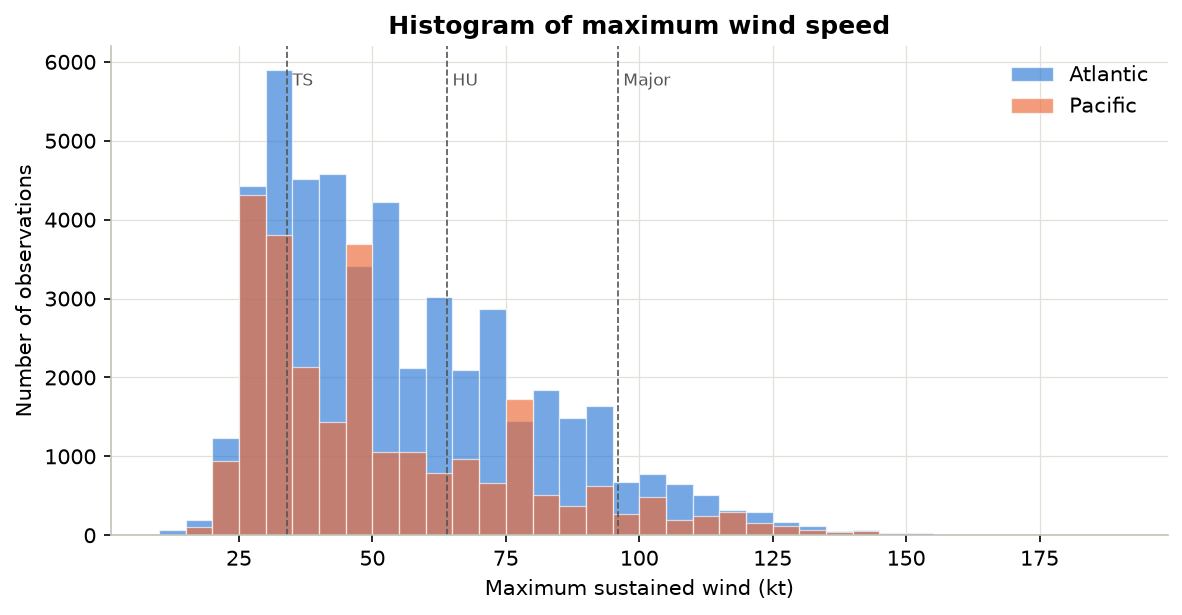

In [24]:
show('fig01_histogram_wind.png')

**Inferences – histogram.** Wind is right-skewed (skew 0.99, mode 30 kt): 70.8 % of all observations are below
hurricane force and only 6.3 % are major hurricanes (≥ 96 kt). 99.99 % of values are multiples of 5 kt (the
reporting resolution), so 5-kt bins are the natural bin width.

In [25]:
# =========================================================================
# 2. BOX PLOT - Wind by storm status
# =========================================================================
log("\n[2] Box plot of wind by status")
order = ["LOW", "TD", "SUB", "TS", "EX", "HU"]
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.boxplot(data=df, x="StatusGroup", y="Wind", hue="Basin", order=order,
            palette=BASIN_COL, ax=ax, fliersize=1.5, linewidth=.8)
ax.set(xlabel="Status group", ylabel="Maximum wind (kt)",
       title="Box plot: wind distribution per status (five-number summary)")
save(fig, "fig02_boxplot_status.png")
five = df.groupby("StatusGroup")["Wind"].describe()[["min", "25%", "50%", "75%", "max"]].loc[order]
log(five.to_string())
res["five_num"] = five.to_dict(orient="index")
res["ex_median"] = float(five.loc["EX", "50%"])


[2] Box plot of wind by status


   -> saved fig02_boxplot_status.png
              min   25%   50%   75%    max
StatusGroup                               
LOW          10.0  20.0  25.0  25.0   60.0
TD           10.0  25.0  30.0  30.0   32.0
SUB          10.0  30.0  40.0  50.0   70.0
TS           35.0  40.0  45.0  50.0   60.0
EX           10.0  35.0  45.0  55.0   95.0
HU           65.0  70.0  80.0  95.0  185.0


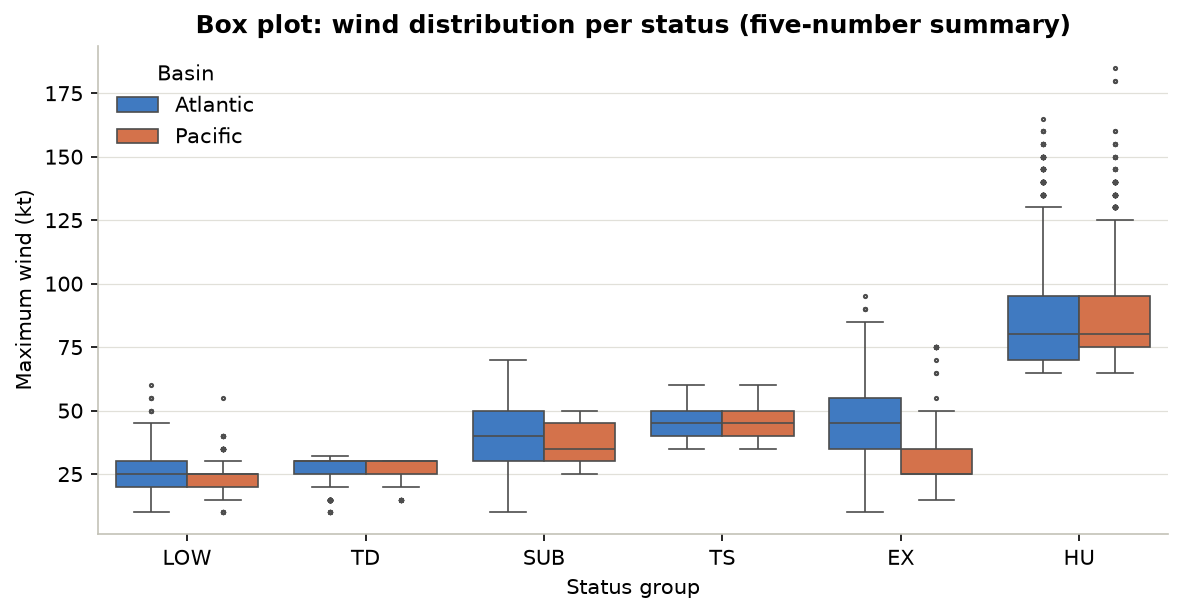

In [26]:
show('fig02_boxplot_status.png')

**Inferences – box plot.** HU: median 80 kt, IQR 70–95 kt, outliers up to 185 kt. TS lies strictly within 35–60 kt
and TD ≤ 32 kt, which confirms that the cleaning removed every status/wind contradiction. Atlantic extratropical
systems are much stronger (median 45 kt) than Pacific ones (25 kt): Atlantic storms recurve into the westerlies,
while Pacific storms decay over cold water.

In [27]:
# =========================================================================
# 3. QUANTILE PLOT - Minimum Pressure
# =========================================================================
log("\n[3] Quantile plot of minimum pressure")
fig, ax = plt.subplots(figsize=(8, 4.2))
for b in ("Atlantic", "Pacific"):
    x = np.sort(df.loc[(df.Basin == b) & df.Pressure.notna(), "Pressure"].values)
    f = (np.arange(1, len(x) + 1) - 0.5) / len(x)          # f-value
    ax.plot(f, x, color=BASIN_COL[b], lw=2, label=b)
ax.set(xlabel="f-value (fraction of data)", ylabel="Minimum pressure (hPa)",
       title="Quantile plot of central pressure")
ax.legend()
save(fig, "fig03_quantile_pressure.png")
q = df.groupby("Basin")["Pressure"].quantile([.1, .25, .5, .75]).unstack()
log(q.to_string())
res["pressure_quantiles"] = q.to_dict(orient="index")


[3] Quantile plot of minimum pressure


   -> saved fig03_quantile_pressure.png
           0.10   0.25    0.50    0.75
Basin                                 
Atlantic  965.0  984.0   999.0  1006.0
Pacific   970.0  990.0  1002.0  1007.0


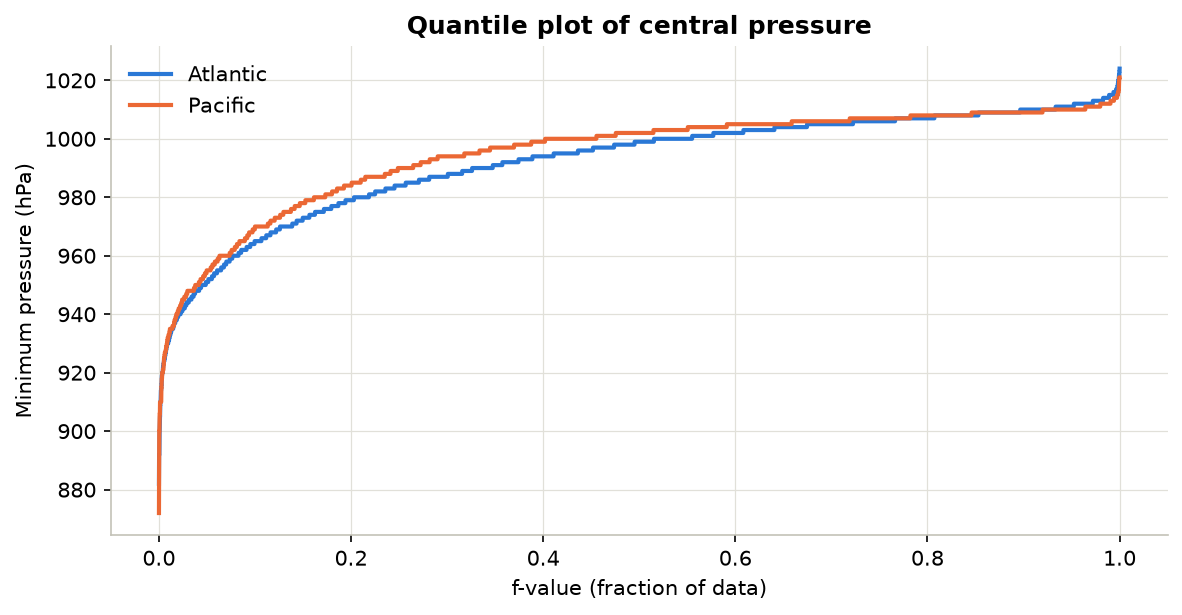

In [28]:
show('fig03_quantile_pressure.png')

**Inferences – quantile plot.** Atlantic pressures are lower at every quantile (10 %: 965 vs 970 hPa; median: 999
vs 1002 hPa). The steep drop below f ≈ 0.05 shows how rare deep systems are: the 5th percentile is 952 hPa and only
4.1 % of readings are below 950 hPa.

In [29]:
# =========================================================================
# 4. Q-Q PLOT - Atlantic vs Pacific lifetime-max wind (storm level)
#    (plus a normal-probability Q-Q in a second panel)
# =========================================================================
log("\n[4] Q-Q plot")
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
a = np.sort(storms.loc[storms.Basin == "Atlantic", "MaxWind"].values)
p = np.sort(storms.loc[storms.Basin == "Pacific", "MaxWind"].values)
qs = np.linspace(0.01, 0.99, 99)
qa, qp = np.quantile(a, qs), np.quantile(p, qs)
axs[0].scatter(qa, qp, s=14, color=CAT_COLS[0])
lim = [min(qa.min(), qp.min()), max(qa.max(), qp.max())]
axs[0].plot(lim, lim, color="#888", ls="--", lw=1, label="y = x")
axs[0].set(xlabel="Atlantic quantiles of storm max wind (kt)", ylabel="Pacific quantiles (kt)",
           title="Q-Q: Atlantic vs Pacific")
axs[0].legend()
(osm, osr), (slope, inter, r) = st.probplot(storms["MaxWind"], dist="norm")
axs[1].scatter(osm, osr, s=5, color=CAT_COLS[0])
axs[1].plot(osm, slope * osm + inter, color=CAT_COLS[1], lw=2)
axs[1].set(xlabel="Theoretical normal quantiles", ylabel="Storm max wind (kt)",
           title=f"Normal Q-Q (r = {r:.3f})")
save(fig, "fig04_qq_plot.png")
res["qq_upper_diff"] = round(float(np.mean(qp[80:] - qa[80:])), 1)
res["qq_lower_diff"] = round(float(np.mean(qp[:30] - qa[:30])), 1)
res["normal_qq_r"] = round(float(r), 3)
log(f"   mean(Pacific-Atlantic) at upper 20 % quantiles = {res['qq_upper_diff']} kt; "
    f"lower 30 % = {res['qq_lower_diff']} kt; normal-QQ r = {res['normal_qq_r']}")


[4] Q-Q plot


   -> saved fig04_qq_plot.png
   mean(Pacific-Atlantic) at upper 20 % quantiles = 4.4 kt; lower 30 % = 1.3 kt; normal-QQ r = 0.973


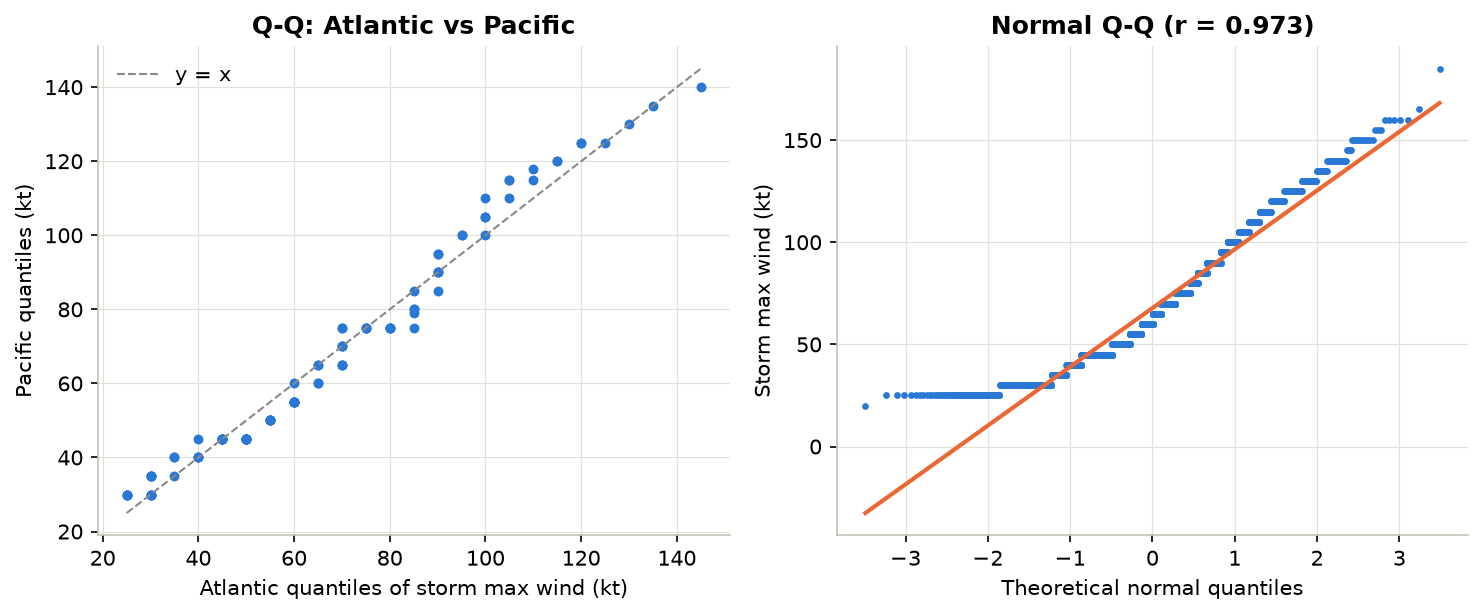

In [30]:
show('fig04_qq_plot.png')

**Inferences – Q-Q plots.** Left: Atlantic and Pacific quantiles coincide in the lower part (+1.3 kt) but the
Pacific is higher in the upper 20 % (+4.4 kt), so the most intense Pacific storms are slightly stronger. Right:
the convex curve (r = 0.973) shows that lifetime maximum wind is right-skewed, not normal.

In [31]:
# =========================================================================
# 5. SCATTER PLOT - Wind vs Pressure (wind-pressure relationship)
# =========================================================================
log("\n[5] Scatter plot wind vs pressure")
wp = df.dropna(subset=["Pressure"])
fig, ax = plt.subplots(figsize=(8, 4.6))
for b in ("Atlantic", "Pacific"):
    s = wp[wp.Basin == b]
    ax.scatter(s.Pressure, s.Wind, s=3, alpha=.25, color=BASIN_COL[b], label=b, rasterized=True)
lr = st.linregress(wp.Pressure, wp.Wind)
xx = np.linspace(wp.Pressure.min(), wp.Pressure.max(), 50)
ax.plot(xx, lr.intercept + lr.slope * xx, color="#222", lw=1.5,
        label=f"OLS: wind = {lr.intercept:.0f} {lr.slope:+.2f}*P  (r={lr.rvalue:.2f})")
ax.set(xlabel="Minimum central pressure (hPa)", ylabel="Maximum wind (kt)",
       title="Scatter plot: wind-pressure relationship")
ax.legend(markerscale=4)
save(fig, "fig05_scatter_wind_pressure.png")
res["wp_slope"] = round(lr.slope, 3); res["wp_r"] = round(lr.rvalue, 3)
res["wp_intercept"] = round(lr.intercept, 1)
log(f"   wind = {lr.intercept:.1f} + {lr.slope:.3f}*P, r = {lr.rvalue:.3f}, n = {len(wp)}")


[5] Scatter plot wind vs pressure


   -> saved fig05_scatter_wind_pressure.png
   wind = 1389.3 + -1.347*P, r = -0.944, n = 31765


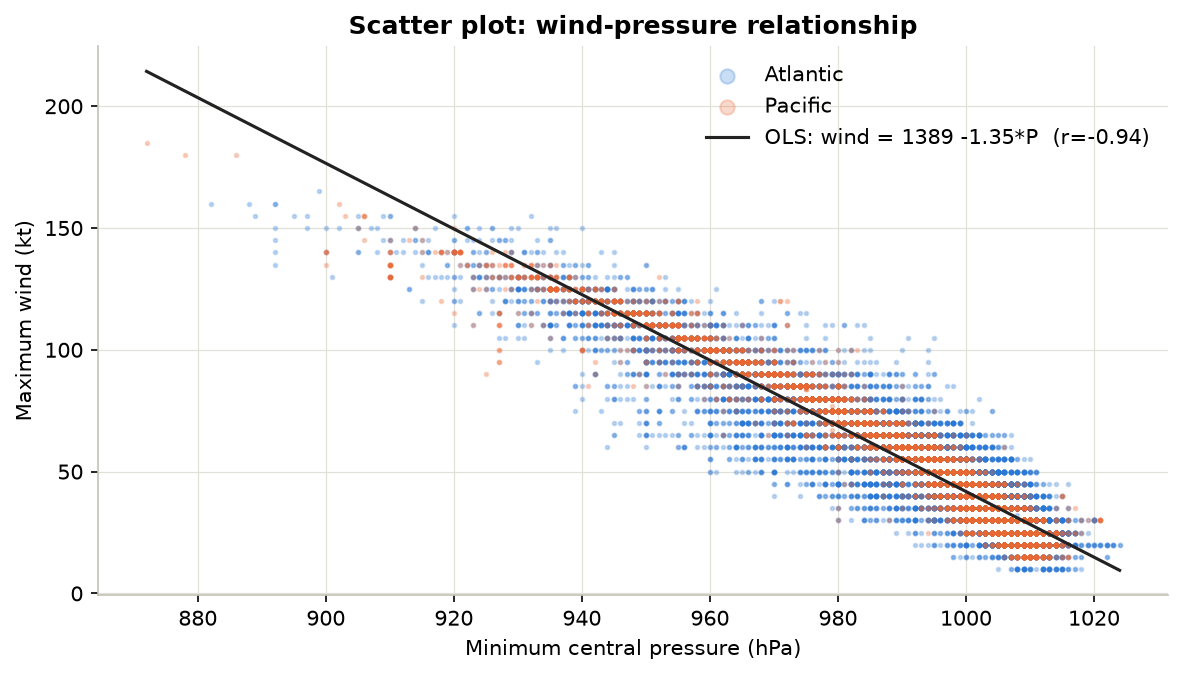

In [32]:
show('fig05_scatter_wind_pressure.png')

**Inferences – scatter plot.** There is a very strong linear inverse relation (r = −0.944): each 1 hPa drop adds
about 1.35 kt. This justifies using pressure as the physical predictor of Status in the decision tree. The spread
widens at low pressure, because the wind-pressure relation depends on storm size and latitude.

In [33]:
# =========================================================================
# 6. SCATTER-PLOT MATRIX (storm level)
# =========================================================================
log("\n[6] Scatter-plot matrix (storm level)")
spm = storms[["MaxWind", "MinPressure", "DurationH", "TrackKm", "GenesisLat", "Basin"]].dropna()
g = sns.pairplot(spm, hue="Basin", palette=BASIN_COL, corner=True,
                 plot_kws={"s": 6, "alpha": .4, "linewidth": 0}, diag_kws={"linewidth": 1},
                 height=1.75)
g.figure.suptitle("Scatter-plot matrix of storm-level attributes", y=1.01, fontweight="bold")
g.figure.savefig(os.path.join(FIG_DIR, "fig06_scatter_matrix.png"), bbox_inches="tight", dpi=130)
plt.close(g.figure)
log("   -> saved fig06_scatter_matrix.png")


[6] Scatter-plot matrix (storm level)


   -> saved fig06_scatter_matrix.png


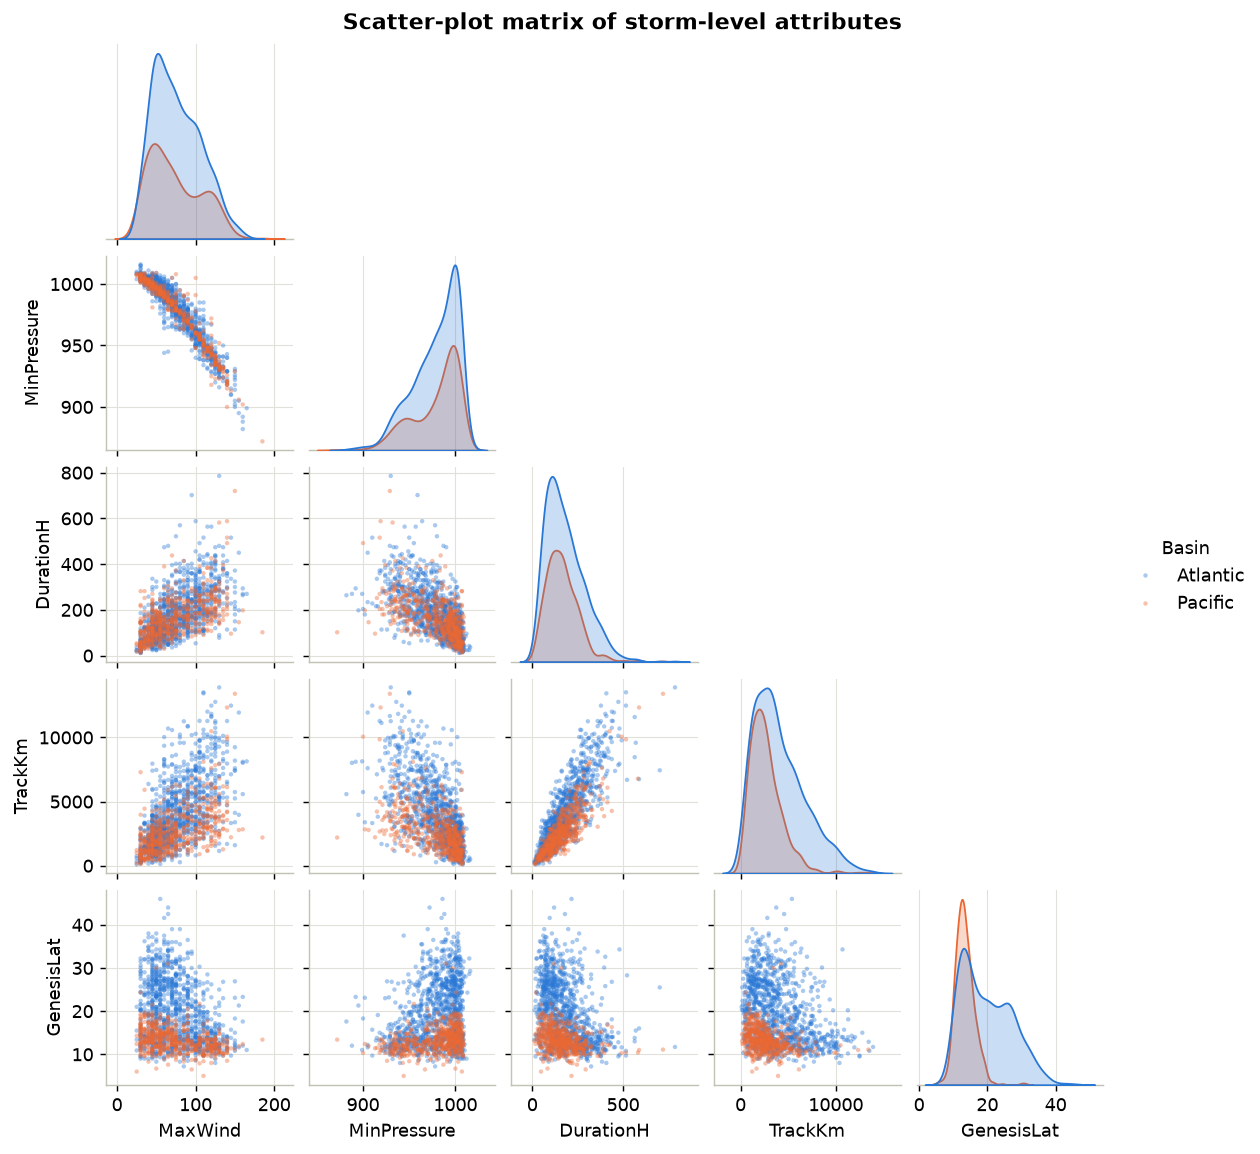

In [34]:
show('fig06_scatter_matrix.png')

**Inferences – scatter-plot matrix.** MaxWind–MinPressure is a tight line and DurationH–TrackKm is strongly
positive. Long-lived storms reach higher winds, and Pacific storms form at lower genesis latitudes.

In [35]:
# =========================================================================
# 7. CORRELATION HEAT-MAP (storm level)
# =========================================================================
log("\n[7] Correlation heat-map")
cm = storms[["MaxWind", "MinPressure", "DurationH", "TrackKm", "NumObs", "GenesisLat",
             "GenesisLon", "Year", "Max24hIntensification", "Landfall"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax,
            linewidths=.5, linecolor="white", annot_kws={"size": 8}, cbar_kws={"label": "Pearson r"})
ax.set_title("Correlation heat-map (storm level)")
save(fig, "fig07_correlation_heatmap.png")
log(cm.round(2).to_string())
res["corr"] = cm.round(2).to_dict()


[7] Correlation heat-map


   -> saved fig07_correlation_heatmap.png
                       MaxWind  MinPressure  DurationH  TrackKm  NumObs  GenesisLat  GenesisLon  Year  Max24hIntensification  Landfall
MaxWind                   1.00        -0.95       0.61     0.58    0.61       -0.20        0.11 -0.11                   0.77      0.18
MinPressure              -0.95         1.00      -0.60    -0.57   -0.61        0.24       -0.13  0.17                  -0.74     -0.16
DurationH                 0.61        -0.60       1.00     0.85    1.00       -0.28        0.23  0.04                   0.46      0.09
TrackKm                   0.58        -0.57       0.85     1.00    0.86       -0.21        0.39 -0.03                   0.41      0.12
NumObs                    0.61        -0.61       1.00     0.86    1.00       -0.27        0.24  0.04                   0.47      0.12
GenesisLat               -0.20         0.24      -0.28    -0.21   -0.27        1.00        0.19 -0.28                  -0.21      0.12
GenesisLon   

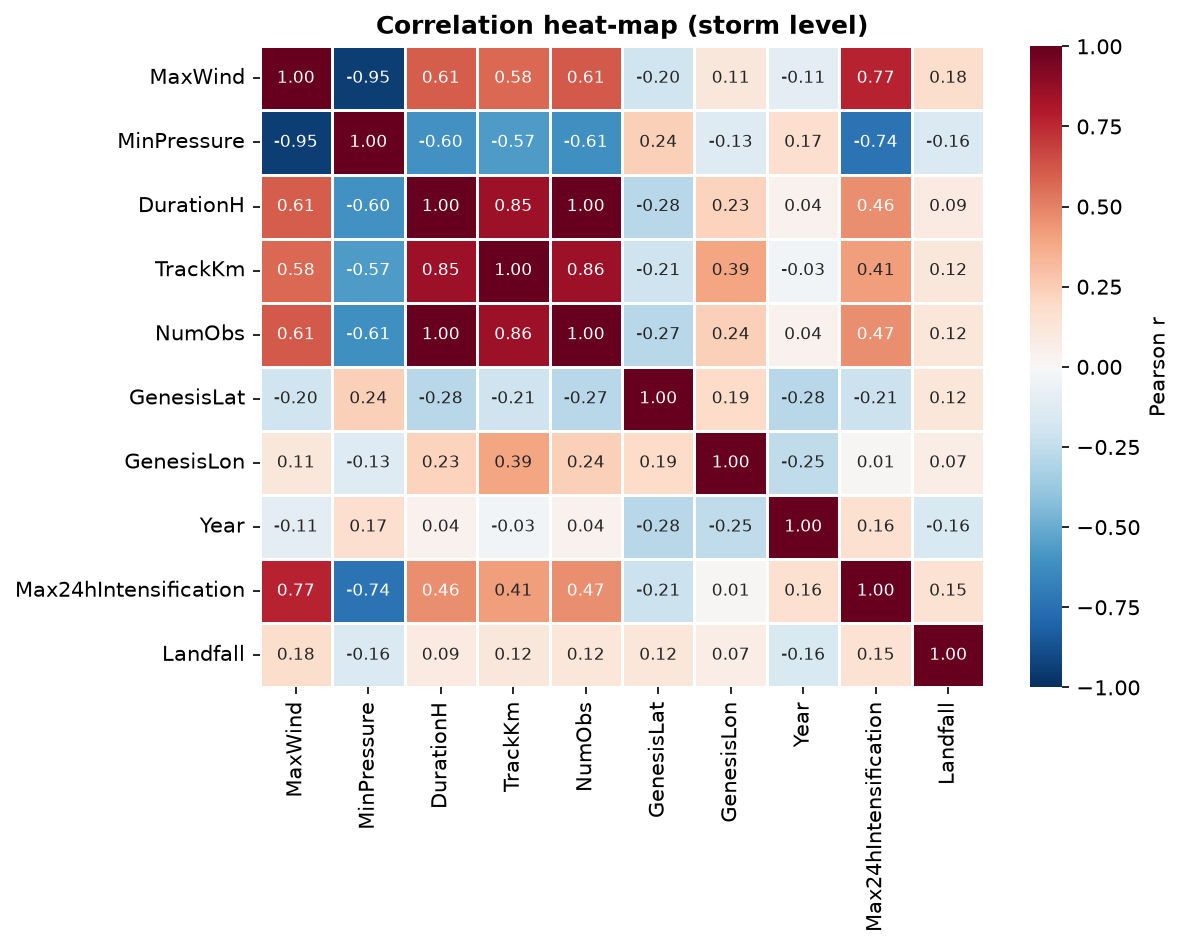

In [36]:
show('fig07_correlation_heatmap.png')

**Inferences – heat-map.** MaxWind–MinPressure r = −0.95. MaxWind–Max24hIntensification r = 0.77: strong storms
get there by rapid intensification. DurationH–NumObs r = 1.00, so NumObs is redundant and is removed. Lower
genesis latitude goes with longer, stronger storms. Year shows no linear trend in storm peaks (r = −0.11).

In [37]:
# =========================================================================
# 8. GROUPED BAR CHART - storms per genesis month and basin
# =========================================================================
log("\n[8] Bar chart: storms by genesis month")
mon = storms.groupby(["GenesisMonth", "Basin"]).size().unstack(fill_value=0).reindex(range(1, 13), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(12); w = .4
for i, b in enumerate(("Atlantic", "Pacific")):
    ax.bar(x + (i - .5) * w, mon[b], w * .92, color=BASIN_COL[b], label=b)
ax.set_xticks(x, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set(ylabel="Number of storms formed", title="Bar chart: storm genesis by month")
ax.legend()
save(fig, "fig08_bar_month.png")
log(mon.T.to_string())
res["month_counts"] = mon.to_dict()
res["peak_month_atl"] = int(mon["Atlantic"].idxmax()); res["peak_month_pac"] = int(mon["Pacific"].idxmax())
res["atl_aug_oct_share"] = round(100 * mon.loc[8:10, "Atlantic"].sum() / mon["Atlantic"].sum(), 1)
res["pac_jul_sep_share"] = round(100 * mon.loc[7:9, "Pacific"].sum() / mon["Pacific"].sum(), 1)


[8] Bar chart: storms by genesis month


   -> saved fig08_bar_month.png
GenesisMonth  1   2   3   4   5    6    7    8    9    10  11  12
Basin                                                            
Atlantic       3   1   1   5  36  115  163  432  601  340  84  14
Pacific        1   0   1   0  40  131  233  251  226  138  27   2


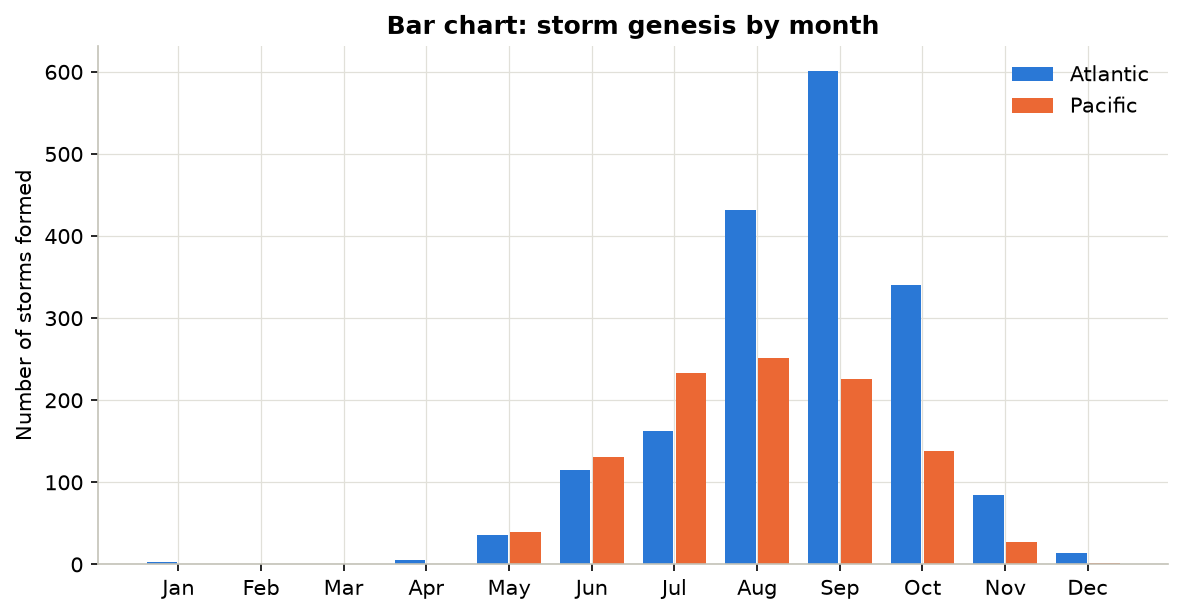

In [38]:
show('fig08_bar_month.png')

**Inferences – bar chart.** The Atlantic season peaks in September (601 storms), with 76.5 % forming in Aug–Oct.
The Pacific peaks in August (251) and starts earlier (May–July: 404 vs 314 Atlantic storms). Only 28 of 2,845
storms formed outside May–November.

In [39]:
# =========================================================================
# 9. LINE CHART - annual storm counts with 10-year moving average
# =========================================================================
log("\n[9] Line chart: storms per year")
yr = storms.groupby(["Year", "Basin"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4.2))
for b in ("Atlantic", "Pacific"):
    s = yr[b] if b == "Atlantic" else yr.loc[yr.index >= 1949, b]
    ax.plot(s.index, s.values, color=BASIN_COL[b], lw=.8, alpha=.45)
    ax.plot(s.index, s.rolling(10, center=True).mean(), color=BASIN_COL[b], lw=2.2,
            label=f"{b} (10-yr moving avg)")
ax.axvline(1966, color="#888", ls=":", lw=1)
ax.text(1967, ax.get_ylim()[1] * .93, "satellite era", fontsize=8, color="#555")
ax.set(xlabel="Year", ylabel="Storms per year", title="Line chart: annual storm counts")
ax.legend()
save(fig, "fig09_line_yearly.png")
pre = yr.loc[1851:1900, "Atlantic"].mean(); post = yr.loc[1966:2015, "Atlantic"].mean()
res["atl_mean_1851_1900"] = round(pre, 1); res["atl_mean_1966_2015"] = round(post, 1)
res["pac_mean_1971_2015"] = round(yr.loc[1971:2015, "Pacific"].mean(), 1)
res["pac_mean_1949_1970"] = round(yr.loc[1949:1970, "Pacific"].mean(), 1)
res["max_year_atl"] = int(yr["Atlantic"].idxmax()); res["max_year_atl_n"] = int(yr["Atlantic"].max())
log(f"   Atlantic mean/yr 1851-1900 = {pre:.1f}; 1966-2015 = {post:.1f}; "
    f"busiest Atlantic year {res['max_year_atl']} ({res['max_year_atl_n']} storms); "
    f"Pacific 1949-70 = {res['pac_mean_1949_1970']}, 1971-2015 = {res['pac_mean_1971_2015']}")


[9] Line chart: storms per year


   -> saved fig09_line_yearly.png
   Atlantic mean/yr 1851-1900 = 7.6; 1966-2015 = 16.2; busiest Atlantic year 2005 (31 storms); Pacific 1949-70 = 10.4, 1971-2015 = 18.2


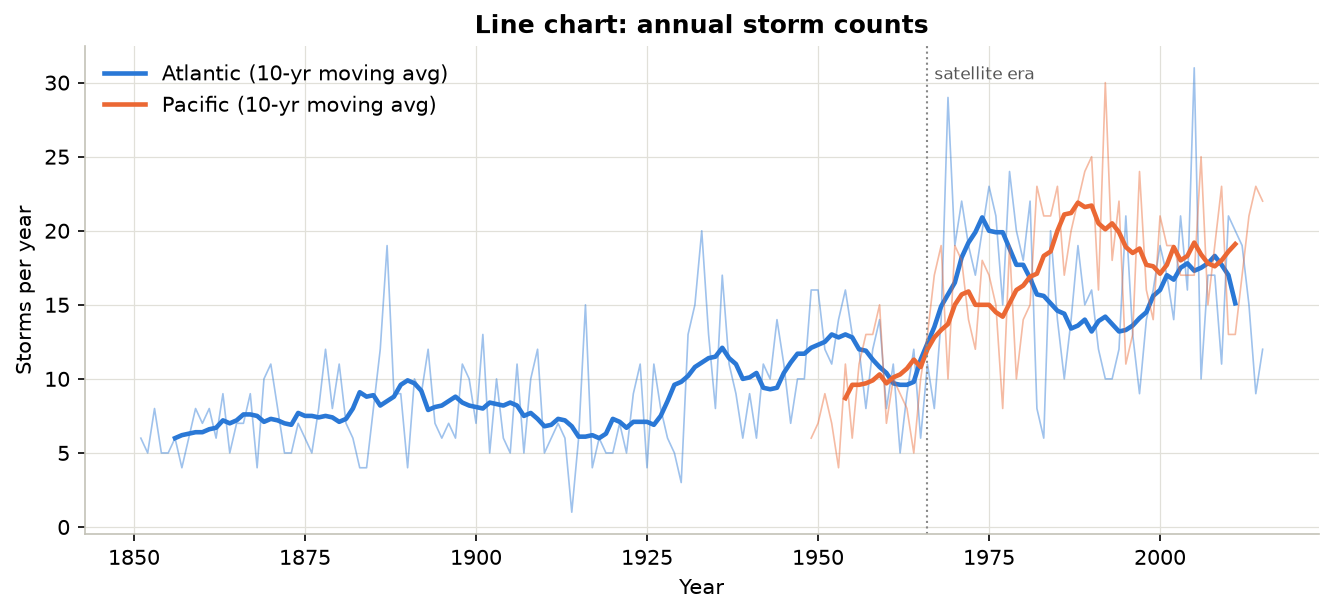

In [40]:
show('fig09_line_yearly.png')

**Inferences – line chart.** Recorded Atlantic activity doubled from 7.6 storms/yr (1851–1900) to 16.2 (1966–2015),
and the Pacific rose from 10.4 to 18.2. The jump around the satellite era shows that much of the rise is improved
detection. The busiest Atlantic year is 2005 (31 storms).

In [41]:
# =========================================================================
# 10. PIE CHART - composition of observations by status
# =========================================================================
log("\n[10] Pie chart: status composition")
sc = df["StatusGroup"].value_counts()
fig, ax = plt.subplots(figsize=(6.4, 5))
ax.pie(sc.values, labels=[f"{k}\n{v:,}" for k, v in sc.items()], autopct="%1.1f%%",
       colors=CAT_COLS[:len(sc)], startangle=90, counterclock=False, pctdistance=.78,
       wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 9})
ax.set_title("Pie chart: share of 6-hourly observations by status")
ax.grid(False)
save(fig, "fig10_pie_status.png")
res["status_share"] = (100 * sc / sc.sum()).round(1).to_dict()
log(res["status_share"])


[10] Pie chart: status composition
   -> saved fig10_pie_status.png
{'TS': 37.2, 'HU': 28.4, 'TD': 22.1, 'EX': 6.8, 'LOW': 4.4, 'SUB': 1.1}


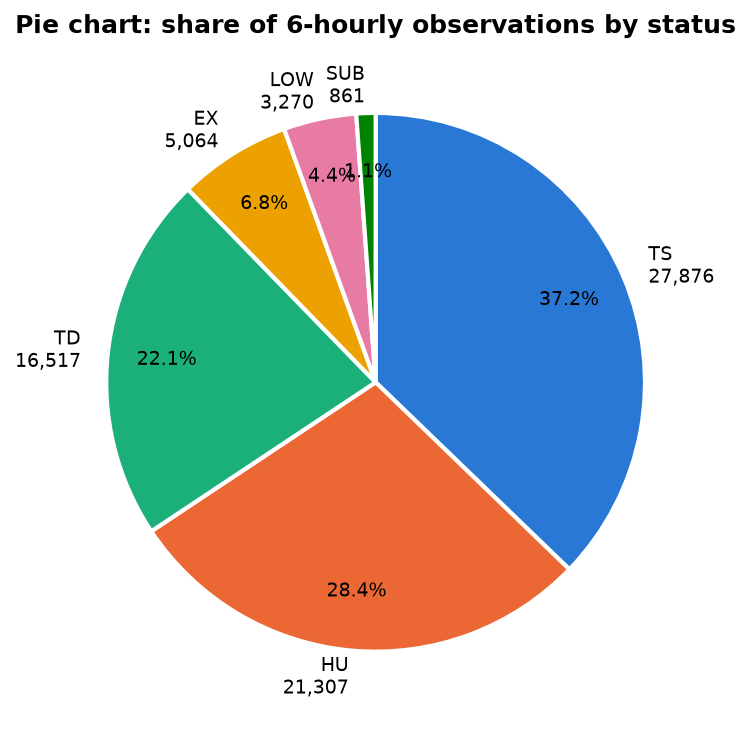

In [42]:
show('fig10_pie_status.png')

**Inferences – pie chart.** TS 37.2 %, HU 28.4 %, TD 22.1 %, EX 6.8 %, LOW 4.4 %, SUB 1.2 %. EX and SUB are small
classes, so the classifier is also evaluated with macro-averaged metrics.

In [43]:
# =========================================================================
# 11. VIOLIN PLOT - storm duration by lifetime maximum category
# =========================================================================
log("\n[11] Violin plot: duration by max category")
fig, ax = plt.subplots(figsize=(8, 4.2))
sv = storms.copy(); sv["DurationDays"] = sv.DurationH / 24
sns.violinplot(data=sv, x="MaxCategory", y="DurationDays", order=SS_ORDER, color=CAT_COLS[0],
               inner="quartile", cut=0, linewidth=.8, ax=ax)
ax.set(xlabel="Lifetime maximum Saffir-Simpson category", ylabel="Storm duration (days)",
       title="Violin plot: storm lifetime by peak intensity")
save(fig, "fig11_violin_duration.png")
md = sv.groupby("MaxCategory")["DurationDays"].median().reindex(SS_ORDER).round(1)
log(md.to_string())
res["median_duration_by_cat"] = md.to_dict()


[11] Violin plot: duration by max category


   -> saved fig11_violin_duration.png
MaxCategory
TD       2.2
TS       4.2
Cat1     6.0
Cat2     7.2
Cat3     9.2
Cat4    10.2
Cat5    11.2


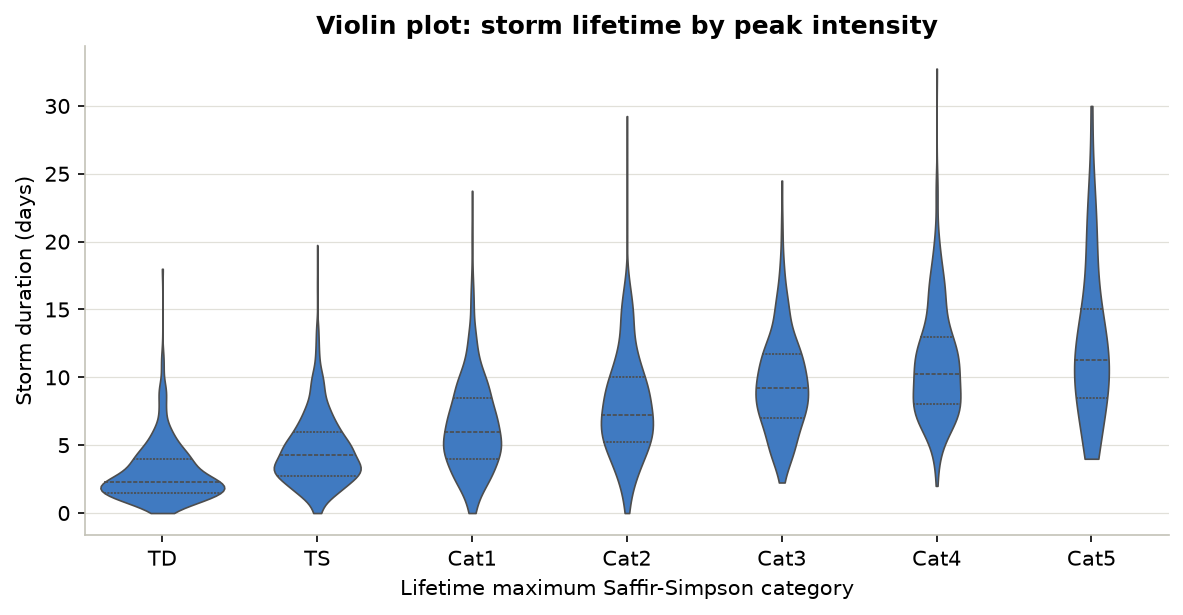

In [44]:
show('fig11_violin_duration.png')

**Inferences – violin plot.** Median lifetime rises steadily with peak category: TD 2.2 days, TS 4.2, Cat1 6.0,
Cat3 9.2, Cat5 11.2. Reaching high intensity requires a long time over warm water.

In [45]:
# =========================================================================
# 12. GEOGRAPHIC TRACK MAP - all fixes coloured by intensity
# =========================================================================
log("\n[12] Track map")
fig, ax = plt.subplots(figsize=(10, 4.8))
srt = df.sort_values("Wind")
sca = ax.scatter(srt.Longitude, srt.Latitude, c=srt.Wind, s=.6, cmap="YlOrRd", vmin=20, vmax=150,
                 rasterized=True)
plt.colorbar(sca, ax=ax, label="Maximum wind (kt)", pad=.01)
ax.set(xlim=(-185, 15), ylim=(0, 72), xlabel="Longitude (deg, W negative)", ylabel="Latitude (deg N)",
       title="Track map: every 6-hourly fix coloured by intensity")
ax.set_aspect("equal")
save(fig, "fig12_track_map.png")
hu = df[df.Status == "HU"]
res["hu_lat_mean"] = round(hu.Latitude.mean(), 1)
res["major_lat_p90"] = round(df.loc[df.Wind >= 96, "Latitude"].quantile(.9), 1)
log(f"   mean latitude of HU fixes = {res['hu_lat_mean']}; 90th pct latitude of major fixes = {res['major_lat_p90']}")


[12] Track map


   -> saved fig12_track_map.png
   mean latitude of HU fixes = 24.0; 90th pct latitude of major fixes = 30.3


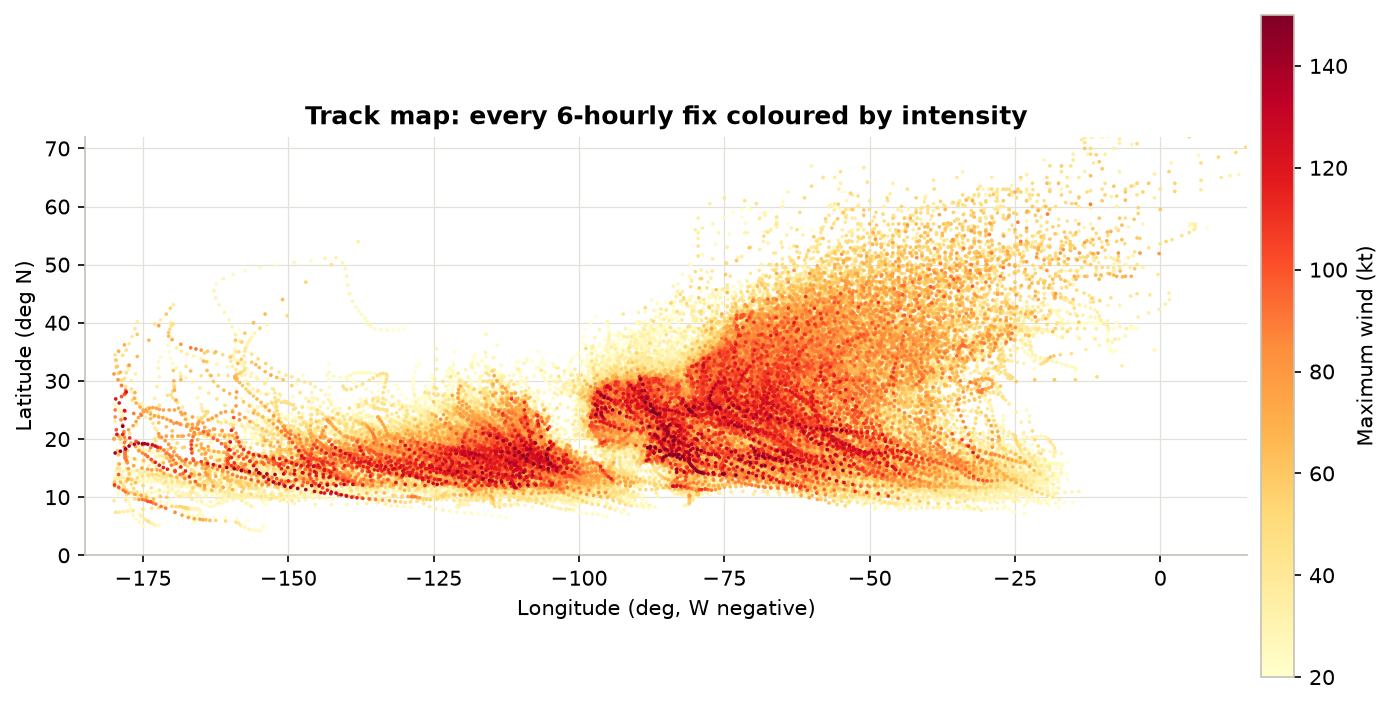

In [46]:
show('fig12_track_map.png')

**Inferences – track map.** Pacific storms move west at 10–20°N and die over cool water. Atlantic storms recurve
north-east and often become extratropical. Intense fixes are tropical: 90 % of major-hurricane fixes lie south of
30.3°N. Landfall: 32.9 % of Atlantic storms vs 6.4 % of Pacific storms.

In [47]:
# =========================================================================
# 13. PARALLEL COORDINATES - storm profiles by peak category
# =========================================================================
log("\n[13] Parallel coordinates")
pc = storms[["MaxWind", "MinPressure", "DurationH", "TrackKm", "GenesisLat", "MaxCategory"]].dropna()
pc = pc[pc.MaxCategory.isin(["TS", "Cat1", "Cat3", "Cat5"])]
pc = pd.concat([pc[pc.MaxCategory == c].sample(min((pc.MaxCategory == c).sum(), 40), random_state=1)
                for c in ["TS", "Cat1", "Cat3", "Cat5"]])          # ordered weak -> strong
cols = ["MaxWind", "MinPressure", "DurationH", "TrackKm", "GenesisLat"]
pcn = pc.copy()
pcn[cols] = (pc[cols] - pc[cols].min()) / (pc[cols].max() - pc[cols].min())   # min-max scale axes
fig, ax = plt.subplots(figsize=(9, 4.4))
parallel_coordinates(pcn, "MaxCategory", cols=cols, color=CAT_COLS[:4], alpha=.45, lw=1, ax=ax)
ax.set(ylabel="Min-max normalised value", title="Parallel coordinates: storm profiles by peak category")
ax.legend(title="Peak category", loc="upper right")
save(fig, "fig13_parallel_coordinates.png")
log(pc.groupby("MaxCategory")[cols].median().round(0).to_string())
res["pc_medians"] = pc.groupby("MaxCategory")[cols].median().round(0).to_dict(orient="index")


[13] Parallel coordinates


   -> saved fig13_parallel_coordinates.png
             MaxWind  MinPressure  DurationH  TrackKm  GenesisLat
MaxCategory                                                      
Cat1            70.0        986.0      141.0   2740.0        16.0
Cat3           105.0        958.0      246.0   5824.0        13.0
Cat5           145.0        918.0      267.0   5665.0        12.0
TS              50.0        998.0      120.0   1874.0        18.0


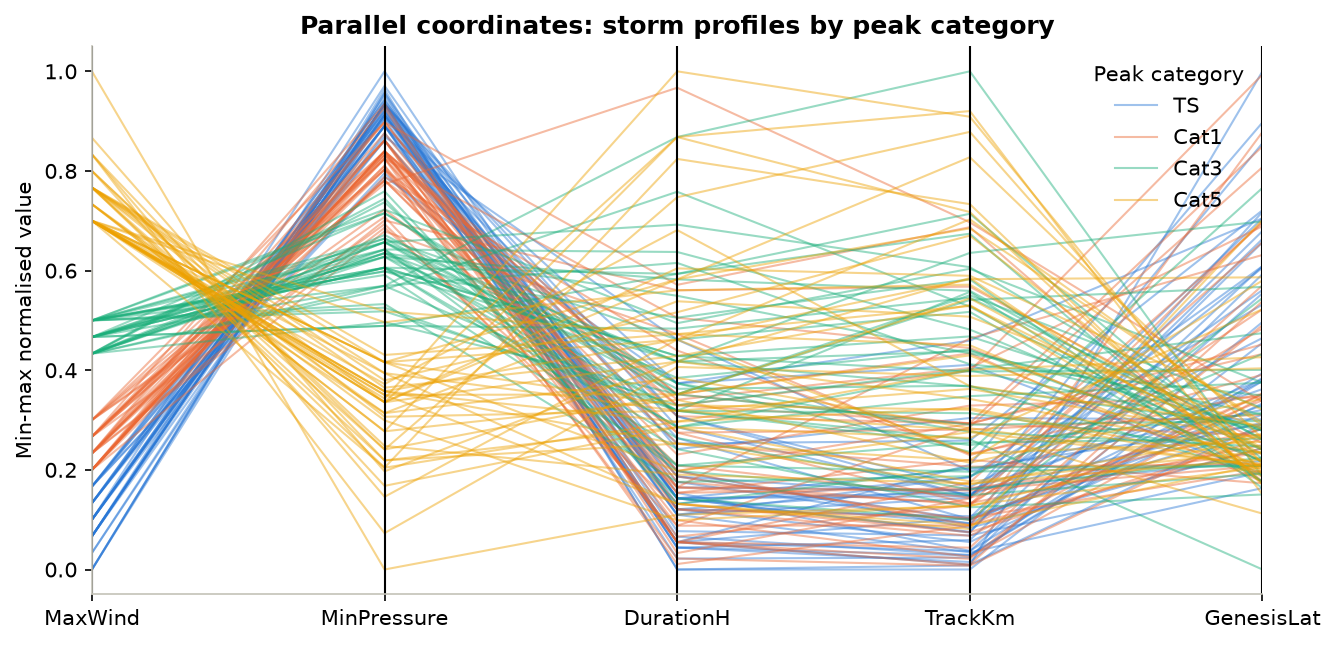

In [48]:
show('fig13_parallel_coordinates.png')

**Inferences – parallel coordinates.** Cat5 storms (median 918 hPa, 267 h, 5,665 km track) are separated from
tropical storms (998 hPa, 120 h, 1,874 km) on every axis, and they form closer to the equator (12°N vs 18°N).

In [49]:
# =========================================================================
# 14. HEXBIN DENSITY PLOT - genesis locations
# =========================================================================
log("\n[14] Hexbin density of genesis points")
fig, ax = plt.subplots(figsize=(10, 4.4))
hb = ax.hexbin(storms.GenesisLon, storms.GenesisLat, gridsize=45, cmap=SEQ, mincnt=1,
               extent=(-185, 0, 0, 50))
plt.colorbar(hb, ax=ax, label="Storms formed per cell")
ax.set(xlabel="Longitude", ylabel="Latitude", title="Hexbin density: where storms are born")
ax.set_aspect("equal")
save(fig, "fig14_hexbin_genesis.png")
res["genesis_lat_median"] = storms.groupby("Basin").GenesisLat.median().round(1).to_dict()
res["genesis_lon_median"] = storms.groupby("Basin").GenesisLon.median().round(1).to_dict()
log(f"   median genesis lat {res['genesis_lat_median']}, lon {res['genesis_lon_median']}")


[14] Hexbin density of genesis points


   -> saved fig14_hexbin_genesis.png
   median genesis lat {'Atlantic': 19.8, 'Pacific': 13.3}, lon {'Atlantic': -67.5, 'Pacific': -106.9}


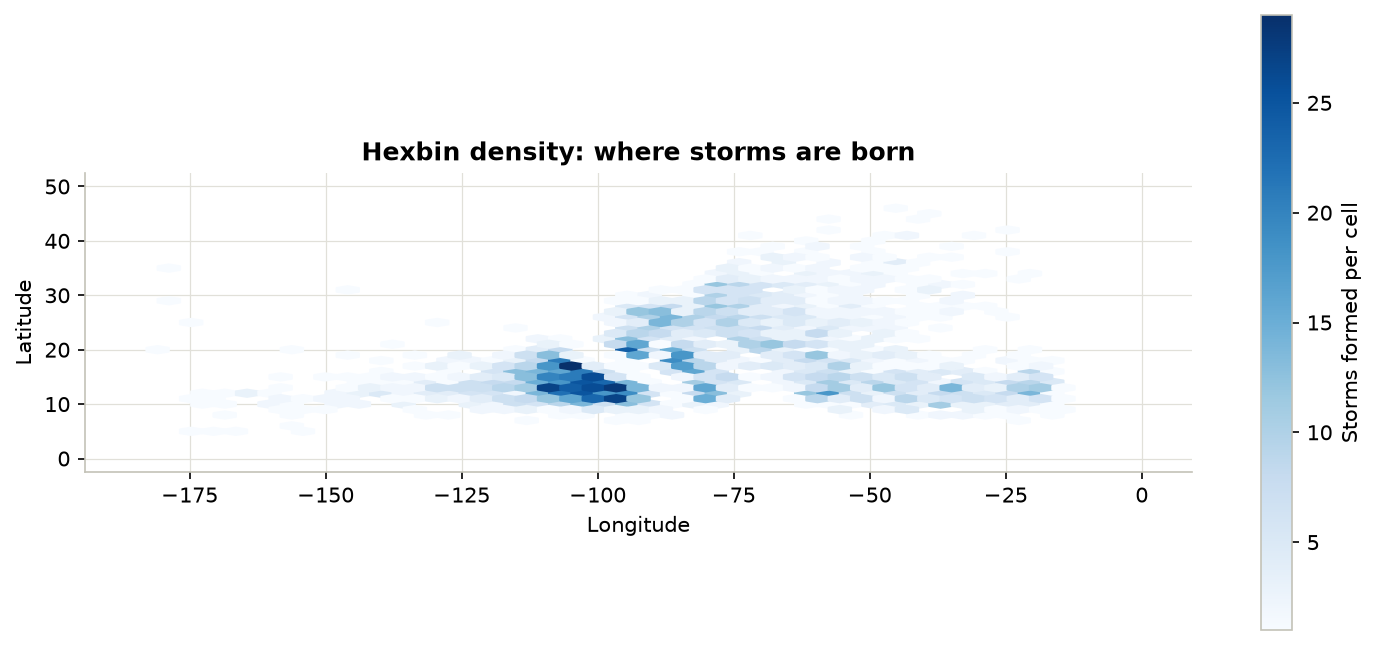

In [50]:
show('fig14_hexbin_genesis.png')

**Inferences – hexbin.** There are two dense nurseries: the eastern Pacific off Mexico (median 13.3°N, 106.9°W) and
the Atlantic (19.8°N, 67.5°W). Atlantic genesis is spread from Africa to the Gulf of Mexico, which motivates
density-based clustering (Part 5).

In [51]:
# =========================================================================
# 15. 100 % STACKED BAR - peak-category mix per era (hurricanes only)
# =========================================================================
log("\n[15] Stacked bar: category mix by period")
hs = storms[storms.MaxCategory.isin(["Cat1", "Cat2", "Cat3", "Cat4", "Cat5"])].copy()
hs["Period"] = pd.cut(hs.Year, [1850, 1900, 1950, 1980, 2000, 2015],
                      labels=["1851-1900", "1901-1950", "1951-1980", "1981-2000", "2001-2015"])
ct = pd.crosstab([hs.Basin, hs.Period], hs.MaxCategory, normalize="index").mul(100)
ct = ct[["Cat1", "Cat2", "Cat3", "Cat4", "Cat5"]]
ct = ct[(ct.index.get_level_values(0) == "Atlantic") |
        (ct.index.get_level_values(1).isin(["1951-1980", "1981-2000", "2001-2015"]))]
fig, ax = plt.subplots(figsize=(9, 4.4))
blues = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
bottom = np.zeros(len(ct))
labels = [f"{b[:3]}\n{p}" for b, p in ct.index]
for c, colr in zip(ct.columns, blues):
    ax.bar(labels, ct[c], bottom=bottom, color=colr, label=c, edgecolor="white", linewidth=1.5)
    bottom += ct[c].values
ax.set(ylabel="% of hurricanes", title="Stacked bar: peak category mix of hurricanes by period")
ax.legend(title="Peak", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.tick_params(axis="x", labelsize=8)
save(fig, "fig15_stacked_category.png")
log(ct.round(1).to_string())
ct["major"] = ct[["Cat3", "Cat4", "Cat5"]].sum(axis=1)
res["major_share_by_period"] = {f"{b} {p}": round(v, 1) for (b, p), v in ct["major"].items()}
log(res["major_share_by_period"])


[15] Stacked bar: category mix by period


   -> saved fig15_stacked_category.png
MaxCategory         Cat1  Cat2  Cat3  Cat4  Cat5
Basin    Period                                 
Atlantic 1851-1900  40.8  36.3  17.9   5.0   0.0
         1901-1950  35.5  28.9  17.8  14.5   3.3
         1951-1980  41.3  20.1  18.4  14.5   5.6
         1981-2000  43.1  19.8  15.5  18.1   3.4
         2001-2015  42.2  13.8  17.4  19.3   7.3
Pacific  1951-1980  59.1  13.5  12.9  13.5   1.2
         1981-2000  33.5  15.5  19.0  28.5   3.5
         2001-2015  37.5  15.6  15.6  24.2   7.0
{'Atlantic 1851-1900': 22.9, 'Atlantic 1901-1950': 35.5, 'Atlantic 1951-1980': 38.5, 'Atlantic 1981-2000': 37.1, 'Atlantic 2001-2015': 44.0, 'Pacific 1951-1980': 27.5, 'Pacific 1981-2000': 51.0, 'Pacific 2001-2015': 46.9}


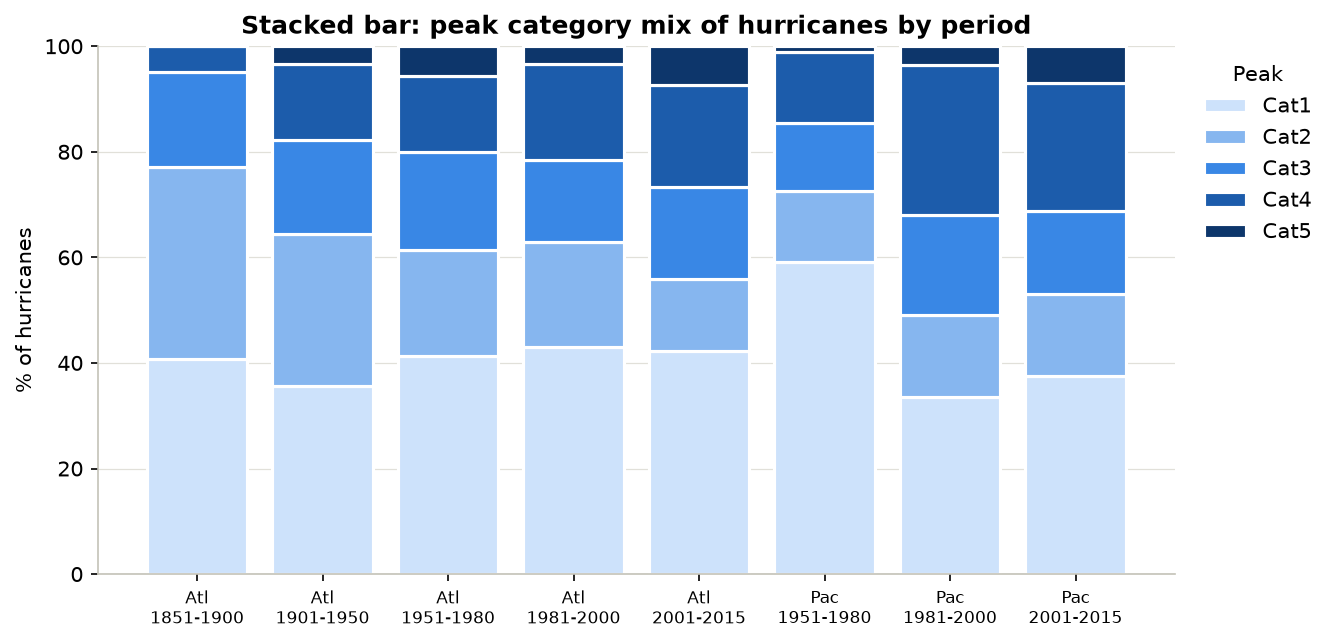

In [52]:
show('fig15_stacked_category.png')

**Inferences – stacked bar.** The share of hurricanes that became major rose from 22.9 % (Atlantic 1851–1900) to
44.0 % (2001–2015), and from 27.5 % to 46.9 % in the Pacific. No Cat5 storm is recorded before 1924. Part of this
shift reflects better measurement (aircraft and satellites).

In [53]:
# ---- extra facts used in the inferences ---------------------------------
res["landfall_by_basin"] = (storms.groupby("Basin").Landfall.mean() * 100).round(1).to_dict()
res["hurricane_rate"] = (storms.groupby("Basin").BecameHurricane.mean() * 100).round(1).to_dict()
res["ex_rate"] = (storms.groupby("Basin").BecameExtratropical.mean() * 100).round(1).to_dict()
log("\nLandfall % by basin:", res["landfall_by_basin"])
log("Storms reaching hurricane %:", res["hurricane_rate"])
log("Storms becoming extratropical %:", res["ex_rate"])
top = storms.nlargest(5, "MaxWind")[["ID", "Name", "Year", "MaxWind", "MinPressure"]]
log("Strongest storms:\n" + top.to_string(index=False))
res["top_storms"] = top.to_dict(orient="records")

save_json(res, "visualization")
log.close()


Landfall % by basin: {'Atlantic': 32.9, 'Pacific': 6.4}
Storms reaching hurricane %: {'Atlantic': 49.6, 'Pacific': 48.3}
Storms becoming extratropical %: {'Atlantic': 37.8, 'Pacific': 9.0}
Strongest storms:
      ID     Name  Year  MaxWind  MinPressure
EP202015 PATRICIA  2015    185.0        872.0
AL041980    ALLEN  1980    165.0        899.0
AL031935  UNNAMED  1935    160.0        892.0
AL081988  GILBERT  1988    160.0        888.0
AL252005    WILMA  2005    160.0        882.0


## 3. Association rules with the DIC algorithm
**DIC (Dynamic Itemset Counting, Brin et al. 1997)** reads the transactions in blocks of *M* and has a "stop" after
every block. Each itemset is a **dashed circle** (being counted, below support), **dashed box** (being counted,
already frequent), **solid circle** (fully counted, infrequent) or **solid box** (fully counted, frequent).
A new itemset starts being counted at the next stop as soon as all its immediate subsets are boxes, instead of
waiting for a full pass as Apriori does. Counting wraps around the file until each itemset has seen all N
transactions.

*Input*: 74,895 transactions (one per observation) over 27 attribute=value items. *Parameters*: min_support 5 %,
min_confidence 70 %, M = 5000. The result is **verified against mlxtend's Apriori**.

In [54]:
import time
from itertools import combinations
import numpy as np
import pandas as pd

from common import (MIN_SUPPORT, MIN_CONFIDENCE, DIC_BLOCK_SIZE, CLEAN_DIR, Logger, save_json,
                    load_transactions)
from arm_common import generate_rules, rules_to_frame, fmt_set

log = Logger("03_dic")


def dic(T, min_count, M, item_names=None, trace=None):
    """
    T          : boolean numpy matrix (N transactions x I items)
    min_count  : absolute minimum support count
    M          : block size (transactions between stops)
    returns    : dict {tuple(sorted item idx): support count} of frequent itemsets,
                 number of passes over the data, number of candidates ever counted
    """
    N, I = T.shape
    # state tables, keyed by sorted tuple of item indices
    count, seen, state = {}, {}, {}
    for j in range(I):                              # all 1-itemsets start as dashed circles
        key = (j,)
        count[key], seen[key], state[key] = 0, 0, "DC"
    boxes = set()                                   # DB or SB itemsets
    pos, read, stop_no = 0, 0, 0

    def try_supersets(x):
        """x just became a box: start counting every superset x+{i} whose
        immediate subsets are all boxes (DB or SB)."""
        for i in range(I):
            if i in x:
                continue
            y = tuple(sorted(x + (i,)))
            if y in state:
                continue
            if all(s in boxes for s in combinations(y, len(y) - 1)):
                count[y], seen[y], state[y] = 0, 0, "DC"

    while True:
        dashed = [k for k, s in state.items() if s in ("DC", "DB")]
        if not dashed:
            break
        # ---- read the next block of M transactions (cyclic) ---------------
        idx = (pos + np.arange(M)) % N
        block = T[idx]
        for k in dashed:
            todo = min(M, N - seen[k])               # never count past one full cycle
            rows = block[:todo]
            count[k] += int(np.all(rows[:, list(k)], axis=1).sum())
            seen[k] += todo
        pos = (pos + M) % N
        read += M
        stop_no += 1
        # ---- state transitions at this stop -------------------------------
        newly_boxed = []
        for k in dashed:
            if state[k] == "DC" and count[k] >= min_count:
                state[k] = "DB"
                boxes.add(k)
                newly_boxed.append(k)
        for k in dashed:                             # completed a full cycle -> solid
            if seen[k] >= N:
                state[k] = "SB" if state[k] == "DB" else "SC"
        for k in newly_boxed:
            try_supersets(k)
        if trace is not None:
            sizes = pd.Series([len(k) for k, s in state.items() if s in ("DC", "DB")]).value_counts().to_dict()
            trace.append({"stop": stop_no, "passes": round(read / N, 3),
                          "DC": sum(s == "DC" for s in state.values()),
                          "DB": sum(s == "DB" for s in state.values()),
                          "SC": sum(s == "SC" for s in state.values()),
                          "SB": sum(s == "SB" for s in state.values()),
                          "active_by_size": sizes})
    freq = {k: count[k] for k, s in state.items() if s == "SB"}
    return freq, read / N, len(state)


txns = load_transactions()
items = sorted({i for t in txns for i in t})
idx = {it: j for j, it in enumerate(items)}
N = len(txns)
T = np.zeros((N, len(items)), dtype=bool)
for r, t in enumerate(txns):
    for it in t:
        T[r, idx[it]] = True
min_count = int(np.ceil(MIN_SUPPORT * N))
log(f"Transactions N = {N}, items I = {len(items)}")
log(f"Parameters: min_support = {MIN_SUPPORT:.0%} (count {min_count}), "
    f"min_confidence = {MIN_CONFIDENCE:.0%}, block size M = {DIC_BLOCK_SIZE}")

trace = []
t0 = time.perf_counter()
freq_idx, passes, n_cand = dic(T, min_count, DIC_BLOCK_SIZE, trace=trace)
t_dic = time.perf_counter() - t0
freq = {frozenset(items[j] for j in k): v for k, v in freq_idx.items()}

log(f"\nDIC finished in {t_dic:.2f} s after {len(trace)} stops = {passes:.2f} passes over the data")
log(f"Candidates counted: {n_cand};  frequent itemsets: {len(freq)}")
by_len = pd.Series([len(k) for k in freq]).value_counts().sort_index()
log("Frequent itemsets by size: " + by_len.to_dict().__str__())
log("\nState evolution at selected stops (DC/DB = still counting, SC/SB = finished):")
tr = pd.DataFrame(trace)
log(tr.iloc[np.unique(np.linspace(0, len(tr) - 1, 12).astype(int))].to_string(index=False))

Transactions N = 74895, items I = 27
Parameters: min_support = 5% (count 3745), min_confidence = 70%, block size M = 5000



DIC finished in 1.05 s after 59 stops = 3.94 passes over the data
Candidates counted: 1089;  frequent itemsets: 566
Frequent itemsets by size: {1: 24, 2: 158, 3: 258, 4: 115, 5: 11}

State evolution at selected stops (DC/DB = still counting, SC/SB = finished):
 stop  passes  DC  DB  SC  SB                active_by_size
    1   0.067  26   1   0   0                       {1: 27}
    6   0.401 178  45   0   0        {2: 171, 1: 27, 3: 25}
   11   0.734 365 110   0   0 {2: 276, 3: 171, 1: 27, 4: 1}
   16   1.068 533 177   3  24       {3: 420, 2: 276, 4: 14}
   22   1.469 548 117  56 187       {3: 477, 2: 105, 4: 83}
   27   1.803 440  77 174 334        {3: 329, 4: 186, 5: 2}
   32   2.136 294  24 310 450        {4: 209, 3: 101, 5: 8}
   37   2.470 164  13 404 504        {4: 153, 5: 13, 3: 11}
   43   2.871  38   0 500 550                {4: 24, 5: 14}
   48   3.204  10   0 517 562                  {5: 9, 4: 1}
   53   3.538   4   0 521 564                        {5: 4}
   59   3.939   0 

In [55]:
# ---- verification against Apriori (mlxtend) ------------------------------
from mlxtend.frequent_patterns import apriori
t0 = time.perf_counter()
ap = apriori(pd.DataFrame(T, columns=items), min_support=min_count / N, use_colnames=True)
t_ap = time.perf_counter() - t0
ap_dict = {frozenset(s): int(round(sup * N)) for s, sup in zip(ap.itemsets, ap.support)}
same = ap_dict == freq
log(f"\nVerification vs mlxtend Apriori: {len(ap_dict)} itemsets, identical result = {same}")
max_k = max(len(k) for k in freq)
log(f"Apriori needs {max_k + 1} level-wise passes (one per itemset size + final empty check)"
    f" vs DIC {passes:.2f} passes -> DIC saves {max_k + 1 - passes:.2f} database scans")


Verification vs mlxtend Apriori: 566 itemsets, identical result = True
Apriori needs 6 level-wise passes (one per itemset size + final empty check) vs DIC 3.94 passes -> DIC saves 2.06 database scans


In [56]:
# ---- frequent itemsets output --------------------------------------------
fi = pd.DataFrame([{"itemset": fmt_set(k), "size": len(k), "support_count": v,
                    "support": round(v / N, 4)} for k, v in freq.items()])
fi = fi.sort_values(["size", "support"], ascending=[True, False])
fi.to_csv(f"{CLEAN_DIR}/dic_frequent_itemsets.csv", index=False)
log("\nTop frequent itemsets of size >= 3:")
log(fi[fi["size"] >= 3].sort_values("support", ascending=False).head(12).to_string(index=False))


Top frequent itemsets of size >= 3:
                                               itemset  size  support_count  support
     {Basin=Atlantic, Motion=Westward, Season=Aug-Sep}     3          18056   0.2411
{Motion=Westward, Season=Aug-Sep, Speed=Medium(15-30)}     3          16791   0.2242
         {Lat=15-25N, Motion=Westward, Season=Aug-Sep}     3          16647   0.2223
    {Lat=15-25N, Motion=Westward, Speed=Medium(15-30)}     3          14928   0.1993
{Basin=Atlantic, Motion=Westward, Speed=Medium(15-30)}     3          14372   0.1919
 {Basin=Atlantic, Season=Aug-Sep, Speed=Medium(15-30)}     3          14124   0.1886
          {Basin=Pacific, Lat=15-25N, Motion=Westward}     3          13713   0.1831
         {Basin=Atlantic, Lat=15-25N, Motion=Westward}     3          13152   0.1756
       {Basin=Atlantic, Era=1851-1949, Season=Aug-Sep}     3          12999   0.1736
 {Basin=Pacific, Motion=Westward, Speed=Medium(15-30)}     3          12035   0.1607
      {Basin=Atlantic, Era=1

In [57]:
# ---- association rules --------------------------------------------------
rules = generate_rules(freq, N, MIN_CONFIDENCE)
rdf = rules_to_frame(rules)
rdf.to_csv(f"{CLEAN_DIR}/dic_rules.csv", index=False)
log(f"\n{len(rules)} association rules with confidence >= {MIN_CONFIDENCE:.0%} (saved dic_rules.csv)")
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 80)
log("\nTop 20 rules by lift:")
log(rdf.head(20).to_string(index=False))
# interesting rules with a Status consequent (excluding trivial ones)
st = rdf[rdf["THEN (consequent)"].str.match(r"^\{Status=[A-Z]+\}$")]
log("\nTop 15 rules predicting the storm Status (single consequent):")
log(st.sort_values(["lift", "confidence"], ascending=False).head(15).to_string(index=False))

save_json({"N": N, "items": len(items), "min_count": min_count, "time_s": round(t_dic, 2),
           "passes": round(passes, 2), "stops": len(trace), "candidates": n_cand,
           "n_frequent": len(freq), "by_len": {int(k): int(v) for k, v in by_len.items()},
           "apriori_match": same, "apriori_time_s": round(t_ap, 2), "max_k": max_k,
           "n_rules": len(rules)}, "dic")
log.close()


294 association rules with confidence >= 70% (saved dic_rules.csv)

Top 20 rules by lift:
                                   IF (antecedent)                 THEN (consequent)  support  confidence  lift
                      {Motion=Eastward, Status=EX}                       {Lat=>=35N}   0.0502      0.8635 6.425
                                       {Status=EX}      {Lat=>=35N, Motion=Eastward}   0.0502      0.7421 6.405
                       {Basin=Atlantic, Status=EX}                       {Lat=>=35N}   0.0550      0.8584 6.387
                                       {Status=EX}       {Basin=Atlantic, Lat=>=35N}   0.0550      0.8130 6.129
                                       {Status=EX}                       {Lat=>=35N}   0.0557      0.8231 6.124
{Basin=Atlantic, Motion=Eastward, Speed=Fast(>30)}                       {Lat=>=35N}   0.0669      0.7557 5.622
                {Motion=Eastward, Speed=Fast(>30)}       {Basin=Atlantic, Lat=>=35N}   0.0669      0.7348 5.539
             

**Interpretation (DIC)**
* DIC finds the same 566 frequent itemsets as Apriori (verified) in **3.94 passes instead of 6**. Starting
  longer itemsets mid-pass saves about two database scans.
* `{Status=EX} ⇒ {Lat≥35N}` (confidence 82 %, lift 6.1): extratropical transition happens poleward of 35°N,
  while the storm is carried east by the westerlies (`{Motion=Eastward, Status=EX} ⇒ {Lat≥35N}`, lift 6.4).
* `{Lat≥35N, Speed>30} ⇒ {Motion=Eastward}` (96 %): storms speed up after recurving.
* `{Pressure<980} ⇒ {Status=HU}` (94 %; 98 % for westward-moving storms): a deep central pressure almost always
  means a hurricane.
* `{Era=1990-2015, Status=TD} ⇒ {Pressure≥1000}` (87 %): modern depressions are measured, and they are weak lows.

## 4. Decision Tree classifier — predicting the storm status
* **Target:** Status ∈ {TD, TS, HU, EX} of each observation.
* **Features:** Latitude, Longitude, Month, Basin, Pressure, 6-h pressure tendency, speed, heading, hours since
  genesis. **Maximum Wind is excluded**, because Status is defined from wind thresholds (that would be target
  leakage).
* **Validation:** consecutive fixes of one storm are nearly identical, so the train/test split is done **by storm**
  (GroupShuffleSplit 70/30), and depth/criterion are tuned with **5-fold GroupKFold** CV.
* **Outputs:** accuracy, precision/recall/F1, Cohen's kappa, confusion matrix, feature importance, tree diagram
  and **IF-THEN rules**.

In [58]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, cohen_kappa_score)

from common import CLEAN_TRACKS, CLEAN_DIR, FIG_DIR, RANDOM_STATE, Logger, save_json

log = Logger("05_decision_tree")
CLASSES = ["TD", "TS", "HU", "EX"]
FEATURES = ["Latitude", "Longitude", "Month", "BasinCode", "Pressure", "dPressure6h",
            "Speed_kmh", "Heading", "HoursSinceGenesis"]


def build_dataset():
    df = pd.read_csv(CLEAN_TRACKS, parse_dates=["Datetime"])
    df = df.sort_values(["ID", "Datetime"])
    # 6-hour pressure tendency (transformation: differencing within a storm)
    df["dPressure6h"] = df.groupby("ID")["Pressure"].diff()
    df["BasinCode"] = (df["Basin"] == "Pacific").astype(int)          # label encoding
    d = df[df["Status"].isin(CLASSES)].dropna(subset=FEATURES)
    return d


d = build_dataset()
X, y, groups = d[FEATURES].values, d["Status"].values, d["ID"].values
log(f"Modelling set: {len(d)} observations from {d.ID.nunique()} storms; features = {FEATURES}")
log("Class distribution: " + str(d.Status.value_counts().to_dict()))

gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
tr, te = next(gss.split(X, y, groups))
log(f"Train: {len(tr)} rows / {len(set(groups[tr]))} storms;  Test: {len(te)} rows / "
    f"{len(set(groups[te]))} storms (no storm appears in both)")

Modelling set: 25365 observations from 1269 storms; features = ['Latitude', 'Longitude', 'Month', 'BasinCode', 'Pressure', 'dPressure6h', 'Speed_kmh', 'Heading', 'HoursSinceGenesis']
Class distribution: {'TS': 10206, 'HU': 7798, 'TD': 5644, 'EX': 1717}
Train: 17606 rows / 888 storms;  Test: 7759 rows / 381 storms (no storm appears in both)


In [59]:
# ---- model selection: depth x criterion via GroupKFold CV ------------
cv = GroupKFold(n_splits=5)
depths = list(range(2, 21))
curve = []
for crit in ("entropy", "gini"):
    for dep in depths:
        m = DecisionTreeClassifier(criterion=crit, max_depth=dep, min_samples_leaf=20,
                                   random_state=RANDOM_STATE)
        sc = cross_val_score(m, X[tr], y[tr], groups=groups[tr], cv=cv, scoring="accuracy")
        m.fit(X[tr], y[tr])
        curve.append({"criterion": crit, "depth": dep, "cv_acc": sc.mean(), "cv_std": sc.std(),
                      "train_acc": accuracy_score(y[tr], m.predict(X[tr]))})
cdf = pd.DataFrame(curve)
best = cdf.loc[cdf.cv_acc.idxmax()]
log("\nCross-validation (5-fold GroupKFold) - selected rows:")
log(cdf[cdf.depth.isin([2, 3, 4, 6, 8, 10, 12, 15, 20])].round(4).to_string(index=False))
log(f"Best: criterion={best.criterion}, max_depth={int(best.depth)}, CV accuracy={best.cv_acc:.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
e = cdf[cdf.criterion == best.criterion]
ax.plot(e.depth, e.train_acc, color="#eb6834", lw=2, marker="o", ms=4, label="training accuracy")
ax.plot(e.depth, e.cv_acc, color="#2a78d6", lw=2, marker="o", ms=4, label="5-fold CV accuracy")
ax.fill_between(e.depth, e.cv_acc - e.cv_std, e.cv_acc + e.cv_std, color="#2a78d6", alpha=.15)
ax.axvline(best.depth, color="#888", ls="--", lw=1)
ax.set(xlabel="max_depth", ylabel="Accuracy", title=f"Decision tree: depth selection ({best.criterion})")
ax.legend(frameon=False); ax.grid(color="#e1e0d9"); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "dt_depth_curve.png"), dpi=150); plt.close(fig)


Cross-validation (5-fold GroupKFold) - selected rows:
criterion  depth  cv_acc  cv_std  train_acc
  entropy      2  0.7944  0.0176     0.7994
  entropy      3  0.8047  0.0147     0.8127
  entropy      4  0.8085  0.0125     0.8164
  entropy      6  0.8186  0.0173     0.8303
  entropy      8  0.8103  0.0147     0.8483
  entropy     10  0.8071  0.0102     0.8629
  entropy     12  0.8101  0.0095     0.8732
  entropy     15  0.8116  0.0116     0.8793
  entropy     20  0.8117  0.0111     0.8804
     gini      2  0.7997  0.0133     0.8002
     gini      3  0.8128  0.0123     0.8147
     gini      4  0.8143  0.0140     0.8190
     gini      6  0.8146  0.0145     0.8332
     gini      8  0.8189  0.0179     0.8472
     gini     10  0.8144  0.0127     0.8640
     gini     12  0.8162  0.0131     0.8704
     gini     15  0.8151  0.0139     0.8764
     gini     20  0.8152  0.0139     0.8764
Best: criterion=gini, max_depth=8, CV accuracy=0.8189


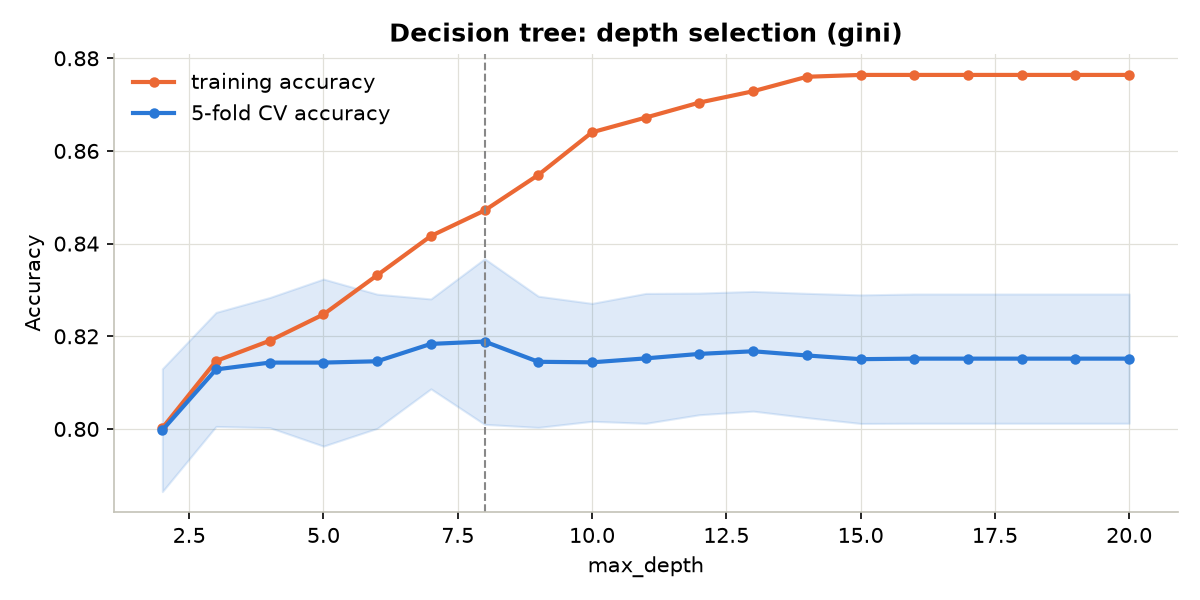

In [60]:
show('dt_depth_curve.png')

In [61]:
# ---- final model -----------------------------------------------------
clf = DecisionTreeClassifier(criterion=best.criterion, max_depth=int(best.depth),
                             min_samples_leaf=20, random_state=RANDOM_STATE)
t0 = time.perf_counter(); clf.fit(X[tr], y[tr]); t_fit = time.perf_counter() - t0
pred = clf.predict(X[te])
acc = accuracy_score(y[te], pred)
mf1 = f1_score(y[te], pred, average="macro")
wf1 = f1_score(y[te], pred, average="weighted")
kappa = cohen_kappa_score(y[te], pred)
base = pd.Series(y[tr]).value_counts(normalize=True).max()
log(f"\nFINAL MODEL on held-out test storms: accuracy={acc:.4f}, macro-F1={mf1:.4f}, "
    f"weighted-F1={wf1:.4f}, Cohen kappa={kappa:.4f}  (majority-class baseline={base:.4f}); "
    f"leaves={clf.get_n_leaves()}, fit time={t_fit:.3f}s")
rep = classification_report(y[te], pred, labels=CLASSES, digits=4)
log("\nClassification report (precision / recall / F1 per class):\n" + rep)
cm = confusion_matrix(y[te], pred, labels=CLASSES)
log("Confusion matrix (rows = actual, cols = predicted) " + str(CLASSES) + "\n" + str(cm))

fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES,
            cbar=False, ax=ax, linewidths=1, linecolor="white")
ax.set(xlabel="Predicted", ylabel="Actual", title=f"Confusion matrix (test acc = {acc:.3f})")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "dt_confusion_matrix.png"), dpi=150); plt.close(fig)

imp = pd.Series(clf.feature_importances_, index=FEATURES).sort_values()
log(f"\nFeature importance (total {best.criterion} impurity reduction):\n" + imp[::-1].round(4).to_string())
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp.values, color="#2a78d6", height=.6)
ax.set(xlabel="Importance", title="Decision tree feature importance")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e1e0d9")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "dt_feature_importance.png"), dpi=150); plt.close(fig)


FINAL MODEL on held-out test storms: accuracy=0.8098, macro-F1=0.7818, weighted-F1=0.8101, Cohen kappa=0.7246  (majority-class baseline=0.4047); leaves=125, fit time=0.136s

Classification report (precision / recall / F1 per class):
              precision    recall  f1-score   support

          TD     0.7910    0.7755    0.7831      1737
          TS     0.7695    0.8020    0.7854      3081
          HU     0.9121    0.8833    0.8975      2374
          EX     0.6740    0.6490    0.6613       567

    accuracy                         0.8098      7759
   macro avg     0.7867    0.7775    0.7818      7759
weighted avg     0.8110    0.8098    0.8101      7759

Confusion matrix (rows = actual, cols = predicted) ['TD', 'TS', 'HU', 'EX']
[[1347  356    2   32]
 [ 325 2471  180  105]
 [   0  236 2097   41]
 [  31  148   20  368]]



Feature importance (total gini impurity reduction):
Pressure             0.7568
Latitude             0.1343
Longitude            0.0596
HoursSinceGenesis    0.0197
Month                0.0103
dPressure6h          0.0080
Heading              0.0064
Speed_kmh            0.0039
BasinCode            0.0011


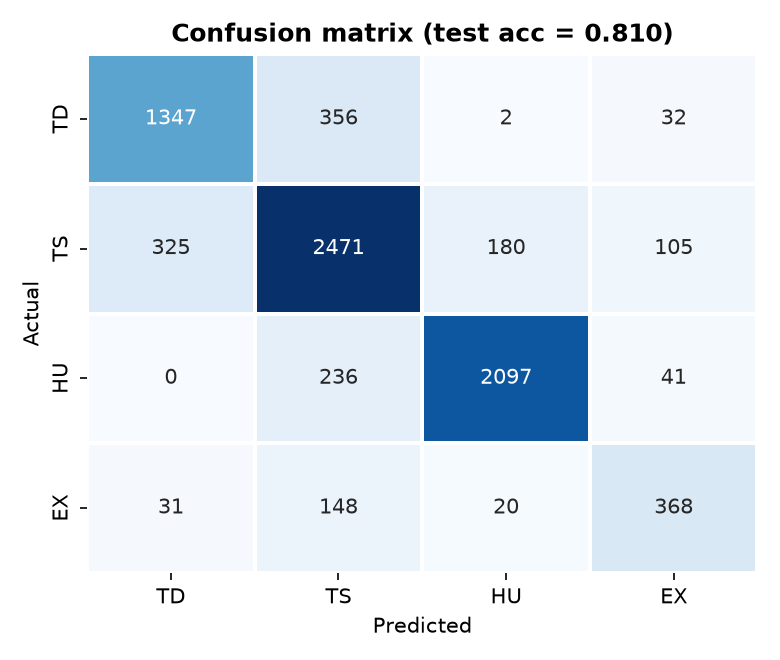

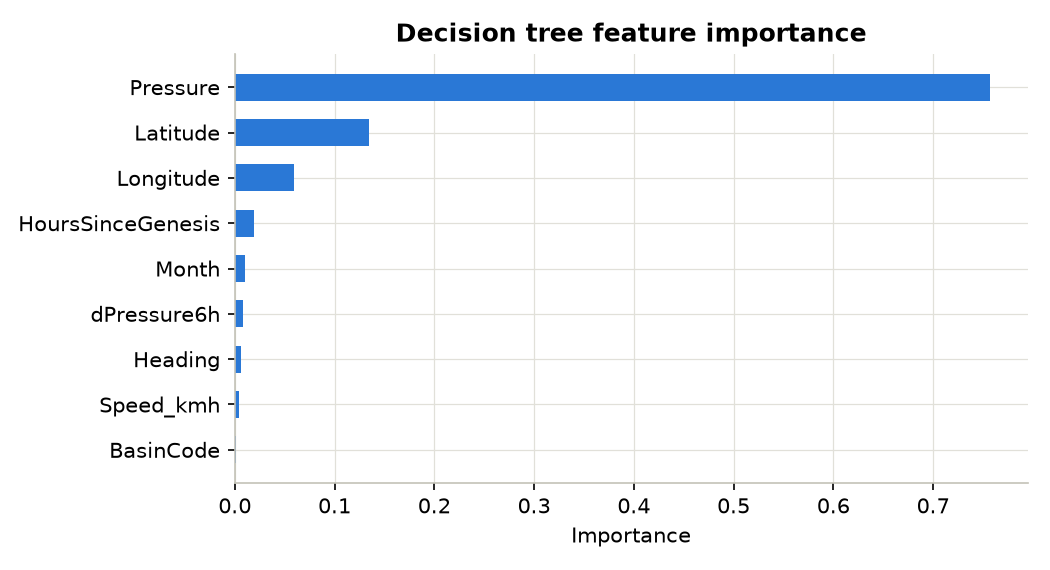

In [62]:
show('dt_confusion_matrix.png', 'dt_feature_importance.png')

In [63]:
# ---- interpretable shallow tree for IF-THEN rules ------------------------
small = DecisionTreeClassifier(criterion=best.criterion, max_depth=4, min_samples_leaf=50,
                               random_state=RANDOM_STATE).fit(X[tr], y[tr])
s_acc = accuracy_score(y[te], small.predict(X[te]))
log(f"\nInterpretable depth-4 tree: test accuracy = {s_acc:.4f}, leaves = {small.get_n_leaves()}")
log("\nTree structure (export_text):\n" + export_text(small, feature_names=FEATURES, decimals=1))

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(small, feature_names=FEATURES, class_names=list(small.classes_), filled=True,
          rounded=True, fontsize=7, impurity=False, proportion=True, max_depth=3, ax=ax)
ax.set_title("Decision tree (top 3 levels of the depth-4 interpretable tree)", fontsize=14)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "dt_tree.png"), dpi=130); plt.close(fig)

# extract IF-THEN rules (one per leaf)
t = small.tree_
rules = []

def simplify(bounds):
    """Collapse the path conditions to one tight interval per feature,
    e.g. 'P > 988.5 AND P > 1005.5' -> 'Pressure > 1005.5'."""
    parts = []
    for f in FEATURES:
        if f not in bounds:
            continue
        lo, hi = bounds[f]
        if lo is not None and hi is not None:
            parts.append(f"{lo:.1f} < {f} <= {hi:.1f}")
        elif lo is not None:
            parts.append(f"{f} > {lo:.1f}")
        else:
            parts.append(f"{f} <= {hi:.1f}")
    return " AND ".join(parts)

def walk(node, bounds):
    if t.children_left[node] == -1:
        dist = t.value[node][0]
        k = int(np.argmax(dist))
        rules.append({"rule": "IF " + simplify(bounds) + f" THEN Status = {small.classes_[k]}",
                      "samples": int(t.n_node_samples[node]),
                      "confidence": round(float(dist[k] / dist.sum()), 3)})
        return
    f, thr = FEATURES[t.feature[node]], float(t.threshold[node])
    lo, hi = bounds.get(f, (None, None))
    walk(t.children_left[node], {**bounds, f: (lo, thr if hi is None else min(hi, thr))})
    walk(t.children_right[node], {**bounds, f: (thr if lo is None else max(lo, thr), hi)})
walk(0, {})
rdf = pd.DataFrame(rules).sort_values("samples", ascending=False)
rdf.to_csv(f"{CLEAN_DIR}/dt_rules.csv", index=False)
pd.set_option("display.max_colwidth", 200); pd.set_option("display.width", 250)
log(f"\nIF-THEN rules extracted from the depth-4 tree ({len(rdf)} leaves), by coverage:")
for r in rdf.itertuples():
    log(f"  [{r.samples:5d} obs, conf {r.confidence:.2f}] {r.rule}")

save_json({"n_rows": len(d), "n_storms": int(d.ID.nunique()), "train_rows": len(tr), "test_rows": len(te),
           "class_dist": d.Status.value_counts().to_dict(), "best_criterion": best.criterion,
           "best_depth": int(best.depth), "cv_acc": round(best.cv_acc, 4), "test_acc": round(acc, 4),
           "macro_f1": round(mf1, 4), "weighted_f1": round(wf1, 4), "kappa": round(kappa, 4),
           "baseline": round(base, 4), "leaves": int(clf.get_n_leaves()), "fit_s": round(t_fit, 3),
           "small_acc": round(s_acc, 4), "importance": imp[::-1].round(4).to_dict(),
           "report": classification_report(y[te], pred, labels=CLASSES, output_dict=True),
           "cm": cm.tolist()}, "decision_tree")
log.close()


Interpretable depth-4 tree: test accuracy = 0.8117, leaves = 16

Tree structure (export_text):
|--- Pressure <= 988.5
|   |--- Latitude <= 43.0
|   |   |--- Pressure <= 979.5
|   |   |   |--- Latitude <= 38.8
|   |   |   |   |--- class: HU
|   |   |   |--- Latitude >  38.8
|   |   |   |   |--- class: HU
|   |   |--- Pressure >  979.5
|   |   |   |--- Latitude <= 20.4
|   |   |   |   |--- class: HU
|   |   |   |--- Latitude >  20.4
|   |   |   |   |--- class: HU
|   |--- Latitude >  43.0
|   |   |--- Latitude <= 47.1
|   |   |   |--- Heading <= 58.3
|   |   |   |   |--- class: HU
|   |   |   |--- Heading >  58.3
|   |   |   |   |--- class: EX
|   |   |--- Latitude >  47.1
|   |   |   |--- Latitude <= 50.1
|   |   |   |   |--- class: EX
|   |   |   |--- Latitude >  50.1
|   |   |   |   |--- class: EX
|--- Pressure >  988.5
|   |--- Pressure <= 1005.5
|   |   |--- Latitude <= 39.0
|   |   |   |--- Pressure <= 1002.5
|   |   |   |   |--- class: TS
|   |   |   |--- Pressure >  1002.5
|   |


IF-THEN rules extracted from the depth-4 tree (16 leaves), by coverage:
  [ 5202 obs, conf 0.83] IF Latitude <= 39.0 AND 988.5 < Pressure <= 1002.5 THEN Status = TS
  [ 3454 obs, conf 0.99] IF Latitude <= 38.8 AND Pressure <= 979.5 THEN Status = HU
  [ 2287 obs, conf 0.66] IF Latitude <= 39.0 AND 1002.5 < Pressure <= 1005.5 THEN Status = TS
  [ 2142 obs, conf 0.89] IF Latitude <= 35.0 AND Longitude <= -80.4 AND Pressure > 1005.5 THEN Status = TD
  [ 1385 obs, conf 0.63] IF Latitude <= 34.5 AND Longitude > -80.4 AND Pressure > 1005.5 THEN Status = TD
  [  954 obs, conf 0.71] IF 20.4 < Latitude <= 43.0 AND 979.5 < Pressure <= 988.5 THEN Status = HU
  [  805 obs, conf 0.92] IF Latitude <= 20.4 AND 979.5 < Pressure <= 988.5 THEN Status = HU
  [  332 obs, conf 0.86] IF Latitude > 43.0 AND 988.5 < Pressure <= 1005.5 THEN Status = EX
  [  276 obs, conf 0.54] IF Latitude > 34.5 AND Longitude > -80.4 AND Pressure > 1005.5 THEN Status = EX
  [  257 obs, conf 0.47] IF 39.0 < Latitude <= 43.0 AND

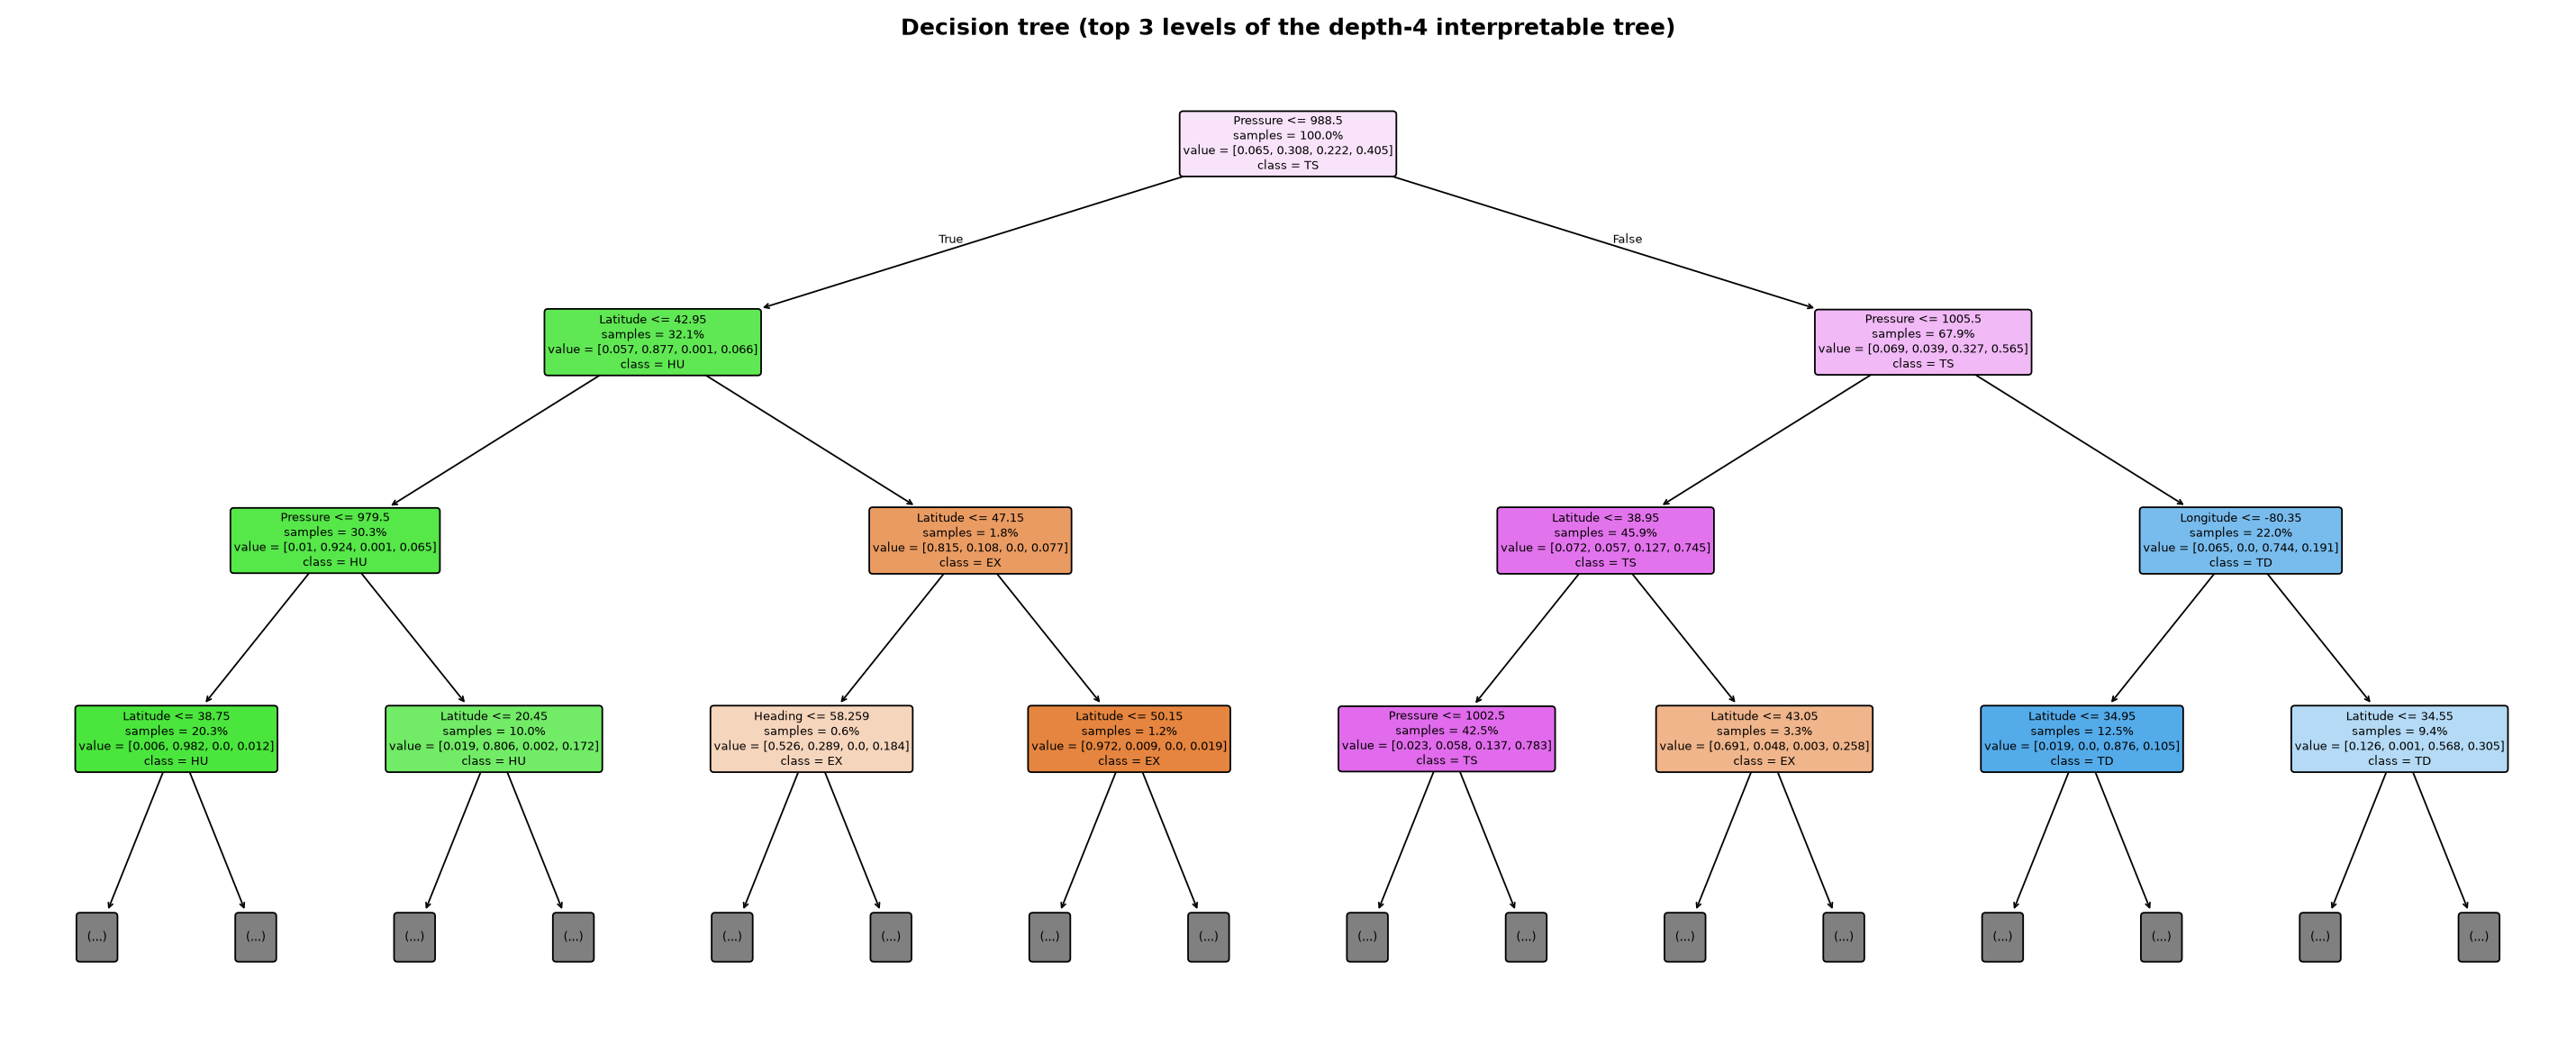

In [64]:
show('dt_tree.png')

**Interpretation (Decision Tree)**
* Test accuracy **0.810** on storms never seen in training (kappa 0.725, macro-F1 0.782), against a majority-class
  baseline of 0.405. The CV estimate (0.819) matches the test score, so the model generalises.
* HU is recognised best (F1 0.90) and EX is hardest (F1 0.66). Errors occur almost only between neighbouring
  intensity classes (TD↔TS, TS↔HU).
* Pressure carries 76 % of the importance and latitude 13 %. The rules read like forecaster heuristics, e.g.
  *IF Latitude ≤ 38.8 AND Pressure ≤ 979.5 THEN HU* (99 %), *IF Latitude > 50.1 AND Pressure ≤ 988.5 THEN EX* (100 %).
* Training accuracy keeps rising with depth while CV accuracy levels off after depth 8, so deeper trees over-fit.

## 5. DBSCAN clustering of storm genesis locations
Genesis regions have irregular shapes and an unknown number, and isolated genesis events should be treated as
noise. DBSCAN handles all of this; k-means does not. Each storm's first fix is clustered with the **haversine**
(great-circle) distance. MinPts = 15, and eps comes from the knee of the k-distance graph, taken on the main body
of the curve (the top 5 % outlier tail would push the knee to ≈430 km and merge the two oceans into one cluster).
A second, finer DBSCAN pass inside each cluster finds the genesis hot-spots, and a **dendrogram** (Ward linkage)
groups the hot-spots by their profiles.

In [65]:
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram

from common import STORMS, FIG_DIR, CLEAN_DIR, Logger, save_json

log = Logger("06_dbscan")
R = 6371.0
MIN_PTS = 15
COLS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

storms = pd.read_csv(STORMS)
X = np.radians(storms[["GenesisLat", "GenesisLon"]].values)       # (lat, lon) in radians
log(f"{len(storms)} genesis points; metric = haversine; MinPts = {MIN_PTS}")

2845 genesis points; metric = haversine; MinPts = 15


In [66]:
# ---- 1. k-distance graph to choose eps ------------------------------------
nn = NearestNeighbors(n_neighbors=MIN_PTS, metric="haversine").fit(X)
kd = np.sort(nn.kneighbors(X)[0][:, -1] * R)
# knee = point of maximum distance to the chord joining first and last point.
# The top 5 % of k-distances are isolated outliers whose huge values dominate the
# curvature (a knee found on the full curve lands at ~430 km and chains the Atlantic
# and Pacific into ONE cluster), so the knee is searched on the main body (lowest 95 %).
# The knee is stable: cutting at 90 % instead of 95 % gives the same point.
body = kd[:int(0.95 * len(kd))]
x = np.arange(len(body)); y = body
p1, p2 = np.array([0, y[0]]), np.array([len(y) - 1, y[-1]])
chord = (p2 - p1) / np.linalg.norm(p2 - p1)
vec = np.stack([x, y], 1) - p1
dist = np.abs(vec[:, 0] * chord[1] - vec[:, 1] * chord[0])
knee = int(np.argmax(dist))
EPS_KM = float(np.round(kd[knee] / 10) * 10)
log(f"k-distance knee at point {knee}: {kd[knee]:.1f} km -> eps = {EPS_KM:.0f} km")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(len(kd)), kd, color="#2a78d6", lw=2)
ax.axvline(len(body), color="#888", ls=":", lw=1)
ax.text(len(body) - 10, kd.max() * .9, "outlier tail (top 5 %)", ha="right", fontsize=8, color="#555")
ax.axhline(EPS_KM, color="#eb6834", ls="--", lw=1.2, label=f"eps = {EPS_KM:.0f} km (knee)")
ax.scatter([knee], [kd[knee]], color="#eb6834", zorder=3)
ax.set(xlabel="Genesis points sorted by distance", ylabel=f"Distance to {MIN_PTS}-th neighbour (km)",
       title="k-distance graph for choosing eps")
ax.legend(frameon=False); ax.grid(color="#e1e0d9"); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "db_kdistance.png"), dpi=150); plt.close(fig)

k-distance knee at point 2131: 228.0 km -> eps = 230 km


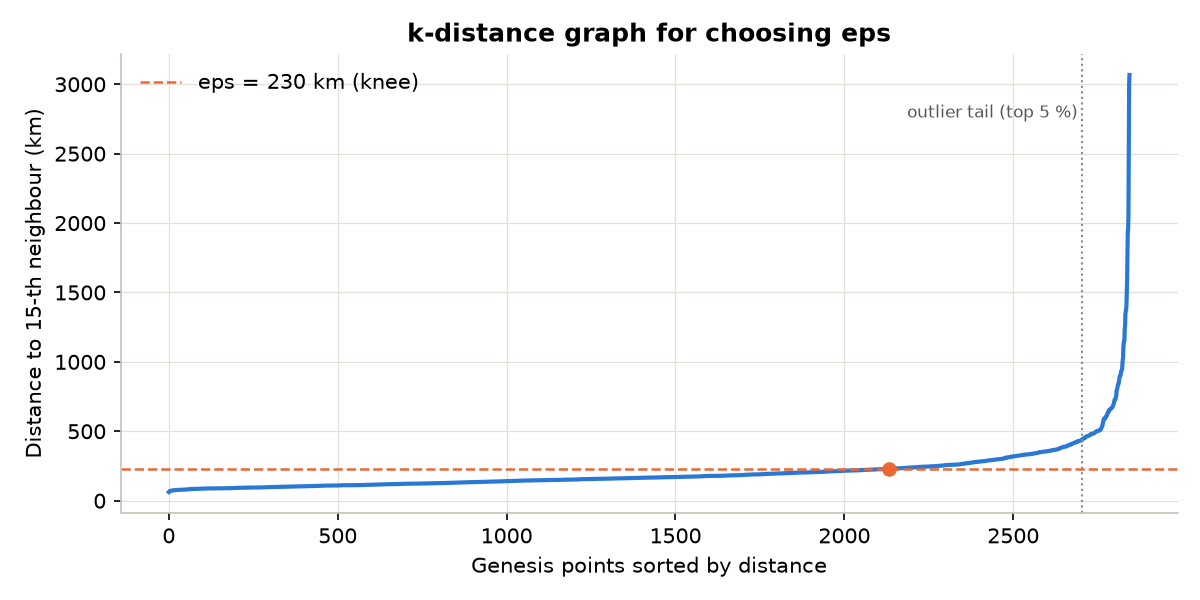

In [67]:
show('db_kdistance.png')

In [68]:
# ---- 2. Sensitivity of the result to eps / MinPts -----------------------
grid = []
for e in (EPS_KM * .6, EPS_KM * .8, EPS_KM, EPS_KM * 1.2, EPS_KM * 1.5):
    for mp in (10, 15, 25):
        lab = DBSCAN(eps=e / R, min_samples=mp, metric="haversine").fit_predict(X)
        grid.append({"eps_km": round(e), "MinPts": mp, "clusters": len(set(lab)) - (-1 in lab),
                     "noise_%": round(100 * (lab == -1).mean(), 1)})
gdf = pd.DataFrame(grid)
log("\nParameter sensitivity:\n" + gdf.to_string(index=False))


Parameter sensitivity:
 eps_km  MinPts  clusters  noise_%
    138      10        17     30.7
    138      15        18     49.2
    138      25         4     73.7
    184      10         5     15.0
    184      15        10     24.9
    184      25         9     48.1
    230      10         2      9.8
    230      15         2     13.3
    230      25         7     26.2
    276      10         2      5.6
    276      15         3      9.5
    276      25         6     15.5
    345      10         2      3.1
    345      15         2      4.8
    345      25         1      9.5


In [69]:
# ---- 3. Final DBSCAN ------------------------------------------------------
db = DBSCAN(eps=EPS_KM / R, min_samples=MIN_PTS, metric="haversine").fit(X)
lab = db.labels_
storms["Cluster"] = lab
n_cl = len(set(lab)) - (-1 in lab)
core = np.zeros(len(lab), bool); core[db.core_sample_indices_] = True
log(f"\nFINAL: eps = {EPS_KM:.0f} km, MinPts = {MIN_PTS} -> {n_cl} clusters, "
    f"{(lab == -1).sum()} noise points ({100 * (lab == -1).mean():.1f} %), "
    f"{core.sum()} core / {((lab != -1) & ~core).sum()} border points")
m = lab != -1
sil = silhouette_score(X[m], lab[m], metric="haversine", sample_size=min(2000, m.sum()), random_state=0)
log(f"Silhouette coefficient (non-noise points, haversine) = {sil:.3f}")

# Cluster profiles (relabel clusters by size so the largest is C0)
order = storms[m].Cluster.value_counts().index.tolist()
remap = {c: i for i, c in enumerate(order)}; remap[-1] = -1
storms["Cluster"] = storms.Cluster.map(remap)
prof = storms[storms.Cluster >= 0].groupby("Cluster").agg(
    storms=("Basin", "size"), atlantic_pct=("Basin", lambda s: round(100 * (s == "Atlantic").mean(), 1)),
    lat_mean=("GenesisLat", "mean"), lon_mean=("GenesisLon", "mean"),
    lat_min=("GenesisLat", "min"), lat_max=("GenesisLat", "max"),
    lon_min=("GenesisLon", "min"), lon_max=("GenesisLon", "max"),
    peak_month=("GenesisMonth", lambda s: int(s.mode()[0])),
    mean_maxwind=("MaxWind", "mean"), hurricane_pct=("BecameHurricane", lambda s: round(100 * s.mean(), 1)),
    major_pct=("MaxWind", lambda s: round(100 * (s >= 96).mean(), 1)),
    landfall_pct=("Landfall", lambda s: round(100 * s.mean(), 1)),
    median_duration_h=("DurationH", "median")).round(1)
noise = storms[storms.Cluster == -1]
log("\nCluster profiles:\n" + prof.to_string())
log(f"\nNoise storms: n={len(noise)}, mean genesis lat={noise.GenesisLat.mean():.1f}, "
    f"hurricane %={100 * noise.BecameHurricane.mean():.1f}, mean max wind={noise.MaxWind.mean():.1f} kt")
storms[["Name", "Basin", "Year", "GenesisLat", "GenesisLon", "MaxWind", "Cluster"]].to_csv(
    f"{CLEAN_DIR}/dbscan_genesis_clusters.csv")


FINAL: eps = 230 km, MinPts = 15 -> 2 clusters, 379 noise points (13.3 %), 2140 core / 326 border points


Silhouette coefficient (non-noise points, haversine) = 0.447

Cluster profiles:
         storms  atlantic_pct  lat_mean  lon_mean  lat_min  lat_max  lon_min  lon_max  peak_month  mean_maxwind  hurricane_pct  major_pct  landfall_pct  median_duration_h
Cluster                                                                                                                                                                   
0          1549         100.0      19.4     -66.2      8.0     35.5    -98.0    -16.0           9          68.6           50.1       18.5          36.9              132.0
1           917           0.4      13.7    -105.7      7.8     22.0   -127.7    -89.0           7          68.7           50.5       20.3           7.4              132.0

Noise storms: n=379, mean genesis lat=22.3, hurricane %=41.7, mean max wind=62.4 kt


In [70]:
# ---- 4. Cluster map ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 4.8))
nz = storms[storms.Cluster == -1]
ax.scatter(nz.GenesisLon, nz.GenesisLat, s=8, color="#b5b4ac", marker="x", lw=.8,
           label=f"noise ({len(nz)})")
for c in range(n_cl):
    s = storms[storms.Cluster == c]
    col = COLS[c % len(COLS)]
    ax.scatter(s.GenesisLon, s.GenesisLat, s=9, color=col, alpha=.75, linewidths=0,
               label=f"C{c} ({len(s)})")
    ax.annotate(f"C{c}", (prof.loc[c, "lon_mean"], prof.loc[c, "lat_mean"]), fontsize=10,
                fontweight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=.2", fc="white", ec=col, lw=1.2))
ax.set(xlim=(-185, 5), ylim=(0, 55), xlabel="Longitude", ylabel="Latitude",
       title=f"DBSCAN genesis clusters (eps = {EPS_KM:.0f} km, MinPts = {MIN_PTS})")
ax.set_aspect("equal"); ax.grid(color="#e1e0d9"); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=1, bbox_to_anchor=(1.01, 1), loc="upper left", markerscale=1.6)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "db_clusters_map.png"), dpi=150, bbox_inches="tight"); plt.close(fig)

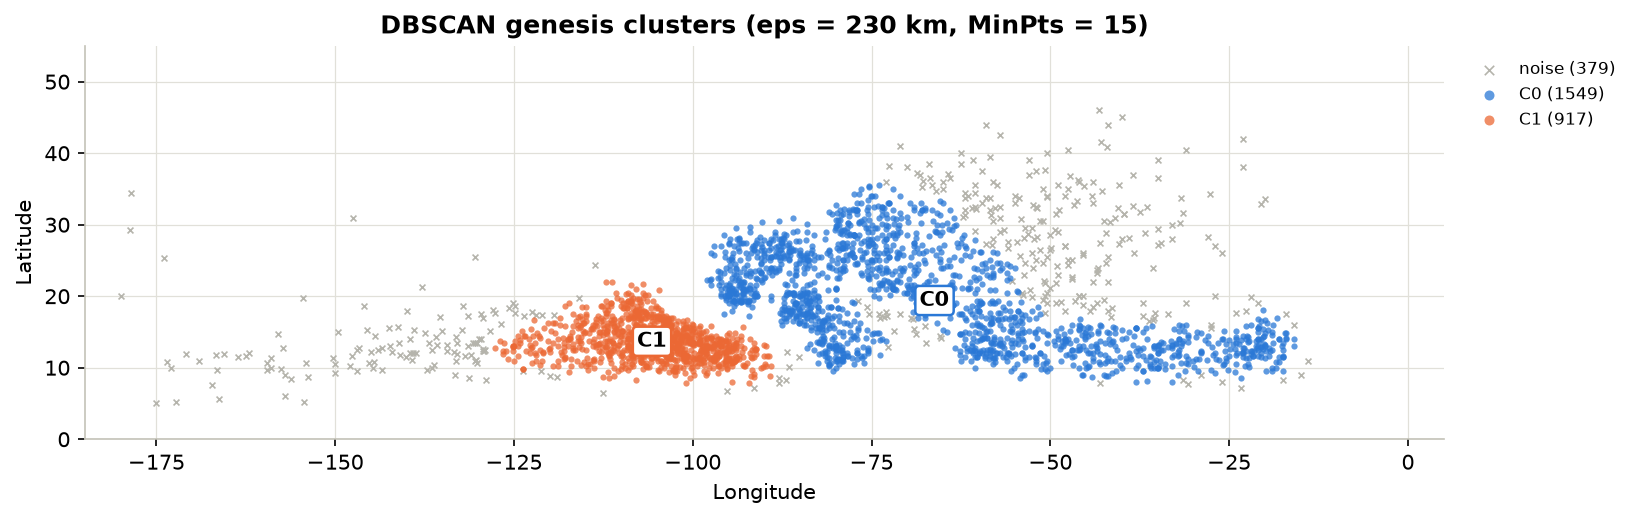

In [71]:
show('db_clusters_map.png')

In [72]:
# ---- 5. Level-2 DBSCAN: density varies inside each basin, so each level-1
#         cluster is re-clustered at a finer scale (eps2 = 0.65 * eps) to reveal the
#         individual genesis hot-spots ("multi-scale DBSCAN").
EPS2_KM = round(0.65 * EPS_KM)
storms["SubCluster"] = "noise"
sub_rows = []
for c in range(n_cl):
    idx = storms.index[storms.Cluster == c]
    l2 = DBSCAN(eps=EPS2_KM / R, min_samples=MIN_PTS, metric="haversine").fit_predict(X[idx])
    sizes = pd.Series(l2[l2 >= 0]).value_counts()
    for rank, k in enumerate(sizes.index):
        storms.loc[idx[l2 == k], "SubCluster"] = f"C{c}.{rank}"
    storms.loc[idx[l2 == -1], "SubCluster"] = f"C{c}.diffuse"
sub = storms[storms.SubCluster.str.match(r"^C\d+\.\d+$")]
sprof = sub.groupby("SubCluster").agg(
    storms=("Basin", "size"), lat_mean=("GenesisLat", "mean"), lon_mean=("GenesisLon", "mean"),
    peak_month=("GenesisMonth", lambda s: int(s.mode()[0])), mean_maxwind=("MaxWind", "mean"),
    hurricane_pct=("BecameHurricane", lambda s: round(100 * s.mean(), 1)),
    major_pct=("MaxWind", lambda s: round(100 * (s >= 96).mean(), 1)),
    landfall_pct=("Landfall", lambda s: round(100 * s.mean(), 1)),
    median_duration_h=("DurationH", "median")).round(1)
log(f"\nLevel-2 DBSCAN inside each cluster (eps2 = {EPS2_KM} km, MinPts = {MIN_PTS}):")
log(storms.SubCluster.value_counts().to_string())
log("\nSub-cluster (genesis hot-spot) profiles:\n" + sprof.to_string())

fig, ax = plt.subplots(figsize=(11, 4.8))
rest = storms[~storms.index.isin(sub.index)]
ax.scatter(rest.GenesisLon, rest.GenesisLat, s=7, color="#cfcec6", lw=0, label="diffuse / noise")
for i, (k, s) in enumerate(sub.groupby("SubCluster")):
    col = COLS[i % len(COLS)]
    ax.scatter(s.GenesisLon, s.GenesisLat, s=9, color=col, alpha=.8, lw=0, label=f"{k} ({len(s)})")
    ax.annotate(k, (sprof.loc[k, "lon_mean"], sprof.loc[k, "lat_mean"]), fontsize=8, fontweight="bold",
                ha="center", va="center", bbox=dict(boxstyle="round,pad=.2", fc="white", ec=col, lw=1.2))
ax.set(xlim=(-185, 5), ylim=(0, 55), xlabel="Longitude", ylabel="Latitude",
       title=f"Level-2 DBSCAN: genesis hot-spots (eps = {EPS2_KM} km, MinPts = {MIN_PTS})")
ax.set_aspect("equal"); ax.grid(color="#e1e0d9"); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left", markerscale=1.6)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "db_subclusters_map.png"), dpi=150, bbox_inches="tight"); plt.close(fig)


Level-2 DBSCAN inside each cluster (eps2 = 150 km, MinPts = 15):
SubCluster
C1.0          766
C0.diffuse    685
noise         379
C0.0          226
C0.1          208
C1.diffuse    131
C0.2          125
C0.3           96
C0.4           68
C0.5           32
C0.6           30
C0.7           29
C0.8           22
C1.1           20
C0.9           15
C0.10          13

Sub-cluster (genesis hot-spot) profiles:
            storms  lat_mean  lon_mean  peak_month  mean_maxwind  hurricane_pct  major_pct  landfall_pct  median_duration_h
SubCluster                                                                                                                 
C0.0           226      23.6     -90.4           9          55.2           31.0        4.9          63.3               84.0
C0.1           208      16.2     -83.0          10          66.1           48.6       14.9          48.1              132.0
C0.10           13      18.5     -60.2           8          73.1           61.5       23.1       

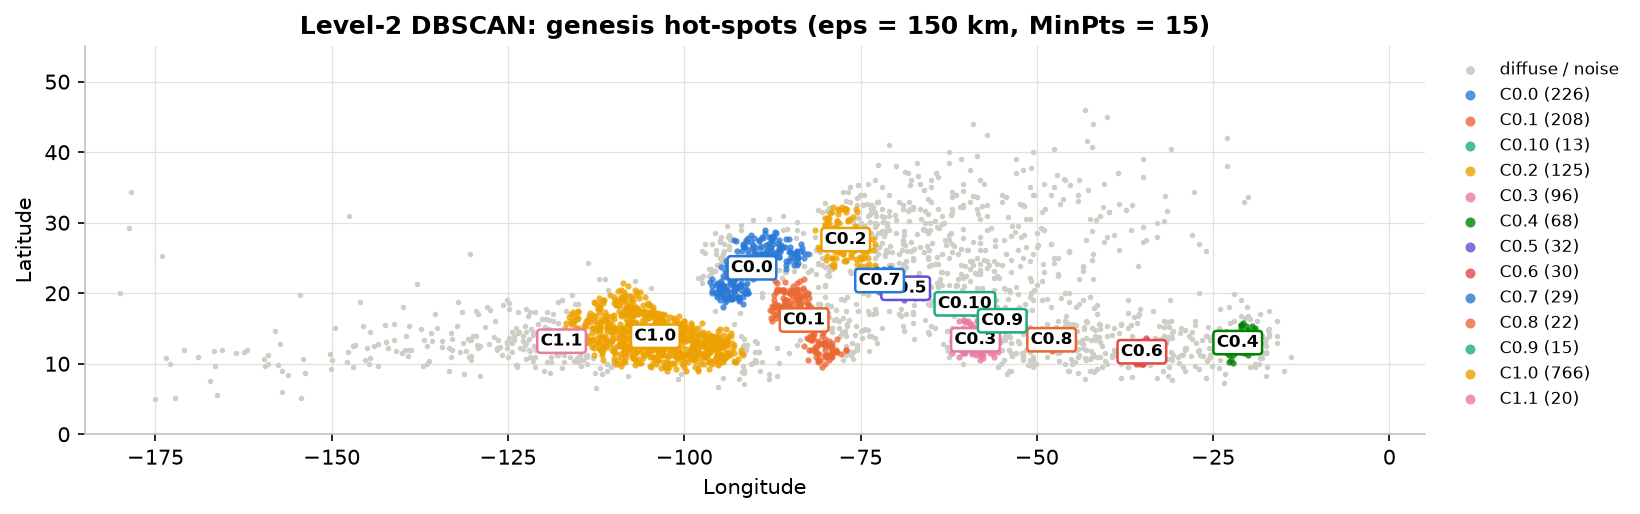

In [73]:
show('db_subclusters_map.png')

In [74]:
# ---- 6. Dendrogram of the hot-spots (Ward linkage on standardised profiles) --
feat = sprof[["lat_mean", "lon_mean", "peak_month", "mean_maxwind", "hurricane_pct", "landfall_pct",
              "median_duration_h"]]
Z = linkage(StandardScaler().fit_transform(feat), method="ward")
fig, ax = plt.subplots(figsize=(8, 4.2))
dendrogram(Z, labels=[f"{k} (n={sprof.loc[k, 'storms']})" for k in sprof.index], ax=ax,
           color_threshold=0.6 * Z[:, 2].max(), above_threshold_color="#888", leaf_rotation=30)
ax.set(ylabel="Ward linkage distance",
       title="Dendrogram of DBSCAN genesis hot-spots (profile similarity)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "db_dendrogram.png"), dpi=150); plt.close(fig)
log("\nWard linkage matrix (cluster i, cluster j, distance, size):\n" + np.round(Z, 3).__str__())
log("Dendrogram leaf order: " + str(dendrogram(Z, no_plot=True, labels=list(sprof.index))["ivl"]))

save_json({"eps_km": EPS_KM, "min_pts": MIN_PTS, "n_clusters": n_cl, "noise": int((lab == -1).sum()),
           "noise_pct": round(100 * (lab == -1).mean(), 1), "core": int(core.sum()),
           "silhouette": round(float(sil), 3), "profiles": prof.reset_index().to_dict(orient="records"),
           "grid": grid, "eps2_km": EPS2_KM, "sub_profiles": sprof.reset_index().to_dict(orient="records"),
           "noise_hu_pct": round(100 * noise.BecameHurricane.mean(), 1),
           "noise_lat": round(noise.GenesisLat.mean(), 1)}, "dbscan")
log.close()


Ward linkage matrix (cluster i, cluster j, distance, size):
[[ 7.     9.     1.058  2.   ]
 [ 6.     8.     1.116  2.   ]
 [ 2.     4.     1.707  2.   ]
 [ 1.    14.     1.999  3.   ]
 [ 0.     3.     2.064  2.   ]
 [13.    15.     2.263  4.   ]
 [10.    18.     2.696  5.   ]
 [ 5.    19.     2.942  6.   ]
 [11.    12.     3.752  2.   ]
 [16.    17.     4.57   5.   ]
 [21.    22.     6.105  7.   ]
 [20.    23.     8.67  13.   ]]
Dendrogram leaf order: ['C0.4', 'C0.9', 'C0.6', 'C0.8', 'C0.10', 'C0.3', 'C1.0', 'C1.1', 'C0.1', 'C0.5', 'C0.7', 'C0.0', 'C0.2']


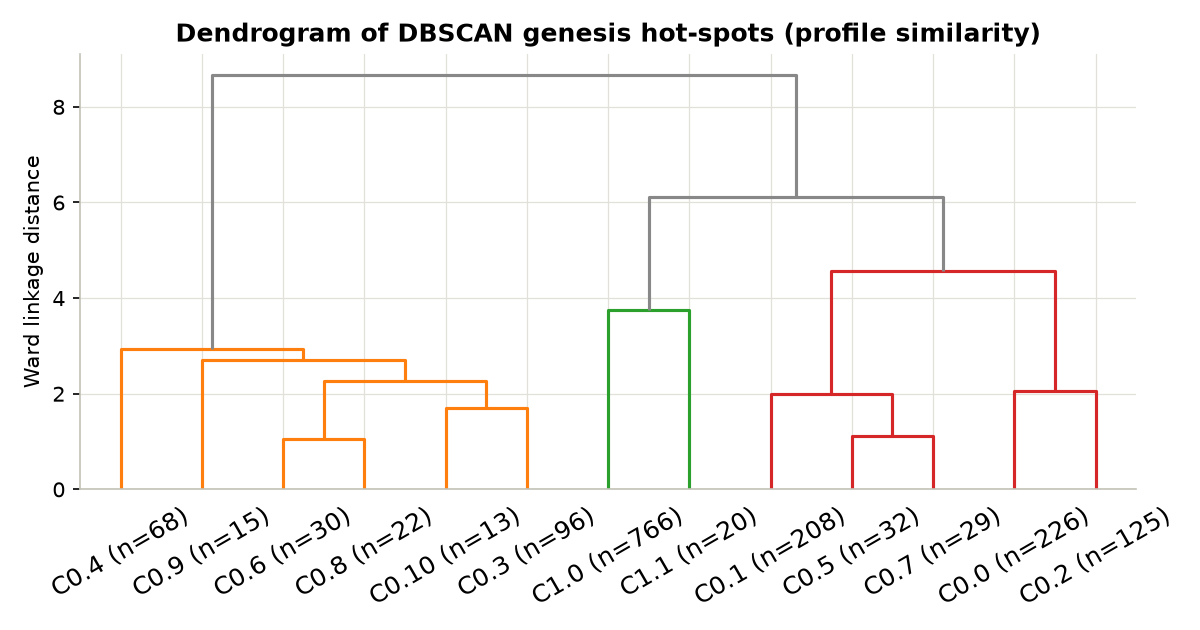

In [75]:
show('db_dendrogram.png')

**Interpretation (DBSCAN)**
* eps = 230 km gives 2 clusters, 13.3 % noise and a silhouette of 0.447. Without being given any basin label,
  DBSCAN separates the **Atlantic (100 % Atlantic)** and **Pacific (0.4 % Atlantic)** nurseries: the low-density
  gap over Central America forms a natural boundary.
* Noise storms form further north (mean 22.3°N) and become hurricanes less often (41.7 %).
* The Cape Verde hot-spot **C0.4** (≈21.5°W) produces the longest-lived (282 h) and most intense (42.6 % major)
  storms, with few landfalls. The **Gulf of Mexico C0.0** produces short, weak storms, but 63 % make landfall.
* The dendrogram shows three families: the deep-tropical Atlantic main development region, the eastern Pacific,
  and near-land western Atlantic / Caribbean / Gulf genesis.

## 6. Closed frequent itemsets and closed rules with A-CLOSE
**A-CLOSE (Pasquier et al. 1999)** mines *generators* level by level. A candidate is pruned if it is infrequent,
or if its support equals that of one of its subsets (then it lies in that subset's closure). One final pass
computes the closures h(g) = ∩{t : g ⊆ t} of the generators from level i−1 onwards. The closures form the set of
**closed frequent itemsets (CFIs)**. Rules: **exact** g ⇒ h(g)∖g (100 %) and **approximate** g ⇒ C∖g for closed
C ⊃ h(g). The result is verified against the closed sets derived from DIC's frequent itemsets.

In [76]:
import time
from itertools import combinations
import pandas as pd

from common import MIN_SUPPORT, MIN_CONFIDENCE, CLEAN_DIR, Logger, save_json, load_transactions
from arm_common import (build_vocab, encode, count_kernel, closure_kernel, apriori_gen,
                        mask_to_items, fmt_set)


def aclose(count_fn, closure_fn, n_items, min_count, log=print):
    """
    Generic A-CLOSE driver. The data access is abstracted:
      count_fn(list_of_masks)   -> list of support counts
      closure_fn(list_of_masks) -> list of closure masks
    so the same driver runs sequentially (Python) or distributed (Spark).
    Itemsets are handled as sorted tuples of item indices internally.
    Returns generators {tuple: support}, closed {mask: support}, gen_closure {tuple: mask}, level_i
    """
    tup2mask = lambda t: sum(1 << j for j in t)
    # ---- level 1 --------------------------------------------------------
    c1 = [(j,) for j in range(n_items)]
    sup = count_fn([tup2mask(c) for c in c1])
    G = {c: s for c, s in zip(c1, sup) if s >= min_count}
    generators = dict(G)
    log(f"   level 1: {n_items} candidates -> {len(G)} frequent generators")
    level_i, k = None, 1
    # ---- levels k+1 -----------------------------------------------------
    while G:
        cands = apriori_gen(G.keys(), k)
        if not cands:
            break
        sup = count_fn([tup2mask(c) for c in cands])
        newG, pruned_eq, infreq = {}, 0, 0
        for c, s in zip(cands, sup):
            if s < min_count:
                infreq += 1
                continue
            # not a generator if it has the same support as one of its k-subsets
            if any(G[sub] == s for sub in combinations(c, k)):
                pruned_eq += 1
                if level_i is None:
                    level_i = k + 1
                continue
            newG[c] = s
        log(f"   level {k + 1}: {len(cands)} candidates -> {infreq} infrequent, "
            f"{pruned_eq} non-generators (same support as a subset), {len(newG)} generators")
        generators.update(newG)
        G, k = newG, k + 1
    # ---- closure computation -------------------------------------------
    if level_i is None:
        need = []                                    # every generator is closed
    else:
        need = [g for g in generators if len(g) >= level_i - 1]
    log(f"   first level with a non-generator: i = {level_i}; computing closures of "
        f"{len(need)} generators (levels >= {level_i - 1 if level_i else '-'}) in one pass")
    clos_masks = closure_fn([tup2mask(g) for g in need]) if need else []
    gen_closure = {g: tup2mask(g) for g in generators}
    gen_closure.update(dict(zip(need, clos_masks)))
    closed = {}
    for g, m in gen_closure.items():
        closed[m] = generators[g]
    return generators, closed, gen_closure, level_i


def closed_rules(generators, gen_closure, closed, n, items, min_conf):
    """Exact + approximate rules derived from generators and closed itemsets."""
    exact, approx = [], []
    sup_closed = closed
    for g, sg in generators.items():
        gm = sum(1 << j for j in g)
        hg = gen_closure[g]
        lhs = mask_to_items(gm, items)
        if hg != gm:                                         # exact rule
            rhs = mask_to_items(hg & ~gm, items)
            exact.append({"antecedent": lhs, "consequent": rhs, "support": sg / n,
                          "confidence": 1.0, "type": "exact"})
        for cm, sc in sup_closed.items():                    # approximate rules
            if cm != hg and cm & hg == hg:                   # C strictly contains h(g)
                conf = sc / sg
                if conf >= min_conf:
                    approx.append({"antecedent": lhs, "consequent": mask_to_items(cm & ~gm, items),
                                   "support": sc / n, "confidence": conf, "type": "approximate"})
    return exact, approx


log = __import__("common").Logger("04_aclose")
txns = load_transactions()
items, index = build_vocab(txns)
N, I = len(txns), len(items)
enc = encode(txns, index)
full = (1 << I) - 1
import math
min_count = math.ceil(MIN_SUPPORT * N)
log(f"N = {N} transactions, {I} items; min_support = {MIN_SUPPORT:.0%} (count {min_count}), "
    f"min_confidence = {MIN_CONFIDENCE:.0%}")

passes = {"n": 0}
def count_fn(c):
    passes["n"] += 1
    return count_kernel(enc, c)
def closure_fn(g):
    passes["n"] += 1
    return closure_kernel(enc, g, full)

t0 = time.perf_counter()
gens, closed, gen_clos, lvl_i = aclose(count_fn, closure_fn, I, min_count, log)
t_ac = time.perf_counter() - t0
log(f"\nA-CLOSE finished in {t_ac:.2f} s using {passes['n']} database passes")
log(f"Generators: {len(gens)};  Closed frequent itemsets (CFIs): {len(closed)}")
by_len = pd.Series([bin(m).count("1") for m in closed]).value_counts().sort_index()
log(f"CFIs by size: {by_len.to_dict()}")

N = 74895 transactions, 27 items; min_support = 5% (count 3745), min_confidence = 70%


   level 1: 27 candidates -> 24 frequent generators


   level 2: 276 candidates -> 118 infrequent, 0 non-generators (same support as a subset), 158 generators


   level 3: 533 candidates -> 275 infrequent, 2 non-generators (same support as a subset), 256 generators


   level 4: 235 candidates -> 121 infrequent, 0 non-generators (same support as a subset), 114 generators
   level 5: 17 candidates -> 6 infrequent, 0 non-generators (same support as a subset), 11 generators
   first level with a non-generator: i = 3; computing closures of 539 generators (levels >= 2) in one pass



A-CLOSE finished in 15.79 s using 6 database passes
Generators: 563;  Closed frequent itemsets (CFIs): 563
CFIs by size: {1: 24, 2: 156, 3: 257, 4: 115, 5: 11}


In [77]:
# ---- verification: closed sets from DIC frequent itemsets -------------
fi = pd.read_csv(f"{CLEAN_DIR}/dic_frequent_itemsets.csv")
freq = {frozenset(s.strip("{}").split(", ")): c for s, c in zip(fi.itemset, fi.support_count)}
brute_closed = {s for s, c in freq.items()
                if not any(len(t) == len(s) + 1 and s < t and freq[t] == c for t in freq)}
ac_sets = {mask_to_items(m, items): s for m, s in closed.items()}
ok = set(ac_sets) == brute_closed and all(ac_sets[s] == freq[s] for s in ac_sets)
log(f"Verification: closed itemsets derived from DIC/Apriori frequent itemsets = {len(brute_closed)}; "
    f"A-CLOSE result identical = {ok}")
log(f"Compression: {len(freq)} frequent itemsets are losslessly represented by {len(closed)} CFIs "
    f"({100 * (1 - len(closed) / len(freq)):.1f} % fewer)")

cfi = pd.DataFrame([{"closed_itemset": fmt_set(s), "size": len(s), "support_count": c,
                     "support": round(c / N, 4)} for s, c in ac_sets.items()])
cfi = cfi.sort_values(["size", "support"], ascending=[False, False])
cfi.to_csv(f"{CLEAN_DIR}/aclose_closed_itemsets.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 90)
log("\nLargest closed frequent itemsets:")
log(cfi.head(12).to_string(index=False))

gdf = pd.DataFrame([{"generator": fmt_set(mask_to_items(sum(1 << j for j in g), items)),
                     "closure": fmt_set(mask_to_items(gen_clos[g], items)), "support_count": s}
                    for g, s in gens.items() if gen_clos[g] != sum(1 << j for j in g)])
log(f"\nGenerators whose closure is larger than themselves: {len(gdf)} (first 10)")
log(gdf.sort_values("support_count", ascending=False).head(10).to_string(index=False))

Verification: closed itemsets derived from DIC/Apriori frequent itemsets = 563; A-CLOSE result identical = True
Compression: 566 frequent itemsets are losslessly represented by 563 CFIs (0.5 % fewer)

Largest closed frequent itemsets:
                                                                       closed_itemset  size  support_count  support
   {Basin=Atlantic, Lat=15-25N, Motion=Westward, Season=Aug-Sep, Speed=Medium(15-30)}     5           5707   0.0762
{Basin=Atlantic, Era=1851-1949, Motion=Westward, Season=Aug-Sep, Speed=Medium(15-30)}     5           4635   0.0619
    {Basin=Atlantic, Motion=Westward, Season=Aug-Sep, Speed=Medium(15-30), Status=HU}     5           4118   0.0550
    {Basin=Pacific, Lat=15-25N, Motion=Westward, Season=Aug-Sep, Speed=Medium(15-30)}     5           4089   0.0546
         {Basin=Atlantic, Era=1851-1949, Lat=15-25N, Motion=Westward, Season=Aug-Sep}     5           3996   0.0534
    {Basin=Atlantic, Motion=Westward, Season=Aug-Sep, Speed=Medium(15

In [78]:
# ---- closed association rules ---------------------------------------
exact, approx = closed_rules(gens, gen_clos, closed, N, items, MIN_CONFIDENCE)
def lift(r):   # consequent is a subset of a frequent itemset -> its support is known
    return r["confidence"] / (freq[frozenset(r["consequent"])] / N)
for r in exact + approx:
    r["lift"] = lift(r)
rows = [{"type": r["type"], "IF (antecedent)": fmt_set(r["antecedent"]),
         "THEN (consequent)": fmt_set(r["consequent"]), "support": round(r["support"], 4),
         "confidence": round(r["confidence"], 4), "lift": round(r["lift"], 3)}
        for r in exact + approx]
rdf = pd.DataFrame(rows)
rdf.to_csv(f"{CLEAN_DIR}/aclose_rules.csv", index=False)
log(f"\nClosed-itemset rule basis: {len(exact)} exact rules (conf = 100 %) + "
    f"{len(approx)} approximate rules (conf >= {MIN_CONFIDENCE:.0%}) = {len(rdf)} rules "
    f"(DIC produced {pd.read_csv(f'{CLEAN_DIR}/dic_rules.csv').shape[0]} rules from all frequent itemsets)")
log("\nEXACT rules (100 % confidence), by support:")
log(rdf[rdf.type == "exact"].sort_values("support", ascending=False).head(15)
    .drop(columns="type").to_string(index=False))
log("\nTop APPROXIMATE rules by lift:")
log(rdf[rdf.type == "approximate"].sort_values(["lift", "confidence"], ascending=False).head(15)
    .drop(columns="type").to_string(index=False))

save_json({"time_s": round(t_ac, 2), "passes": passes["n"], "n_generators": len(gens),
           "n_closed": len(closed), "closed_by_len": {int(k): int(v) for k, v in by_len.items()},
           "level_i": lvl_i, "verified": ok, "n_frequent": len(freq),
           "n_exact": len(exact), "n_approx": len(approx)}, "aclose")
log.close()


Closed-itemset rule basis: 3 exact rules (conf = 100 %) + 289 approximate rules (conf >= 70%) = 292 rules (DIC produced 294 rules from all frequent itemsets)



EXACT rules (100 % confidence), by support:
                            IF (antecedent) THEN (consequent)  support  confidence  lift
            {Era=1851-1949, Season=Oct-Dec}  {Basin=Atlantic}   0.0857         1.0 1.536
                 {Era=1851-1949, Lat=>=35N}  {Basin=Atlantic}   0.0595         1.0 1.536
{Era=1851-1949, Lat=>=35N, Motion=Eastward}  {Basin=Atlantic}   0.0518         1.0 1.536

Top APPROXIMATE rules by lift:
                                   IF (antecedent)                 THEN (consequent)  support  confidence  lift
                      {Motion=Eastward, Status=EX}                       {Lat=>=35N}   0.0502      0.8635 6.425
                                       {Status=EX}      {Lat=>=35N, Motion=Eastward}   0.0502      0.7421 6.405
                       {Basin=Atlantic, Status=EX}                       {Lat=>=35N}   0.0550      0.8584 6.387
                                       {Status=EX}       {Basin=Atlantic, Lat=>=35N}   0.0550      0.8130 6.129
      

**Interpretation (A-CLOSE)**
* There are 563 CFIs, identical to the brute-force closed sets (verified). Only 3 of the 566 frequent itemsets are
  not closed: the items rarely imply one another, so the data are **sparse** and closed itemsets compress little
  here. A-CLOSE pays off on dense, correlated data.
* The 3 exact rules say that every pre-1950 record that is late-season or north of 35°N is Atlantic, because the
  Pacific record only starts in 1949.
* The closed basis (292 rules) keeps the strongest DIC rules (EX ⇒ Lat≥35N, Pressure<980 ⇒ HU) while dropping the
  redundant ones.

## 7. PySpark test drive 1 — A-CLOSE on Spark
The A-CLOSE driver is the **same function** as in Part 6. Only the data access changes: the transactions become a
cached, partitioned Spark DataFrame of 64-bit item bit-masks. One distributed aggregation per level computes
`SUM((mask & c) == c)` (support) and `BIT_AND(mask)` (closure) for all candidates in parallel.
On this Windows machine Spark's Python workers cannot start (Microsoft-Store Python 3.13, WinError 10038), so
only JVM-side Spark SQL is used. To emulate growing data the transactions are replicated ×1 … ×32 (up to 2.4 M),
and every run must return the identical closed itemsets.

*Runtime: about 10 minutes (the sequential baseline at ×8 alone takes ~2 minutes).*

In [79]:
import importlib
import math
import time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from common import MIN_SUPPORT, FIG_DIR, Logger, save_json, load_transactions
from arm_common import build_vocab, encode, count_kernel, closure_kernel, mask_to_items
from spark_setup import get_spark
from pyspark.sql import functions as F

aclose = importlib.import_module("04_aclose").aclose
log = Logger("07_pyspark_aclose")
CHUNK = 150                      # aggregate expressions per Spark job (keeps code-gen small)


def spark_backend(df, full_mask, stats):
    """Return (count_fn, closure_fn) running on the cached Spark DataFrame `df`."""
    m = F.col("mask")

    def count_fn(cands):
        stats["jobs"] += 1
        out = []
        for i in range(0, len(cands), CHUNK):
            part = cands[i:i + CHUNK]
            exprs = [F.sum(F.when(m.bitwiseAND(F.lit(c)) == F.lit(c), 1).otherwise(0)).alias(f"c{j}")
                     for j, c in enumerate(part)]
            row = df.agg(*exprs).collect()[0]
            out += [int(row[f"c{j}"] or 0) for j in range(len(part))]
        return out

    def closure_fn(gens):
        stats["jobs"] += 1
        out = []
        for i in range(0, len(gens), CHUNK):
            part = gens[i:i + CHUNK]
            exprs = [F.bit_and(F.when(m.bitwiseAND(F.lit(g)) == F.lit(g), m)).alias(f"g{j}")
                     for j, g in enumerate(part)]
            row = df.agg(*exprs).collect()[0]
            out += [int(row[f"g{j}"]) if row[f"g{j}"] is not None else full_mask
                    for j in range(len(part))]
        return out

    return count_fn, closure_fn


def run_sequential(enc, I, min_count):
    full = (1 << I) - 1
    t0 = time.perf_counter()
    _, closed, _, _ = aclose(lambda c: count_kernel(enc, c), lambda g: closure_kernel(enc, g, full),
                             I, min_count, log=lambda *a: None)
    return time.perf_counter() - t0, closed


def run_spark(spark, base_sdf, scale, I, min_count, partitions):
    df = (base_sdf.crossJoin(spark.range(scale).withColumnRenamed("id", "rep"))
          .select("mask").repartition(partitions).cache())
    n = df.count()                                   # materialise the cache (not timed)
    stats = {"jobs": 0}
    cnt, clo = spark_backend(df, (1 << I) - 1, stats)
    t0 = time.perf_counter()
    _, closed, _, _ = aclose(cnt, clo, I, min_count, log=lambda *a: None)
    t = time.perf_counter() - t0
    df.unpersist()
    return t, closed, n


txns = load_transactions()
items, index = build_vocab(txns)
I, N = len(items), len(txns)
enc = encode(txns, index)
log(f"Base data: {N} transactions, {I} items, min_support = {MIN_SUPPORT:.0%}")

SEQ_SCALES = [1, 2, 4, 8]
SPARK_SCALES = [1, 2, 4, 8, 16, 32]
results = []

Base data: 74895 transactions, 27 items, min_support = 5%


In [80]:
# ---------------- sequential (pure Python, single core) ---------------
seq_closed = {}
for s in SEQ_SCALES:
    mc = math.ceil(MIN_SUPPORT * N * s)
    t, closed = run_sequential(enc * s, I, mc)
    seq_closed[s] = closed
    results.append({"engine": "Python sequential", "scale": s, "rows": N * s, "seconds": round(t, 2),
                    "n_closed": len(closed)})
    log(f"[sequential] x{s:<3d} rows={N * s:>9,d}  time={t:7.2f}s  CFIs={len(closed)}")

[sequential] x1   rows=   74,895  time=  16.05s  CFIs=563


[sequential] x2   rows=  149,790  time=  25.12s  CFIs=563


[sequential] x4   rows=  299,580  time=  33.78s  CFIs=563


[sequential] x8   rows=  599,160  time=  67.36s  CFIs=563


In [81]:
# ---------------- Spark local[*] (all cores) --------------------------
spark = get_spark("aclose-spark", cores="*")
cores = spark.sparkContext.defaultParallelism
base = spark.createDataFrame(pd.DataFrame({"mask": np.array(enc, dtype="int64")})).cache()
base.count()
run_spark(spark, base, 1, I, math.ceil(MIN_SUPPORT * N), 2 * cores)          # JVM warm-up
spark_closed = {}
for s in SPARK_SCALES:
    mc = math.ceil(MIN_SUPPORT * N * s)
    t, closed, n = run_spark(spark, base, s, I, mc, 2 * cores)
    spark_closed[s] = closed
    ok = (closed == seq_closed[s]) if s in seq_closed else (
        {k: v // s for k, v in closed.items()} == seq_closed[1])
    results.append({"engine": f"Spark local[{cores}]", "scale": s, "rows": n, "seconds": round(t, 2),
                    "n_closed": len(closed), "identical": ok})
    log(f"[spark {cores} cores] x{s:<3d} rows={n:>9,d}  time={t:7.2f}s  CFIs={len(closed)}  "
        f"identical to sequential = {ok}")
spark.stop()

[spark 8 cores] x1   rows=   74,895  time=  19.90s  CFIs=563  identical to sequential = True


[spark 8 cores] x2   rows=  149,790  time=  17.18s  CFIs=563  identical to sequential = True


[spark 8 cores] x4   rows=  299,580  time=  19.23s  CFIs=563  identical to sequential = True


[spark 8 cores] x8   rows=  599,160  time=  22.62s  CFIs=563  identical to sequential = True


[spark 8 cores] x16  rows=1,198,320  time=  28.89s  CFIs=563  identical to sequential = True


[spark 8 cores] x32  rows=2,396,640  time=  44.74s  CFIs=563  identical to sequential = True


In [82]:
# ---------------- core scaling at a fixed size (x8) --------------------
scaling = []
for c in (1, 2, 4, cores):
    sp = get_spark(f"aclose-{c}", cores=c)
    b = sp.createDataFrame(pd.DataFrame({"mask": np.array(enc, dtype="int64")})).cache(); b.count()
    run_spark(sp, b, 1, I, math.ceil(MIN_SUPPORT * N), 2 * c)                # warm-up
    t, closed, n = run_spark(sp, b, 8, I, math.ceil(MIN_SUPPORT * N * 8), max(2 * c, 4))
    scaling.append({"cores": c, "seconds": round(t, 2)})
    log(f"[core scaling] x8 data, local[{c}] -> {t:.2f}s")
    sp.stop()

res = pd.DataFrame(results)
log("\nRESULTS\n" + res.to_string(index=False))
seq = res[res.engine == "Python sequential"].set_index("scale").seconds
spk = res[res.engine.str.startswith("Spark")].set_index("scale").seconds
speed = (seq / spk).dropna().round(2)
log("\nSpeed-up (sequential / Spark) by scale:\n" + speed.to_string())
sc = pd.DataFrame(scaling)
sc["speedup_vs_1core"] = (sc.seconds.iloc[0] / sc.seconds).round(2)
log("\nCore scaling (x8 data):\n" + sc.to_string(index=False))

[core scaling] x8 data, local[1] -> 42.46s


[core scaling] x8 data, local[2] -> 32.21s


[core scaling] x8 data, local[4] -> 30.73s


[core scaling] x8 data, local[8] -> 27.72s



RESULTS
           engine  scale    rows  seconds  n_closed identical
Python sequential      1   74895    16.05       563       NaN
Python sequential      2  149790    25.12       563       NaN
Python sequential      4  299580    33.78       563       NaN
Python sequential      8  599160    67.36       563       NaN
   Spark local[8]      1   74895    19.90       563      True
   Spark local[8]      2  149790    17.18       563      True
   Spark local[8]      4  299580    19.23       563      True
   Spark local[8]      8  599160    22.62       563      True
   Spark local[8]     16 1198320    28.89       563      True
   Spark local[8]     32 2396640    44.74       563      True

Speed-up (sequential / Spark) by scale:
scale
1    0.81
2    1.46
4    1.76
8    2.98

Core scaling (x8 data):
 cores  seconds  speedup_vs_1core
     1    42.46              1.00
     2    32.21              1.32
     4    30.73              1.38
     8    27.72              1.53


In [83]:
# ---------------- plots ---------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(seq.index * N / 1e6, seq.values, "o-", color="#eb6834", lw=2, label="Python sequential (1 core)")
ax.plot(spk.index * N / 1e6, spk.values, "o-", color="#2a78d6", lw=2, label=f"PySpark local[{cores}]")
for x, y in zip(spk.index * N / 1e6, spk.values):
    ax.annotate(f"{y:.1f}s", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
for x, y in zip(seq.index * N / 1e6, seq.values):
    ax.annotate(f"{y:.0f}s", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set(xlabel="Transactions (millions)", ylabel="A-CLOSE run time (s)",
       title="A-CLOSE: sequential Python vs PySpark")
ax.legend(frameon=False); ax.grid(color="#e1e0d9"); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/spark_aclose_runtime.png", dpi=150); plt.close(fig)

save_json({"results": results, "speedup": speed.to_dict(), "core_scaling": scaling, "cores": cores,
           "base_rows": N}, "spark_aclose")
log.close()

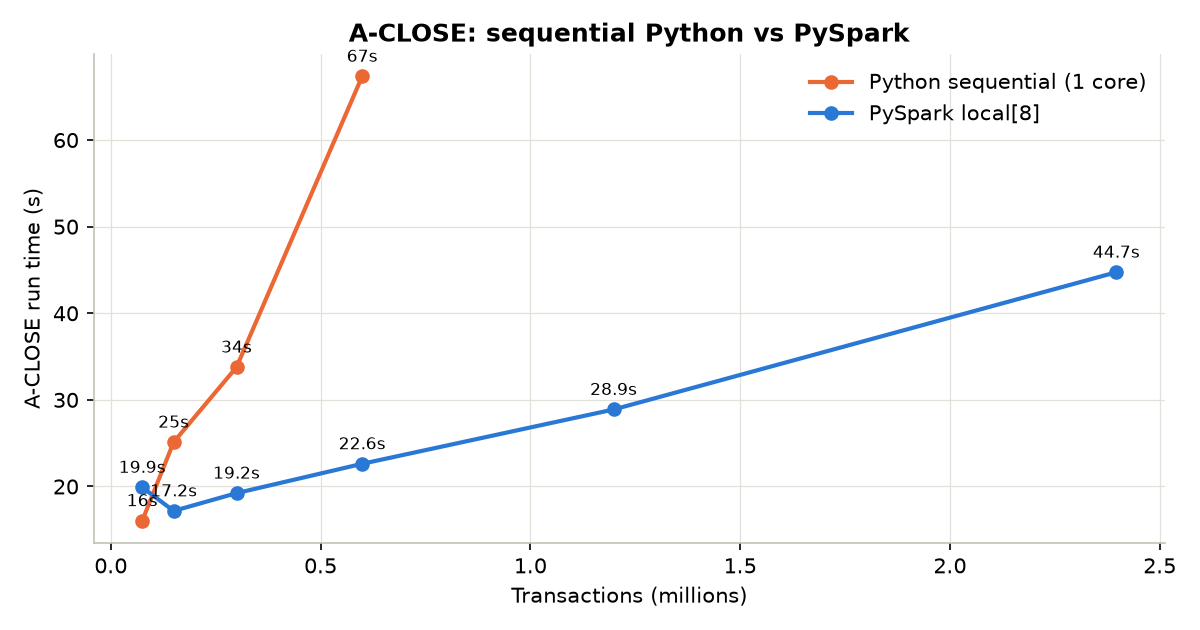

In [84]:
show('spark_aclose_runtime.png')

**Interpretation (Spark A-CLOSE)** — see the timing table above.
* On the original 75 k transactions Spark is *slower* than plain Python, because every level launches distributed
  jobs with a fixed scheduling and code-generation cost.
* As the data grow, the sequential time grows linearly while Spark's grows much more slowly. Spark becomes
  several times faster at 600 k transactions and handles 2.4 M transactions in about a minute, with
  **identical closed itemsets** in every run.
* At ×8 data the run is still dominated by per-job overhead, so adding cores gives only a modest, well-below-linear
  gain. Much of the gain there comes from executing the counting in Spark's compiled JVM engine.

## 8. PySpark test drive 2 — Decision Tree on Spark MLlib
Same task, features, storm-wise split and hyper-parameters as Part 4 (gini, depth 8, min 20 per leaf).
1. Model quality: Spark MLlib vs scikit-learn on the same test storms.
2. Scalability: the training set is replicated ×1 … ×100 (17.6 k → 1.76 M rows).
3. Core scaling with 1, 2, 4 and 8 cores.

*Runtime: about 6 minutes.*

In [85]:
import importlib
import time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier as SkTree
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score

from common import FIG_DIR, RANDOM_STATE, Logger, save_json
from spark_setup import get_spark
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.sql import functions as F

dt05 = importlib.import_module("05_decision_tree")
FEATURES, CLASSES = dt05.FEATURES, dt05.CLASSES
log = Logger("08_pyspark_decision_tree")
DEPTH, MIN_LEAF = 8, 20
LABEL = {c: float(i) for i, c in enumerate(CLASSES)}

d = dt05.build_dataset()
X, y, groups = d[FEATURES].values, d["Status"].values, d["ID"].values
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE).split(X, y, groups))
train_pd = d.iloc[tr][FEATURES + ["Status"]].assign(label=lambda x: x.Status.map(LABEL)).drop(columns="Status")
test_pd = d.iloc[te][FEATURES + ["Status"]].assign(label=lambda x: x.Status.map(LABEL)).drop(columns="Status")
log(f"Train rows {len(train_pd)}, test rows {len(test_pd)} (same storm-wise split as 05_decision_tree.py)")

def assembler():
    """Created after a SparkSession exists (MLlib objects need a live JVM)."""
    return VectorAssembler(inputCols=FEATURES, outputCol="features")


def spark_tree():
    return DecisionTreeClassifier(labelCol="label", featuresCol="features", impurity="gini",
                                  maxDepth=DEPTH, minInstancesPerNode=MIN_LEAF, maxBins=64, seed=RANDOM_STATE)


def replicated(spark, base, k, parts):
    df = (base.crossJoin(spark.range(k).withColumnRenamed("id", "rep")).drop("rep")
          .repartition(parts).cache())
    n = df.count()
    return df, n

Train rows 17606, test rows 7759 (same storm-wise split as 05_decision_tree.py)


In [86]:
# ======================================================================
# 1. Quality: Spark vs scikit-learn on the same split
# ======================================================================
spark = get_spark("dt-spark", cores="*")
cores = spark.sparkContext.defaultParallelism
train_sdf = assembler().transform(spark.createDataFrame(train_pd)).select("features", "label").cache()
test_sdf = assembler().transform(spark.createDataFrame(test_pd)).select("features", "label").cache()
train_sdf.count(); test_sdf.count()

model = spark_tree().fit(train_sdf)
pred = model.transform(test_sdf)
ev = lambda m: MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                                metricName=m).evaluate(pred)
spark_metrics = {m: round(ev(m), 4) for m in ("accuracy", "f1", "weightedPrecision", "weightedRecall")}
sk = SkTree(criterion="gini", max_depth=DEPTH, min_samples_leaf=MIN_LEAF, random_state=RANDOM_STATE)
sk.fit(train_pd[FEATURES].values, train_pd.label.values)
skp = sk.predict(test_pd[FEATURES].values)
sk_metrics = {"accuracy": round(accuracy_score(test_pd.label, skp), 4),
              "f1": round(f1_score(test_pd.label, skp, average="weighted"), 4)}
model_depth, model_nodes = model.depth, model.numNodes          # read while the JVM is alive
log(f"\nSpark MLlib tree : {spark_metrics}  (depth={model_depth}, nodes={model_nodes})")
log(f"scikit-learn tree: {sk_metrics}")

# per-class recall + confusion matrix from Spark predictions
pp = pred.select("label", "prediction").toPandas()
cm = pd.crosstab(pp.label.map(dict(enumerate(CLASSES))), pp.prediction.map(dict(enumerate(CLASSES))),
                 rownames=["actual"], colnames=["predicted"]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
log("Spark confusion matrix:\n" + cm.to_string())

imp = pd.Series(model.featureImportances.toArray(), index=FEATURES).sort_values(ascending=False).round(4)
log("Spark feature importance:\n" + imp.to_string())

# IF-THEN rules: Spark's debug string with real feature names
dbg = model.toDebugString
for i, f in reversed(list(enumerate(FEATURES))):
    dbg = dbg.replace(f"feature {i} ", f"{f} ")
for c, v in LABEL.items():
    dbg = dbg.replace(f"Predict: {v}", f"Predict: {c}")
lines = dbg.splitlines()
log(f"\nSpark tree rules (first 40 of {len(lines)} lines):\n" + "\n".join(lines[:40]))


Spark MLlib tree : {'accuracy': 0.8194, 'f1': 0.8188, 'weightedPrecision': 0.8185, 'weightedRecall': 0.8194}  (depth=8, nodes=137)
scikit-learn tree: {'accuracy': 0.8085, 'f1': 0.8084}
Spark confusion matrix:
predicted    TD    TS    HU   EX
actual                          
TD         1397   303     2   35
TS          340  2461   177  103
HU            0   172  2165   37
EX           47   158    27  335
Spark feature importance:
Pressure             0.7789
Latitude             0.1242
Longitude            0.0542
HoursSinceGenesis    0.0217
Month                0.0081
dPressure6h          0.0072
Heading              0.0048
Speed_kmh            0.0009
BasinCode            0.0000

Spark tree rules (first 40 of 206 lines):
DecisionTreeClassificationModel: uid=DecisionTreeClassifier_5295496a821d, depth=8, numNodes=137, numClasses=4, numFeatures=9
  If (Pressure <= 989.5)
   If (Latitude <= 43.55)
    If (Pressure <= 987.5)
     If (Pressure <= 979.5)
      Predict: HU
     Else (Pressure > 

In [87]:
# ======================================================================
# 2. Scalability: replicate training data, time fit()
# ======================================================================
SCALES = [1, 5, 10, 25, 50, 100]
spark_tree().fit(train_sdf)                                  # JVM warm-up
bench = []
for k in SCALES:
    big, n = replicated(spark, train_sdf, k, 2 * cores)
    t0 = time.perf_counter(); spark_tree().fit(big); ts = time.perf_counter() - t0
    big.unpersist()
    Xb = np.tile(train_pd[FEATURES].values, (k, 1)); yb = np.tile(train_pd.label.values, k)
    t0 = time.perf_counter()
    SkTree(criterion="gini", max_depth=DEPTH, min_samples_leaf=MIN_LEAF, random_state=RANDOM_STATE).fit(Xb, yb)
    tk = time.perf_counter() - t0
    bench.append({"scale": k, "rows": n, "sklearn_s": round(tk, 2), "spark_s": round(ts, 2),
                  "speedup": round(tk / ts, 2)})
    log(f"x{k:<4d} rows={n:>9,d}  scikit-learn={tk:7.2f}s  Spark local[{cores}]={ts:7.2f}s  "
        f"speed-up={tk / ts:5.2f}")
spark.stop()

x1    rows=   17,606  scikit-learn=   0.09s  Spark local[8]=   2.16s  speed-up= 0.04


x5    rows=   88,030  scikit-learn=   0.28s  Spark local[8]=   2.02s  speed-up= 0.14


x10   rows=  176,060  scikit-learn=   0.50s  Spark local[8]=   2.11s  speed-up= 0.24


x25   rows=  440,150  scikit-learn=   1.55s  Spark local[8]=   2.69s  speed-up= 0.58


x50   rows=  880,300  scikit-learn=   2.44s  Spark local[8]=   3.34s  speed-up= 0.73


x100  rows=1,760,600  scikit-learn=   5.24s  Spark local[8]=   4.95s  speed-up= 1.06


In [88]:
# ======================================================================
# 3. Core scaling at the largest size
# ======================================================================
scaling = []
for c in (1, 2, 4, cores):
    sp = get_spark(f"dt-{c}", cores=c)
    base = assembler().transform(sp.createDataFrame(train_pd)).select("features", "label").cache()
    base.count()
    spark_tree().fit(base)                                   # warm-up
    big, n = replicated(sp, base, SCALES[-1], max(2 * c, 4))
    t0 = time.perf_counter(); spark_tree().fit(big); t = time.perf_counter() - t0
    scaling.append({"cores": c, "seconds": round(t, 2)})
    log(f"[core scaling] x{SCALES[-1]} ({n:,} rows), local[{c}] -> {t:.2f}s")
    sp.stop()
sc = pd.DataFrame(scaling); sc["speedup_vs_1core"] = (sc.seconds.iloc[0] / sc.seconds).round(2)
log("\nCore scaling:\n" + sc.to_string(index=False))
b = pd.DataFrame(bench)
log("\nBenchmark:\n" + b.to_string(index=False))

[core scaling] x100 (1,760,600 rows), local[1] -> 11.31s


[core scaling] x100 (1,760,600 rows), local[2] -> 7.32s


[core scaling] x100 (1,760,600 rows), local[4] -> 4.95s


[core scaling] x100 (1,760,600 rows), local[8] -> 5.99s



Core scaling:
 cores  seconds  speedup_vs_1core
     1    11.31              1.00
     2     7.32              1.55
     4     4.95              2.28
     8     5.99              1.89

Benchmark:
 scale    rows  sklearn_s  spark_s  speedup
     1   17606       0.09     2.16     0.04
     5   88030       0.28     2.02     0.14
    10  176060       0.50     2.11     0.24
    25  440150       1.55     2.69     0.58
    50  880300       2.44     3.34     0.73
   100 1760600       5.24     4.95     1.06


In [89]:
# ---------------- plots ---------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(b.rows / 1e6, b.sklearn_s, "o-", color="#eb6834", lw=2, label="scikit-learn (1 core, in-memory)")
ax.plot(b.rows / 1e6, b.spark_s, "o-", color="#2a78d6", lw=2, label=f"Spark MLlib local[{cores}]")
ax.set(xlabel="Training rows (millions)", ylabel="Training time (s)",
       title="Decision tree training time vs data size")
ax.legend(frameon=False); ax.grid(color="#e1e0d9"); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/spark_dt_runtime.png", dpi=150); plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(sc.cores, sc.speedup_vs_1core, "o-", color="#2a78d6", lw=2, label="measured")
ax.plot(sc.cores, sc.cores, "--", color="#888", lw=1, label="ideal (linear)")
ax.set(xlabel="Spark cores (local[n])", ylabel="Speed-up vs 1 core",
       title=f"Spark decision tree: core scaling (x{SCALES[-1]} data)")
ax.set_xticks(sc.cores)
ax.legend(frameon=False); ax.grid(color="#e1e0d9"); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/spark_dt_cores.png", dpi=150); plt.close(fig)

save_json({"spark_metrics": spark_metrics, "sk_metrics": sk_metrics, "depth": model_depth,
           "nodes": model_nodes, "importance": imp.to_dict(), "bench": bench, "core_scaling": scaling,
           "cores": cores, "cm": cm.values.tolist(), "rules_head": lines[:40]}, "spark_dt")
log.close()

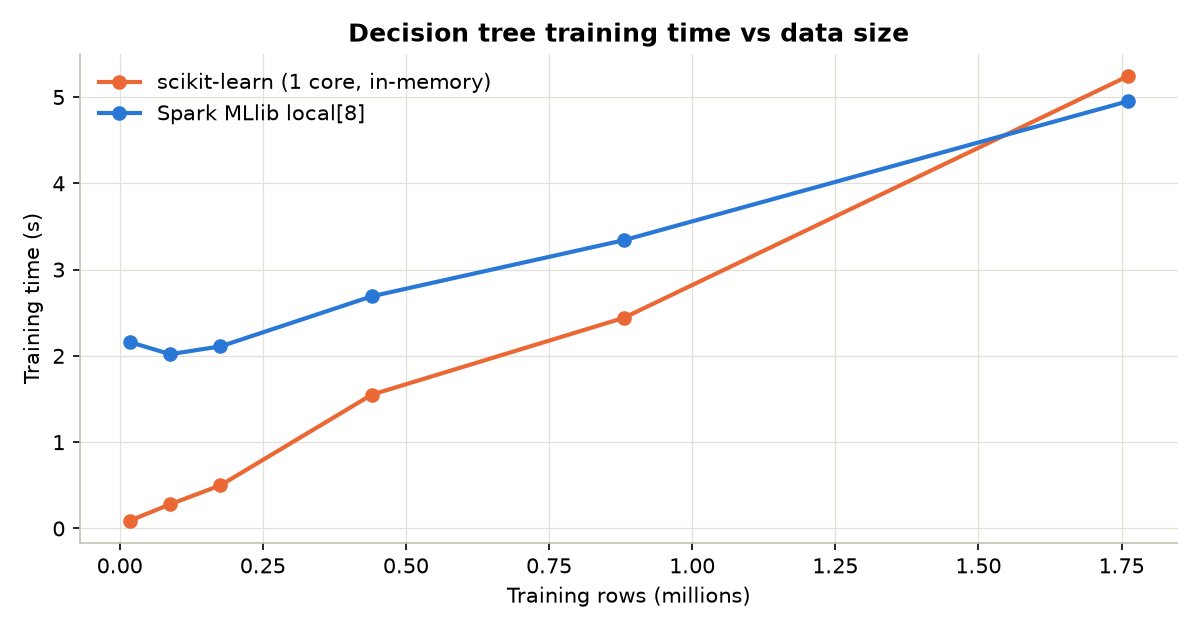

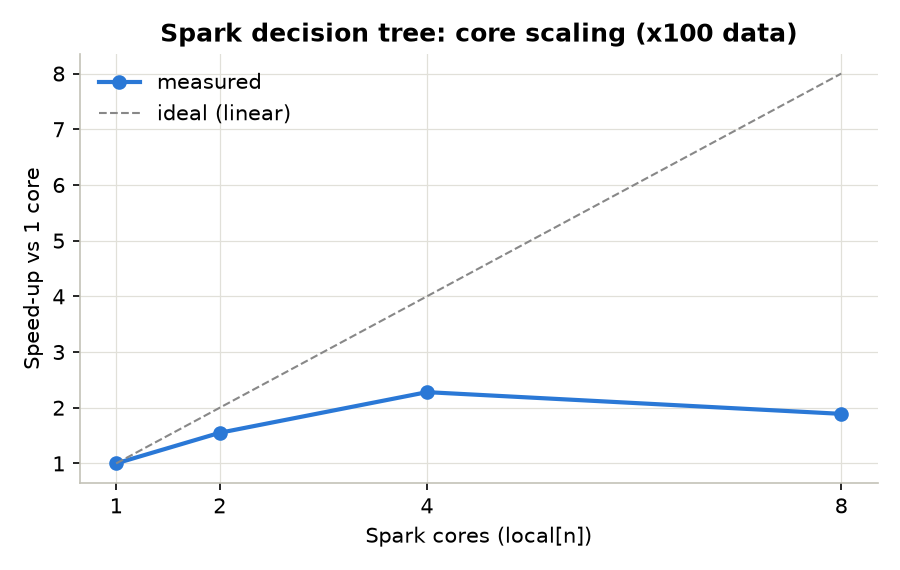

In [90]:
show('spark_dt_runtime.png', 'spark_dt_cores.png')

**Interpretation (Spark decision tree)** — see the benchmark above.
* MLlib reaches the same accuracy as scikit-learn (≈0.81–0.82). Binning continuous features (maxBins = 64) costs
  nothing here.
* For small data scikit-learn (optimised C, in memory) is much faster, because Spark pays a fixed job overhead.
  The gap closes as data grow, and at ~1.76 M rows Spark is faster.
* Spark training time drops when cores are added, and on a cluster the same code scales to data that do not fit
  on one machine.

## 9. Generate the PDF report
The report reads every number from the outputs written by the cells above (`outputs/logs/*.json`,
`outputs/data/*.csv`), so it always matches this notebook run.

In [91]:
import os
import json
import pandas as pd
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle,
                                PageBreak, KeepTogether, ListFlowable, ListItem)
from reportlab.lib.utils import ImageReader

from common import ROOT, FIG_DIR, LOG_DIR, CLEAN_DIR, MIN_SUPPORT, MIN_CONFIDENCE, DIC_BLOCK_SIZE

REPORT_DIR = os.path.join(ROOT, "report")
os.makedirs(REPORT_DIR, exist_ok=True)
OUT = os.path.join(REPORT_DIR, "Hurricane_Analytics_Report.pdf")


def J(name):
    p = os.path.join(LOG_DIR, name + ".json")
    return json.load(open(p, encoding="utf-8")) if os.path.exists(p) else None


pre, viz, dic, ac, dt, db = (J(n) for n in ("preprocessing", "visualization", "dic", "aclose",
                                             "decision_tree", "dbscan"))
sac, sdt = J("spark_aclose"), J("spark_dt")

In [92]:
# ----------------------------------------------------------------------------
# Styles & helpers
# ----------------------------------------------------------------------------
# DejaVu fonts (bundled with matplotlib) contain the math symbols used in the
# text (≤ ≥ ⇒ → ≈ ∩ ⊃ ∖ −) which the built-in Helvetica cannot render.
import matplotlib
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from reportlab.lib.fonts import addMapping
_fd = os.path.join(matplotlib.get_data_path(), "fonts", "ttf")
for name, file in (("DV", "DejaVuSans.ttf"), ("DV-B", "DejaVuSans-Bold.ttf"),
                   ("DV-I", "DejaVuSans-Oblique.ttf"), ("DV-BI", "DejaVuSans-BoldOblique.ttf"),
                   ("DVM", "DejaVuSansMono.ttf")):
    pdfmetrics.registerFont(TTFont(name, os.path.join(_fd, file)))
addMapping("DV", 0, 0, "DV"); addMapping("DV", 1, 0, "DV-B")
addMapping("DV", 0, 1, "DV-I"); addMapping("DV", 1, 1, "DV-BI")

ss = getSampleStyleSheet()
BLUE = colors.HexColor("#1c5cab")
H1 = ParagraphStyle("H1", parent=ss["Heading1"], fontName="DV-B", fontSize=16, textColor=BLUE,
                    spaceBefore=6, spaceAfter=8)
H2 = ParagraphStyle("H2", parent=ss["Heading2"], fontName="DV-B", fontSize=13, textColor=BLUE,
                    spaceBefore=10, spaceAfter=5)
H3 = ParagraphStyle("H3", parent=ss["Heading3"], fontName="DV-B", fontSize=10.5, spaceBefore=8, spaceAfter=3)
B = ParagraphStyle("B", parent=ss["BodyText"], fontName="DV", fontSize=9, leading=12.5, spaceAfter=4,
                   alignment=4)
SM = ParagraphStyle("SM", parent=B, fontSize=7.8, leading=10, alignment=0)
CAP = ParagraphStyle("CAP", parent=B, fontSize=8, textColor=colors.HexColor("#555555"), alignment=1)
CODE = ParagraphStyle("CODE", parent=SM, fontName="DVM", fontSize=6.8, leading=8.6)
story = []
W = A4[0] - 3.6 * cm


def h1(t): story.append(Paragraph(t, H1))
def h2(t): story.append(Paragraph(t, H2))
def h3(t): story.append(Paragraph(t, H3))
def p(t): story.append(Paragraph(t, B))


def bullets(items, style=B):
    story.append(ListFlowable([ListItem(Paragraph(i, style), leftIndent=10) for i in items],
                              bulletType="bullet", start="•", leftIndent=12, bulletFontSize=8))


def fig(name, caption, width=0.92):
    path = os.path.join(FIG_DIR, name)
    if not os.path.exists(path):
        p(f"<i>[figure {name} not generated]</i>")
        return
    iw, ih = ImageReader(path).getSize()
    w = W * width
    h = w * ih / iw
    if h > 15 * cm:
        h = 15 * cm; w = h * iw / ih
    story.append(KeepTogether([Image(path, width=w, height=h), Paragraph(caption, CAP), Spacer(1, 4)]))


def table(df, col_widths=None, font=7.5, header_bg="#e8f0fb"):
    st = ParagraphStyle("t", parent=SM, fontSize=font, leading=font + 2)
    data = [[Paragraph(f"<b>{c}</b>", st) for c in df.columns]]
    for row in df.itertuples(index=False):
        data.append([Paragraph(str(v), st) for v in row])
    t = Table(data, colWidths=col_widths, repeatRows=1)
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor(header_bg)),
        ("GRID", (0, 0), (-1, -1), 0.3, colors.HexColor("#c3c2b7")),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#f7f7f5")]),
        ("LEFTPADDING", (0, 0), (-1, -1), 3), ("RIGHTPADDING", (0, 0), (-1, -1), 3),
    ]))
    story.append(t)
    story.append(Spacer(1, 6))


def inferences(items):
    h3("Key inferences")
    bullets(items)

In [93]:
# ============================================================================
# TITLE PAGE
# ============================================================================
story.append(Spacer(1, 2.5 * cm))
story.append(Paragraph("25CS5004 / CS5010 Analytics &amp; Systems of Big Data Practice — End-semester",
                       ParagraphStyle("t0", parent=B, alignment=1, fontSize=11)))
story.append(Spacer(1, 0.6 * cm))
story.append(Paragraph("Descriptive &amp; Predictive Analytics of the NOAA Atlantic and Pacific "
                       "Hurricane Database (HURDAT2, 1851–2015)",
                       ParagraphStyle("t1", parent=H1, fontSize=20, leading=26, alignment=1)))
story.append(Spacer(1, 0.6 * cm))
story.append(Paragraph("Preprocessing · 15 visualisations · DIC association rules · Decision Tree · "
                       "DBSCAN · A-CLOSE closed itemsets · PySpark scalability study",
                       ParagraphStyle("t2", parent=B, alignment=1, fontSize=10.5)))
story.append(Spacer(1, 1.0 * cm))
story.append(Paragraph("Submitted by", ParagraphStyle("t3", parent=B, alignment=1, fontSize=10,
                                                      textColor=colors.HexColor("#555555"))))
story.append(Paragraph("<b>Umesh Chandra</b>", ParagraphStyle("t4", parent=B, alignment=1, fontSize=14,
                                                             leading=18)))
story.append(Paragraph("Roll No. <b>CS23I1036</b>", ParagraphStyle("t5", parent=B, alignment=1, fontSize=11.5,
                                                                  leading=15)))
story.append(Spacer(1, 1.0 * cm))
table(pd.DataFrame([
    ["Dataset", "kaggle.com/noaa/hurricane-database — atlantic.csv, pacific.csv"],
    ["Raw size", f"{pre['raw_rows']:,} six-hourly observations, {pre['raw_cols']} attributes, "
                 f"{pre['raw_storms']:,} storms"],
    ["Tools", "Python 3.13, pandas, NumPy, matplotlib/seaborn, scikit-learn, SciPy, mlxtend (verification "
              "only), PySpark 4.0.1 (Spark SQL + MLlib) on OpenJDK 17, ReportLab"],
    ["Hardware", f"Windows 11 laptop, {sac['cores'] if sac else 8} logical cores, 16 GB RAM, Spark local mode"],
    ["Source files", "src/01_preprocessing.py … src/09_build_report.py (see Appendix A)"],
], columns=["Item", "Details"]), col_widths=[3 * cm, W - 3 * cm], font=8.5)
story.append(PageBreak())

In [94]:
# ============================================================================
# 1. INTRODUCTION
# ============================================================================
h1("1. Problem statement and dataset")
p("The task is to perform an exhaustive descriptive analysis (including data cleaning, data selection and "
  "data transformation), apply at least ten suitable visualisation techniques with inferences, and then "
  "apply the predictive techniques (i) association rules with the <b>DIC</b> algorithm, (ii) a <b>Decision Tree "
  "classifier</b> and <b>DBSCAN</b> clustering, and (iii) closed frequent itemsets / closed rules with "
  "<b>A-CLOSE</b>. Two of these techniques are then test-driven on <b>PySpark</b> to establish the "
  "performance enhancement obtained from big-data support.")
p("The HURDAT2 database (NOAA National Hurricane Center) records the position and intensity of every "
  "tropical cyclone every six hours. Two files are provided: the Atlantic basin (1851–2015) and the "
  "North-East &amp; Central Pacific basin (1949–2015). Each row has the attributes below.")
table(pd.DataFrame([
    ["ID", "Storm identifier: basin (AL/EP/CP) + number + year, e.g. AL011851"],
    ["Name", "Storm name ('UNNAMED' before naming began), padded with spaces"],
    ["Date, Time", "YYYYMMDD and HHMM (UTC); mostly synoptic 00/06/12/18 h plus special fixes"],
    ["Event", "Record identifier: L = landfall, I = intensity peak, etc. (blank for most rows)"],
    ["Status", "TD, TS, HU, EX (extratropical), SD/SS (subtropical), LO, WV, DB, ET, PT, ST"],
    ["Latitude, Longitude", "Strings such as 28.0N / 94.8W"],
    ["Maximum Wind", "1-minute sustained wind (knots); -99/-999 = missing"],
    ["Minimum Pressure", "Central pressure (hPa); -999 = missing"],
    ["Low/Moderate/High Wind NE/SE/SW/NW", "12 wind-radii columns (34/50/64-kt radii, n mi); -999 = missing"],
], columns=["Attribute", "Meaning"]), col_widths=[4.2 * cm, W - 4.2 * cm])

h2("1.1 Assumed parameters")
table(pd.DataFrame([
    ["Association rules (DIC, A-CLOSE)", f"min_support = {MIN_SUPPORT:.0%}, min_confidence = {MIN_CONFIDENCE:.0%}"],
    ["DIC block size M", f"{DIC_BLOCK_SIZE:,} transactions between stops"],
    ["Decision tree", f"gini / entropy and max_depth 2–20 chosen by 5-fold GroupKFold CV; "
                      f"min 20 samples per leaf; storm-wise 70/30 train/test split"],
    ["DBSCAN", f"haversine distance; MinPts = {db['min_pts']}; eps = {db['eps_km']:.0f} km from the k-distance "
               f"knee; level-2 eps = {db['eps2_km']} km"],
    ["Noise thresholds", "wind 10–200 kt; pressure 870–1030 hPa; translation speed ≤ 150 km/h"],
    ["PySpark", "local[*] mode, 6 GB driver memory; data replicated to emulate growth"],
], columns=["Technique", "Parameter values"]), col_widths=[4.5 * cm, W - 4.5 * cm])

In [95]:
# ============================================================================
# 2. PREPROCESSING
# ============================================================================
story.append(PageBreak())
h1("2. Data preprocessing")
h2("2.1 (i) Data cleaning — removing noisy, missing and inconsistent data")
s = pre["sentinels"]
table(pd.DataFrame([
    ["1", "White-space padding", "Name ('            UNNAMED'), Status (' HU') and Event were padded", "Stripped"],
    ["2", "Sentinel codes", f"-999/-99 used for missing: wind {s['Maximum Wind']}, pressure "
                            f"{s['Minimum Pressure']:,} ({100*s['Minimum Pressure']/pre['raw_rows']:.1f} %), each "
                            f"wind-radius column {s['Low Wind NE']:,} ({100*s['Low Wind NE']/pre['raw_rows']:.1f} %)",
     "Replaced by NaN (a -999 hPa pressure would destroy every mean/correlation)"],
    ["3", "Coordinate strings", "28.0N / 94.8W cannot be used numerically", "Parsed to signed degrees"],
    ["4", "Separate Date/Time", "HHMM integers (0, 600, 1200 …)", "Merged into one Datetime"],
    ["5", "Duplicates", "Exact and (ID, Datetime) duplicates", f"{pre['dups_removed']} found"],
    ["6", "Inconsistent codes", f"Pacific uses ET ({pre['status_fix']['ET']}) as well as EX; PT "
                                f"({pre['status_fix']['PT']}, post-tropical); ST ({pre['status_fix']['ST']} rows = "
                                "Super Typhoon Genevieve 2014, 130–140 kt, after crossing the dateline)",
     "ET, PT → EX; ST → HU"],
    ["7", "Out-of-range values", f"Longitudes 359.1W/358.4W (AL051952) are typing noise for ~1°E",
     f"{pre['lon_repaired']} repaired by wrapping to ±180°; no wind/pressure outside physical limits"],
    ["8", "Missing class attribute", f"{pre['missing_wind_dropped']} rows without Maximum Wind; "
                                     f"{pre['storms_no_wind']} storms (1967–68 depressions) had none at all",
     "Rows removed"],
    ["9", "Logical contradiction", "Status vs. wind definition (HU ≥ 64 kt, 34 ≤ TS ≤ 63, TD < 34), "
                                   "e.g. AL101958 'HU' with 60 kt", f"{pre['status_wind_inconsistent']} rows removed"],
    ["10", "Kinematic noise", "Consecutive fixes implying > 150 km/h translation speed (position error)",
     f"{pre['speed_noise']} rows removed"],
    ["11", "Outliers (IQR rule)", f"{pre['iqr_outliers_Maximum Wind']} wind and "
                                  f"{pre['iqr_outliers_Minimum Pressure']:,} pressure IQR outliers",
     "Kept — they are genuine extremes (Patricia 2015: 185 kt, 872 hPa)"],
], columns=["#", "Problem", "Evidence in the data", "Action"]),
    col_widths=[0.6 * cm, 2.8 * cm, 8.2 * cm, W - 11.6 * cm])
p(f"<b>Result:</b> {pre['raw_rows']:,} → <b>{pre['clean_rows']:,}</b> observations "
  f"({100*(1-pre['clean_rows']/pre['raw_rows']):.2f} % removed) and {pre['raw_storms']:,} → "
  f"<b>{pre['clean_storms']:,}</b> storms. The cleaning is deliberately conservative: values that are "
  "extreme but physically real are kept, only impossible or contradictory records are removed.")

h2("2.2 (ii) Data selection — task-relevant attributes")
bullets([
    f"<b>Dropped:</b> the 12 wind-radii columns — {pre['missing_pct']['Low Wind NE']} % missing because "
    f"they are only recorded since {pre['radii_first_year']}; imputing 84 % of a column would create, not "
    "describe, data.",
    "<b>Replaced:</b> Date and Time → Datetime; Event → binary <i>Landfall</i> flag (Event is blank for ≈98.7 % "
    "of rows and only 'L' is analytically useful).",
    f"<b>Kept with caution:</b> Minimum Pressure ({pre['missing_pct']['Minimum Pressure']} % missing; "
    "available for only 3 % of pre-1950 rows but 82 % after 1979). It is strongly redundant with wind "
    f"(Pearson r = {pre['corr_wind_pressure']}), but because Status is <i>defined</i> from wind, pressure is "
    "the physically independent measurement used by the classifier.",
    "<b>Redundancy check at storm level:</b> NumObs and DurationH have r = 1.00 (Fig. 7), so only DurationH is "
    "used afterwards.",
    "<b>Selected attributes:</b> ID, Name, Basin, Datetime, Status, Latitude, Longitude, Wind, Pressure, "
    "Landfall (+ derived motion attributes below).",
])

h2("2.3 (iii) Data transformation")
bullets([
    "<b>Attribute construction:</b> Year, Month, Hour, Decade; Basin (from the file); 6-hourly step distance "
    "(haversine), translation speed (km/h), heading, dLat/dLon (dateline-safe), wind change dWind, 6-h "
    "pressure tendency dPressure6h, HoursSinceGenesis.",
    "<b>Unit conversion:</b> knots → km/h (Wind_kmh).",
    "<b>Discretisation by domain thresholds:</b> Wind → Saffir-Simpson category (TD, TS, Cat1–Cat5).",
    "<b>Concept hierarchy:</b> 9 status codes → 6 families (TD, TS, HU, EX, SUB = SD+SS, LOW = LO+WV+DB).",
    "<b>Normalisation:</b> min-max scaling of Wind, Latitude, Longitude ([0,1]) for plots / parallel coordinates; "
    "standardisation of cluster profiles before Ward linkage.",
    f"<b>Aggregation (roll-up):</b> observation level → storm level ({pre['n_storms']:,} storms: genesis "
    "position and month, lifetime max wind, min pressure, duration, track length, landfall, max 24-h "
    "intensification …).",
    f"<b>Transaction encoding for ARM:</b> every observation becomes an itemset of attribute=value items "
    f"({pre['n_transactions']:,} transactions, {pre['n_items']} distinct items): Basin, Season (Jan–Jul / "
    "Aug–Sep / Oct–Dec), latitude band (&lt;15N, 15–25N, 25–35N, ≥35N), Status family, Era (1851–1949 / "
    "1950–1989 / 1990–2015), Pressure band (&lt;980, 980–999, ≥1000 hPa, when known), Speed band "
    "(&lt;15, 15–30, &gt;30 km/h), Motion (Eastward / Westward), Landfall.",
    "<b>Label encoding:</b> Basin → 0/1 for the decision tree; bit-mask encoding of itemsets for A-CLOSE/Spark.",
])

h2("2.4 Descriptive statistics (after cleaning)")
dd = pd.DataFrame(viz["desc"]).T
dd = dd[["count", "mean", "median", "mode", "std", "min", "25%", "75%", "max", "IQR", "skew", "kurtosis"]]
dd.insert(0, "attribute", dd.index)
table(dd.round(2), font=7)
sd = pd.DataFrame(viz["storm_desc"]).T.reset_index().rename(columns={"index": "storm attribute"})
table(sd.round(1), font=7.5)
bullets([
    f"Wind is right-skewed (skew {viz['desc']['Wind']['skew']}): mean {viz['desc']['Wind']['mean']} kt &gt; median "
    f"{viz['desc']['Wind']['median']} kt &gt; mode {viz['desc']['Wind']['mode']} kt — most of a storm's life is spent "
    "at modest intensity.",
    f"Pressure is left-skewed (skew {viz['desc']['Pressure']['skew']}) with high kurtosis "
    f"({viz['desc']['Pressure']['kurtosis']}): a long tail of very deep lows.",
    f"A typical storm lives {viz['storm_desc']['DurationH']['50%']/24:.1f} days (median) and travels "
    f"{viz['storm_desc']['TrackKm']['50%']:,.0f} km; the longest track is {viz['storm_desc']['TrackKm']['max']:,.0f} km.",
    f"Strongest storm: {viz['top_storms'][0]['Name'].title()} {viz['top_storms'][0]['Year']} "
    f"({viz['top_storms'][0]['MaxWind']:.0f} kt, {viz['top_storms'][0]['MinPressure']:.0f} hPa).",
])

In [96]:
# ============================================================================
# 3. VISUALISATION
# ============================================================================
story.append(PageBreak())
h1("3. Visualisation techniques and inferences")
p("Fifteen distinct plot types are applied. Atlantic is always shown in blue and Pacific in orange; "
  "magnitudes use a single-hue sequential scale.")
v = viz
fs = v["five_num"]
pq = v["pressure_quantiles"]
mc = v["month_counts"]
sh = v["status_share"]
mdc = v["median_duration_by_cat"]
pcm = v["pc_medians"]
msp = v["major_share_by_period"]
corr = v["corr"]

PLOTS = [
    ("fig01_histogram_wind.png", "Figure 1 – Histogram of maximum wind (5-kt bins)", [
        f"Right-skewed distribution (skew {v['wind_skew']}), mode {v['wind_mode']:.0f} kt; "
        f"{v['pct_below_64']} % of all observations are below hurricane force and only {v['pct_major']} % "
        "are major hurricanes (≥ 96 kt).",
        "99.99 % of wind values are multiples of 5 kt — the database's reporting resolution, so 5-kt bins are "
        "the natural bin width (no spurious gaps).",
        "Both basins have the same shape; the Atlantic has more observations because its record is 98 years longer.",
    ]),
    ("fig02_boxplot_status.png", "Figure 2 – Box plot of wind per status family and basin", [
        f"HU: median {fs['HU']['50%']:.0f} kt, IQR {fs['HU']['25%']:.0f}–{fs['HU']['75%']:.0f} kt, with many "
        f"high outliers up to {fs['HU']['max']:.0f} kt (the intense tail).",
        f"TS lies strictly within {fs['TS']['min']:.0f}–{fs['TS']['max']:.0f} kt and TD ≤ {fs['TD']['max']:.0f} kt — "
        "the cleaning step removed all status/wind contradictions.",
        "Extratropical (EX) systems span 10–95 kt; Atlantic EX systems are much stronger (median 45 kt) than "
        "Pacific EX (25 kt) because Atlantic storms recurve into the mid-latitude westerlies while Pacific "
        "storms decay over cold water.",
        "Before cleaning this plot exposed 130–140 kt 'subtropical' values — the mis-coded Super Typhoon (ST) "
        "rows, which were then re-mapped to HU.",
    ]),
    ("fig03_quantile_pressure.png", "Figure 3 – Quantile plot of central pressure", [
        f"Atlantic quantiles are lower everywhere: 10 % quantile {pq['Atlantic']['0.1']:.0f} vs "
        f"{pq['Pacific']['0.1']:.0f} hPa, median {pq['Atlantic']['0.5']:.0f} vs {pq['Pacific']['0.5']:.0f} hPa.",
        "The steep drop below f ≈ 0.05 shows how rare deep systems are: the 5th percentile is 952 hPa and only "
        "4.1 % of pressure readings are below 950 hPa.",
        "The flat upper part (≈ 1000–1010 hPa) is the large mass of weak depressions and storms.",
    ]),
    ("fig04_qq_plot.png", "Figure 4 – Q-Q plots: Atlantic vs Pacific (left) and storm max wind vs normal (right)", [
        f"Left: points lie on y = x in the lower part (mean difference {v['qq_lower_diff']} kt) but above it in the "
        f"upper 20 % (Pacific +{v['qq_upper_diff']} kt): the most intense Pacific storms are slightly stronger.",
        f"Right: correlation with the normal line is high (r = {v['normal_qq_r']}) but the curve is convex — "
        "lifetime max wind is right-skewed, so non-parametric methods (median, IQR, trees) are preferred.",
    ]),
    ("fig05_scatter_wind_pressure.png", "Figure 5 – Scatter plot of wind vs central pressure", [
        f"Very strong linear inverse relation: r = {v['wp_r']}; wind ≈ {v['wp_intercept']:.0f} "
        f"{v['wp_slope']:+.2f} × P, i.e. every 1 hPa deeper adds ≈ {abs(v['wp_slope']):.1f} kt.",
        "Scatter widens at low pressure — the wind-pressure relationship depends on storm size and latitude.",
        "Justifies using Pressure as the physically independent predictor of Status in the decision tree.",
    ]),
    ("fig06_scatter_matrix.png", "Figure 6 – Scatter-plot matrix of storm-level attributes", [
        "MaxWind–MinPressure is a tight line; DurationH–TrackKm is strongly positive (long-lived storms travel far).",
        "Long-lived storms reach higher peak winds (positive MaxWind–DurationH cloud).",
        "Pacific storms form at lower genesis latitudes (orange mass shifted left on GenesisLat).",
    ]),
    ("fig07_correlation_heatmap.png", "Figure 7 – Correlation heat-map (storm level)", [
        f"MaxWind–MinPressure r = {corr['MaxWind']['MinPressure']}; MaxWind–Max24hIntensification r = "
        f"{corr['MaxWind']['Max24hIntensification']}: storms that become strong do so by rapid intensification.",
        f"DurationH–NumObs r = {corr['DurationH']['NumObs']} → redundant attribute removed (data selection).",
        f"Genesis latitude correlates negatively with MaxWind (r = {corr['MaxWind']['GenesisLat']}) and duration "
        f"(r = {corr['DurationH']['GenesisLat']}): storms born closer to the equator live longer and get stronger.",
        f"Year vs MaxWind is weak (r = {corr['MaxWind']['Year']}): no simple linear trend in individual storm peaks.",
    ]),
    ("fig08_bar_month.png", "Figure 8 – Grouped bar chart: storms formed per month", [
        f"Atlantic peaks in September ({mc['Atlantic']['9']} storms) and {v['atl_aug_oct_share']} % form in Aug–Oct.",
        f"Pacific peaks in August ({mc['Pacific']['8']}) and starts earlier: May–July genesis is much higher "
        f"({mc['Pacific']['5'] + mc['Pacific']['6'] + mc['Pacific']['7']} vs "
        f"{mc['Atlantic']['5'] + mc['Atlantic']['6'] + mc['Atlantic']['7']} Atlantic storms); "
        f"{v['pac_jul_sep_share']} % form in Jul–Sep.",
        "Only 28 of 2,845 storms (≈1 %) formed outside May–November, confirming the season definition "
        "(the Pacific season officially starts on 15 May, the Atlantic on 1 June).",
    ]),
    ("fig09_line_yearly.png", "Figure 9 – Line chart of annual storm counts (thin) with 10-year moving average (thick)", [
        f"Recorded Atlantic activity more than doubled: {v['atl_mean_1851_1900']} storms/yr (1851–1900) vs "
        f"{v['atl_mean_1966_2015']} (1966–2015); Pacific {v['pac_mean_1949_1970']} (1949–70) vs "
        f"{v['pac_mean_1971_2015']} (1971–2015).",
        "The step around the satellite era (mid-1960s) indicates that much of the rise is improved detection of "
        "short-lived open-ocean storms, not only a climatic change — a data-quality caveat for trend analysis.",
        f"The busiest Atlantic year is {v['max_year_atl']} ({v['max_year_atl_n']} storms); multi-decadal "
        "oscillations (active 1950s, quiet 1970s–80s, active after 1995) are visible.",
    ]),
    ("fig10_pie_status.png", "Figure 10 – Pie chart: share of observations by status", [
        f"Tropical storms dominate the record ({sh['TS']} %), followed by hurricanes ({sh['HU']} %) and "
        f"depressions ({sh['TD']} %).",
        f"Extratropical ({sh['EX']} %), low/wave/disturbance ({sh['LOW']} %) and subtropical ({sh['SUB']} %) stages are "
        "minor classes — this class imbalance is handled in the decision tree by macro-averaged metrics.",
    ]),
    ("fig11_violin_duration.png", "Figure 11 – Violin plot of storm lifetime by peak category", [
        f"Median lifetime rises monotonically with peak intensity: TD {mdc['TD']} d, TS {mdc['TS']} d, Cat1 "
        f"{mdc['Cat1']} d, Cat3 {mdc['Cat3']} d, Cat5 {mdc['Cat5']} d.",
        "Reaching high intensity requires a long time over warm water; weak systems have narrow, short "
        "distributions while major hurricanes show wide spreads with long tails.",
    ]),
    ("fig12_track_map.png", "Figure 12 – Geographic track map (every fix coloured by wind)", [
        "Pacific storms move west at 10–20°N and dissipate over the cool eastern Pacific; Atlantic storms "
        "recurve north-eastwards towards Europe and many transform into extratropical systems.",
        f"Intense fixes (red) are confined to the tropics: mean latitude of hurricane fixes {v['hu_lat_mean']}°N; "
        f"90 % of major-hurricane fixes are south of {v['major_lat_p90']}°N.",
        f"Atlantic storms hit land far more often: {v['landfall_by_basin']['Atlantic']} % of Atlantic storms have a "
        f"recorded landfall vs {v['landfall_by_basin']['Pacific']} % in the Pacific.",
    ]),
    ("fig13_parallel_coordinates.png", "Figure 13 – Parallel coordinates of storm profiles (40 storms per class)", [
        f"Category-5 storms (median {pcm['Cat5']['MinPressure']:.0f} hPa, {pcm['Cat5']['DurationH']:.0f} h, "
        f"{pcm['Cat5']['TrackKm']:,.0f} km) are separated from tropical storms ({pcm['TS']['MinPressure']:.0f} hPa, "
        f"{pcm['TS']['DurationH']:.0f} h, {pcm['TS']['TrackKm']:,.0f} km) on every axis.",
        f"Stronger storms form at lower latitude (median genesis {pcm['Cat5']['GenesisLat']:.0f}°N for Cat5 vs "
        f"{pcm['TS']['GenesisLat']:.0f}°N for TS).",
        "Line crossings between MaxWind and MinPressure illustrate their inverse relation.",
    ]),
    ("fig14_hexbin_genesis.png", "Figure 14 – Hexbin density plot of genesis locations", [
        f"Two dense 'nurseries': eastern Pacific off Mexico (median genesis {v['genesis_lat_median']['Pacific']}°N, "
        f"{-v['genesis_lon_median']['Pacific']}°W) and the Atlantic/Caribbean "
        f"({v['genesis_lat_median']['Atlantic']}°N, {-v['genesis_lon_median']['Atlantic']}°W).",
        "Pacific genesis is far more concentrated; Atlantic genesis is spread from Africa to the Gulf of Mexico — "
        "motivating density-based clustering (DBSCAN, Section 4.3).",
    ]),
    ("fig15_stacked_category.png", "Figure 15 – 100 % stacked bar: peak-category mix of hurricanes by period", [
        f"Share of hurricanes that became major (Cat3+) rose in the Atlantic from {msp['Atlantic 1851-1900']} % "
        f"(1851–1900) to {msp['Atlantic 2001-2015']} % (2001–2015), and in the Pacific from "
        f"{msp['Pacific 1951-1980']} % (1951–80) to {msp['Pacific 2001-2015']} % (2001–15).",
        "No Cat5 storm is recorded before 1924 and 33 of the 48 Cat5 storms occur after 1970; early under-estimation of peak winds (no aircraft or satellite) "
        "explains part of the shift, so it should be read as 'better measured' as well as 'stronger'.",
    ]),
]
for i, (f, cap, inf) in enumerate(PLOTS):
    fig(f, cap, width=0.82 if f != "fig06_scatter_matrix.png" else 0.78)
    bullets(inf)
    story.append(Spacer(1, 6))

In [97]:
show('fig01_histogram_wind.png', 'fig02_boxplot_status.png', 'fig03_quantile_pressure.png', 'fig04_qq_plot.png', 'fig05_scatter_wind_pressure.png', 'fig06_scatter_matrix.png', 'fig07_correlation_heatmap.png', 'fig08_bar_month.png', 'fig09_line_yearly.png', 'fig10_pie_status.png', 'fig11_violin_duration.png', 'fig12_track_map.png', 'fig13_parallel_coordinates.png', 'fig14_hexbin_genesis.png', 'fig15_stacked_category.png')

In [98]:
# ============================================================================
# 4. PREDICTIVE ANALYTICS
# ============================================================================
story.append(PageBreak())
h1("4. Predictive analytics")

In [99]:
# ---------------- 4.1 DIC ----------------
h2("4.1 Association rules with the DIC (Dynamic Itemset Counting) algorithm")
p("<b>Technique.</b> DIC (Brin et al., 1997) reads the transactions in blocks of M and places 'stops' "
  "after every block. Each itemset is in one of four states: <i>dashed circle</i> (being counted, below "
  "support), <i>dashed box</i> (being counted, already frequent), <i>solid circle</i> (counted over the whole "
  "database, infrequent) and <i>solid box</i> (counted, frequent). As soon as all immediate subsets of an "
  "itemset are boxes, it starts being counted at the next stop — it does not wait for the end of a pass as "
  "Apriori does. Counting wraps around the file until every itemset has seen all N transactions. "
  "Implemented from scratch in <i>src/03_dic.py</i> (NumPy block counting).")
p(f"<b>Input.</b> {dic['N']:,} transactions × {dic['items']} items; min_support = {MIN_SUPPORT:.0%} "
  f"(count {dic['min_count']:,}); min_confidence = {MIN_CONFIDENCE:.0%}; M = {DIC_BLOCK_SIZE:,}.")
table(pd.DataFrame([
    ["Stops (blocks read)", dic["stops"]], ["Passes over the data", dic["passes"]],
    ["Candidate itemsets counted", dic["candidates"]], ["Frequent itemsets", dic["n_frequent"]],
    ["… by size", ", ".join(f"{k}-itemsets: {v}" for k, v in dic["by_len"].items())],
    ["Apriori passes for the same result", dic["max_k"] + 1],
    ["Identical to mlxtend Apriori (verification)", dic["apriori_match"]],
    ["Rules with confidence ≥ 70 %", dic["n_rules"]], ["Run time", f"{dic['time_s']} s"],
], columns=["DIC output", "Value"]), col_widths=[7 * cm, W - 7 * cm], font=8)
rules = pd.read_csv(os.path.join(CLEAN_DIR, "dic_rules.csv"))
h3("Top 15 DIC rules by lift (IF antecedent THEN consequent)")
table(rules.head(15), col_widths=[5.6 * cm, 5 * cm, 1.6 * cm, 1.9 * cm, W - 14.1 * cm], font=7.2)
stat = rules[rules["THEN (consequent)"].str.match(r"^\{Status=[A-Z]+\}$")]
h3("Rules whose consequent is the storm Status")
table(stat.head(8), col_widths=[5.6 * cm, 5 * cm, 1.6 * cm, 1.9 * cm, W - 14.1 * cm], font=7.2)
inferences([
    f"DIC finished in {dic['passes']} passes instead of the {dic['max_k'] + 1} level-wise passes of Apriori "
    f"(≈{100 * (1 - dic['passes'] / (dic['max_k'] + 1)):.0f} % fewer database scans) while producing exactly "
    "the same frequent itemsets — the benefit of starting longer itemsets mid-pass.",
    "{Status=EX} ⇒ {Lat ≥ 35N} (conf 82 %, lift 6.1) and {Motion=Eastward, Status=EX} ⇒ {Lat ≥ 35N} (lift 6.4): "
    "extratropical transition happens poleward of 35°N while the system is carried east by the westerlies.",
    "{Lat ≥ 35N, Speed &gt; 30 km/h} ⇒ {Motion=Eastward} (conf 96 %): storms accelerate after recurvature.",
    "{Pressure &lt; 980} ⇒ {Status=HU} (conf 94 %, lift 3.3) and with westward motion conf 98 % — a deep "
    "central pressure is an almost certain indicator of a hurricane (consistent with Fig. 5).",
    "{Era=1990–2015, Status=TD} ⇒ {Pressure ≥ 1000} (conf 87 %): modern depressions are routinely "
    "measured and are weak lows; the rule could not appear for older eras where pressure is missing.",
])

In [100]:
# ---------------- 4.2 Decision tree ----------------
story.append(PageBreak())
h2("4.2 Decision Tree classifier — predicting storm status")
cd = dt["class_dist"]
p(f"<b>Task.</b> Classify each observation as TD / TS / HU / EX from Latitude, Longitude, Month, Basin, "
  f"central Pressure, 6-h pressure tendency, translation speed, heading and hours since genesis. "
  f"<b>Maximum Wind is deliberately excluded</b> because Status is defined from wind thresholds (target "
  f"leakage). Only observations with measured pressure and a motion vector are used: {dt['n_rows']:,} rows "
  f"from {dt['n_storms']:,} storms (TS {cd['TS']:,}, HU {cd['HU']:,}, TD {cd['TD']:,}, EX {cd['EX']:,}).")
p(f"<b>Validation design.</b> Consecutive 6-hourly fixes of the same storm are almost identical, so a random "
  f"row split would leak information. The data are split <b>by storm</b> (GroupShuffleSplit 70/30: "
  f"{dt['train_rows']:,} training / {dt['test_rows']:,} test rows, no storm in both) and hyper-parameters are "
  "chosen with 5-fold <b>GroupKFold</b> cross-validation on the training storms.")
fig("dt_depth_curve.png", f"Figure 16 – Depth selection: training vs cross-validated accuracy "
    f"(best: {dt['best_criterion']}, depth {dt['best_depth']})", width=0.7)
rep = dt["report"]
mt = pd.DataFrame([[c, round(rep[c]["precision"], 3), round(rep[c]["recall"], 3), round(rep[c]["f1-score"], 3),
                    int(rep[c]["support"])] for c in ["TD", "TS", "HU", "EX"]] +
                  [["macro avg", round(rep["macro avg"]["precision"], 3), round(rep["macro avg"]["recall"], 3),
                    round(rep["macro avg"]["f1-score"], 3), int(rep["macro avg"]["support"])]],
                  columns=["class", "precision", "recall", "F1", "support"])
h3("Performance on the held-out test storms")
table(pd.DataFrame([["Accuracy", dt["test_acc"]], ["Macro F1", dt["macro_f1"]], ["Weighted F1", dt["weighted_f1"]],
                    ["Cohen's kappa", dt["kappa"]], ["Majority-class baseline accuracy", dt["baseline"]],
                    ["CV accuracy (training storms)", dt["cv_acc"]], ["Leaves", dt["leaves"]]], dtype=object,
                   columns=["Measure", "Value"]), col_widths=[6 * cm, 3 * cm], font=8)
table(mt, col_widths=[2.5 * cm, 2.2 * cm, 2.2 * cm, 2.2 * cm, 2.2 * cm], font=8)
fig("dt_confusion_matrix.png", "Figure 17 – Confusion matrix (rows = actual, columns = predicted)", width=0.5)
fig("dt_feature_importance.png", "Figure 18 – Feature importance (total impurity reduction)", width=0.62)
fig("dt_tree.png", "Figure 19 – Top three levels of the interpretable depth-4 tree", width=1.0)
h3(f"IF-THEN rules (depth-4 interpretable tree, test accuracy {dt['small_acc']})")
dr = pd.read_csv(os.path.join(CLEAN_DIR, "dt_rules.csv"))
table(dr[["rule", "samples", "confidence"]], col_widths=[W - 3.4 * cm, 1.6 * cm, 1.8 * cm], font=7.3)
imp = dt["importance"]
inferences([
    f"Test accuracy {dt['test_acc']:.3f} (kappa {dt['kappa']:.3f}) on storms never seen in training, versus "
    f"{dt['baseline']:.3f} for always predicting the majority class. The CV estimate ({dt['cv_acc']:.3f}) "
    "matches the test score, so the model generalises.",
    f"HU is recognised best (F1 {rep['HU']['f1-score']:.3f}); EX is hardest (F1 {rep['EX']['f1-score']:.3f}) — "
    "extratropical systems share pressures with TS and are mainly separated by latitude.",
    "Errors are almost all between neighbouring intensity classes (TD↔TS, TS↔HU) — the classes are "
    "contiguous ranges of one physical continuum. TD and HU are virtually never confused.",
    f"Pressure carries {100 * imp['Pressure']:.0f} % of the importance, latitude {100 * imp['Latitude']:.0f} %, "
    f"longitude {100 * imp['Longitude']:.0f} %; motion and month add little.",
    "Rules read like forecaster heuristics: <i>IF Latitude ≤ 38.8 AND Pressure ≤ 979.5 THEN HU</i> (99 % "
    "confidence, 3,454 obs); <i>IF Latitude &gt; 50.1 AND Pressure ≤ 988.5 THEN EX</i> (100 %); "
    "<i>IF Latitude ≤ 39 AND 988.5 &lt; Pressure ≤ 1002.5 THEN TS</i> (83 %).",
    "Training accuracy keeps rising with depth while CV accuracy flattens after depth 8 — deeper trees "
    "over-fit (Fig. 16).",
])

In [101]:
show('dt_depth_curve.png', 'dt_confusion_matrix.png', 'dt_feature_importance.png', 'dt_tree.png')

In [102]:
# ---------------- 4.3 DBSCAN ----------------
story.append(PageBreak())
h2("4.3 DBSCAN clustering of storm genesis locations")
p("<b>Why DBSCAN.</b> Genesis regions have irregular shapes and unknown number, and isolated genesis "
  "events should be flagged as noise — properties that k-means cannot handle. Each storm's first fix is "
  "clustered with the <b>haversine</b> (great-circle) distance.")
p(f"<b>Parameter choice.</b> MinPts = {db['min_pts']}. eps is read from the knee of the sorted "
  f"{db['min_pts']}-distance graph. The top 5 % of k-distances are isolated outliers that dominate the "
  f"curvature (a knee on the full curve gives ≈430 km, which chains the Atlantic and Pacific into one "
  f"cluster), so the knee is taken on the main body: eps = <b>{db['eps_km']:.0f} km</b>.")
fig("db_kdistance.png", "Figure 20 – k-distance graph used to choose eps", width=0.65)
g = pd.DataFrame(db["grid"])
h3("Sensitivity of DBSCAN to eps and MinPts")
table(g, col_widths=[2.5 * cm] * 4, font=7.5)
prof = pd.DataFrame(db["profiles"])
h3(f"Level-1 result (eps = {db['eps_km']:.0f} km, MinPts = {db['min_pts']})")
table(prof[["Cluster", "storms", "atlantic_pct", "lat_mean", "lon_mean", "peak_month", "mean_maxwind",
            "hurricane_pct", "major_pct", "landfall_pct", "median_duration_h"]].round(1), font=7)
p(f"{db['n_clusters']} clusters, {db['noise']} noise storms ({db['noise_pct']} %), {db['core']:,} core points, "
  f"silhouette coefficient = <b>{db['silhouette']}</b>.")
fig("db_clusters_map.png", "Figure 21 – Level-1 DBSCAN clusters (grey crosses = noise)", width=0.95)
p(f"<b>Level 2.</b> Density varies strongly inside the basins, so each level-1 cluster is re-clustered "
  f"with eps = {db['eps2_km']} km (multi-scale DBSCAN) to expose individual genesis hot-spots.")
sp = pd.DataFrame(db["sub_profiles"])
sp["_o"] = sp.SubCluster.str.extract(r"C(\d+)\.(\d+)").astype(int).apply(lambda r: r[0] * 100 + r[1], axis=1)
sp = sp.sort_values("_o").drop(columns="_o")
table(sp.round(1), font=6.8)
fig("db_subclusters_map.png", "Figure 22 – Level-2 DBSCAN genesis hot-spots", width=0.95)
fig("db_dendrogram.png", "Figure 23 – Dendrogram (Ward linkage on standardised hot-spot profiles)", width=0.75)
spi = sp.set_index("SubCluster")
inferences([
    f"Without being told the basin, DBSCAN separates the two nurseries: C0 is "
    f"{prof.loc[0, 'atlantic_pct']} % Atlantic and C1 is {prof.loc[1, 'atlantic_pct']} % Atlantic — the "
    "low-density gap over Central America is a natural boundary.",
    f"Noise storms ({db['noise_pct']} %) form at higher latitude (mean {db['noise_lat']}°N) and become "
    f"hurricanes less often ({db['noise_hu_pct']} %) — sporadic subtropical/mid-latitude genesis.",
    f"The far-eastern Atlantic 'Cape Verde' hot-spot C0.4 (≈{-spi.loc['C0.4', 'lon_mean']:.1f}°W) produces the "
    f"longest-lived ({spi.loc['C0.4', 'median_duration_h']:.0f} h median) and most dangerous storms "
    f"({spi.loc['C0.4', 'major_pct']} % major) but few landfalls ({spi.loc['C0.4', 'landfall_pct']} %).",
    f"The Gulf of Mexico hot-spot C0.0 produces short ({spi.loc['C0.0', 'median_duration_h']:.0f} h), weaker "
    f"storms (only {spi.loc['C0.0', 'hurricane_pct']} % become hurricanes) but "
    f"{spi.loc['C0.0', 'landfall_pct']} % of them make landfall — the highest coastal risk per storm.",
    "The dendrogram groups the hot-spots into three families: (a) deep-tropical Atlantic main development "
    "region (C0.3, C0.4, C0.6, C0.8, C0.9, C0.10: long, intense, oceanic), (b) the eastern Pacific "
    "(C1.0, C1.1) and (c) near-land western Atlantic / Caribbean / Gulf (C0.0, C0.1, C0.2, C0.5, C0.7: "
    "short, high landfall).",
    f"Silhouette {db['silhouette']} indicates reasonably separated clusters for geographic data; the "
    "sensitivity table shows that smaller eps fragments clusters and raises noise, larger eps merges basins.",
])

In [103]:
show('db_kdistance.png', 'db_clusters_map.png', 'db_subclusters_map.png', 'db_dendrogram.png')

In [104]:
# ---------------- 4.4 A-CLOSE ----------------
story.append(PageBreak())
h2("4.4 Closed frequent itemsets and closed rules with A-CLOSE")
p("<b>Technique.</b> A-CLOSE (Pasquier et al., 1999) mines <i>generators</i> (minimal itemsets) level by "
  "level. A candidate is discarded if it is infrequent <i>or</i> if its support equals that of one of its "
  "subsets (then it lies in that subset's closure). One final pass computes the closure "
  "h(g) = ∩{t : g ⊆ t} of the generators from level i−1 on, where i is the first level at which such a "
  "pruning happened. The set of closures is the set of <b>closed frequent itemsets</b> (CFIs), a lossless "
  "condensed representation of all frequent itemsets. Rules are produced as the closed-itemset basis: "
  "<b>exact rules</b> g ⇒ h(g)∖g (100 % confidence) and <b>approximate rules</b> g ⇒ C∖g for closed "
  "C ⊃ h(g). Implemented from scratch in <i>src/04_aclose.py</i>.")
table(pd.DataFrame([
    ["Generators", ac["n_generators"]], ["Closed frequent itemsets", ac["n_closed"]],
    ["CFIs by size", ", ".join(f"{k}: {v}" for k, v in ac["closed_by_len"].items())],
    ["First level with a non-generator (i)", ac["level_i"]], ["Database passes", ac["passes"]],
    ["Frequent itemsets (DIC) represented", ac["n_frequent"]],
    ["Verified against closed sets derived from DIC/Apriori", ac["verified"]],
    ["Exact rules (conf = 100 %)", ac["n_exact"]], ["Approximate rules (conf ≥ 70 %)", ac["n_approx"]],
    ["Run time (pure Python)", f"{ac['time_s']} s"],
], columns=["A-CLOSE output", "Value"]), col_widths=[7.5 * cm, W - 7.5 * cm], font=8)
cfi = pd.read_csv(os.path.join(CLEAN_DIR, "aclose_closed_itemsets.csv"))
h3("Largest closed frequent itemsets")
table(cfi.head(10), col_widths=[W - 5.2 * cm, 1.2 * cm, 2.2 * cm, 1.8 * cm], font=7.2)
ar = pd.read_csv(os.path.join(CLEAN_DIR, "aclose_rules.csv"))
h3("Exact closed rules (100 % confidence)")
table(ar[ar.type == "exact"].drop(columns="type"),
      col_widths=[5.6 * cm, 4.4 * cm, 1.8 * cm, 2 * cm, W - 13.8 * cm], font=7.2)
h3("Top approximate closed rules by lift")
table(ar[ar.type == "approximate"].sort_values(["lift", "confidence"], ascending=False).head(10).drop(columns="type"),
      col_widths=[5.6 * cm, 4.4 * cm, 1.8 * cm, 2 * cm, W - 13.8 * cm], font=7.2)
inferences([
    f"A-CLOSE returns exactly the closed sets obtained by brute force from the DIC frequent itemsets "
    f"({ac['n_closed']} CFIs) — correctness verified.",
    f"Only {ac['n_frequent'] - ac['n_closed']} of {ac['n_frequent']} frequent itemsets are non-closed: the "
    "transaction items (basin, season, latitude, status, era, motion …) are rarely implied by one another, "
    "so the data are <i>sparse</i> and closed itemsets give little compression here. A-CLOSE pays off on "
    "dense, highly correlated data.",
    "The three exact rules all say: every pre-1950 observation that is late-season (Oct–Dec) or north of 35°N "
    "is Atlantic — because the Pacific record only begins in 1949 and its storms rarely reach 35°N.",
    f"The closed basis contains {ac['n_exact'] + ac['n_approx']} rules vs {dic['n_rules']} from all frequent "
    "itemsets, with the same strongest rules (EX ⇒ Lat ≥ 35N, Pressure &lt; 980 ⇒ HU), i.e. the redundant "
    "rules are removed without losing information.",
    "The largest CFI {Atlantic, Lat 15–25N, Westward, Aug–Sep, 15–30 km/h} (7.6 % of all fixes) is the "
    "archetypal Atlantic peak-season storm moving west in the trade winds.",
])

In [105]:
# ============================================================================
# 5. PYSPARK
# ============================================================================
story.append(PageBreak())
h1("5. Big-data test drive on PySpark")
p("Two of the predictive techniques were re-implemented on Apache Spark 4.0.1 (PySpark, local[*] mode, "
  f"{sac['cores'] if sac else 8} cores): <b>(1) A-CLOSE</b> and <b>(2) the Decision Tree classifier</b> (Spark "
  "MLlib). To emulate big-data volumes the data were replicated (×1 … ×32 for A-CLOSE, ×1 … ×100 for the "
  "tree). Replication keeps relative supports and class proportions unchanged, so results must stay "
  "identical — this is checked for every run.")
p("<b>Implementation note.</b> On this Windows machine (Microsoft-Store Python 3.13) Spark's Python worker "
  "processes cannot start (WinError 10038 socket error), so Python lambdas/UDFs are unusable. Both "
  "techniques were therefore written with JVM-side Spark APIs: A-CLOSE support counting and closures are "
  "Spark SQL aggregations over a cached DataFrame of 64-bit item bit-masks "
  "(SUM(mask &amp; c = c) and BIT_AND(mask) per candidate, one distributed job per level), and the tree uses "
  "MLlib's distributed DecisionTreeClassifier. This is also the idiomatic, faster way to use Spark.")
if sac:
    r = pd.DataFrame(sac["results"])
    seq = r[r.engine == "Python sequential"].set_index("scale")
    spk = r[r.engine.str.startswith("Spark")].set_index("scale")
    tb = pd.DataFrame({"scale": spk.index, "transactions": [f"{int(x):,}" for x in spk.rows],
                       "Python sequential (s)": [seq.seconds.get(s, "—") for s in spk.index],
                       "PySpark (s)": spk.seconds.values,
                       "speed-up": [round(seq.seconds[s] / spk.seconds[s], 1) if s in seq.index else "—"
                                    for s in spk.index],
                       "same CFIs": spk.identical.values})
    h2("5.1 A-CLOSE on Spark")
    table(tb, font=7.8)
    fig("spark_aclose_runtime.png", "Figure 24 – A-CLOSE run time vs data size", width=0.72)
    cs = pd.DataFrame(sac["core_scaling"]); cs["speed-up vs 1 core"] = (cs.seconds.iloc[0] / cs.seconds).round(2)
    h3("Core scaling (×8 data)")
    table(cs, col_widths=[3 * cm, 3 * cm, 4 * cm], font=8)
    big = spk.index.max()
    sq_max = seq.index.max()
    slope_seq = seq.seconds[sq_max] / sq_max
    slope_spk = (spk.seconds[big] - spk.seconds[1]) / (big - 1)
    inferences([
        f"On the original data (×1) Spark is <i>slower</i> ({spk.seconds[1]:.1f} s vs {seq.seconds[1]:.1f} s): every "
        "level launches distributed jobs whose scheduling and code-generation overhead is fixed. Big-data "
        "support only pays off once the data volume dominates that overhead.",
        f"At ×{sq_max} ({int(seq.rows[sq_max]):,} transactions) Spark is {seq.seconds[sq_max] / spk.seconds[sq_max]:.1f}× "
        f"faster ({seq.seconds[sq_max]:.0f} s → {spk.seconds[sq_max]:.1f} s), and it mines {int(spk.rows[big]):,} "
        f"transactions in {spk.seconds[big]:.1f} s — the sequential version would need ≈"
        f"{slope_seq * big / 60:.0f} min by linear extrapolation.",
        f"Sequential cost grows linearly (≈{slope_seq:.1f} s per 75 k transactions) while Spark's grows at "
        f"≈{slope_spk:.2f} s per 75 k: partitioned, cached data and whole-stage code generation make each extra "
        "block of data far cheaper.",
        f"Core scaling: {cs.seconds.iloc[0]:.1f} s on 1 core → {cs.seconds.iloc[-1]:.1f} s on {cs.cores.iloc[-1]} "
        f"cores ({cs['speed-up vs 1 core'].iloc[-1]}×). At ×8 (600 k rows) the run is dominated by the fixed "
        "per-job cost (planning and code generation of ~150 aggregate expressions per job, ≈12 jobs), not by "
        "scanning data, so adding cores gives only a modest, well-below-linear gain at this size; much of the "
        "gain over sequential Python here "
        "comes from executing the counting in Spark's compiled JVM engine. Core parallelism becomes the "
        "dominant factor only when the scan cost outweighs the per-job overhead (much larger data or a cluster)."
        if cs['speed-up vs 1 core'].iloc[-1] < 2 else
        f"cores ({cs['speed-up vs 1 core'].iloc[-1]}×): part of the gain comes from executing in the JVM, the "
        "rest from data parallelism across cores.",
        "All runs return exactly the same closed itemsets, so the speed-up costs nothing in correctness.",
    ])
if sdt:
    h2("5.2 Decision Tree on Spark MLlib")
    sm, km = sdt["spark_metrics"], sdt["sk_metrics"]
    table(pd.DataFrame([["Spark MLlib", sm["accuracy"], sm["f1"], sdt["depth"], sdt["nodes"]],
                        ["scikit-learn", km["accuracy"], km["f1"], 8, "—"]],
                       columns=["Implementation", "test accuracy", "weighted F1", "depth", "nodes"]), font=8)
    b = pd.DataFrame(sdt["bench"])
    b["rows"] = b.rows.map(lambda x: f"{int(x):,}")
    table(b.rename(columns={"sklearn_s": "scikit-learn (s)", "spark_s": "Spark MLlib (s)",
                            "speedup": "speed-up (sk/Spark)"}), font=7.8)
    fig("spark_dt_runtime.png", "Figure 25 – Decision-tree training time vs training-set size", width=0.7)
    fig("spark_dt_cores.png", "Figure 26 – Spark decision tree: speed-up vs number of cores", width=0.55)
    cs2 = pd.DataFrame(sdt["core_scaling"])
    bb = pd.DataFrame(sdt["bench"])
    cross = bb[bb.speedup >= 1]
    h3("Spark tree rules (excerpt of toDebugString)")
    story.append(Paragraph("<br/>".join(l.replace(" ", "&nbsp;") for l in sdt["rules_head"][:24]), CODE))
    story.append(Spacer(1, 6))
    inferences([
        f"Spark MLlib reproduces the model quality (accuracy {sm['accuracy']} vs {km['accuracy']} for "
        "scikit-learn): MLlib bins continuous features (maxBins = 64) instead of testing every split, which "
        "costs nothing in accuracy here. (The scikit-learn score differs slightly from Section 4.2 "
        f"({dt['test_acc']}) because numeric class labels change the tie-breaking between equally good splits.)",
        (f"For small data scikit-learn (optimised C, in memory) is faster because Spark pays a fixed job "
         f"scheduling overhead; from ×{int(cross.scale.iloc[0])} ({int(cross.rows.iloc[0]):,} rows) Spark is "
         f"faster and at ×{int(bb.scale.iloc[-1])} it is {bb.speedup.iloc[-1]}× faster."
         if len(cross) else
         "For every tested size scikit-learn (optimised C, in memory, single process) remained faster: the "
         "data still fit comfortably in one machine's RAM, where Spark's job-scheduling overhead dominates. "
         "Spark's advantage is that its time grows more slowly and it does not require the data to fit in a "
         "single process."),
        f"Spark training time scales with cores: {cs2.seconds.iloc[0]:.1f} s (1 core) → {cs2.seconds.iloc[-1]:.1f} s "
        f"({cs2.cores.iloc[-1]} cores), a {cs2.seconds.iloc[0] / cs2.seconds.iloc[-1]:.1f}× speed-up; on a cluster "
        "the same code scales to data that cannot fit on one machine.",
    ])

In [106]:
show('spark_aclose_runtime.png', 'spark_dt_runtime.png', 'spark_dt_cores.png')

In [107]:
# ============================================================================
# 6. CONCLUSIONS
# ============================================================================
story.append(PageBreak())
h1("6. Conclusions")
bullets([
    f"<b>Preprocessing</b> turned {pre['raw_rows']:,} raw rows with sentinel codes, string coordinates, inconsistent "
    "status codes and contradictory records into a clean, analysable dataset while losing only 0.46 % of "
    "rows; it also uncovered genuine data issues (mis-coded super typhoon, 359°W longitudes, 1967–68 storms "
    "without winds).",
    "<b>Descriptive analytics</b> show a right-skewed intensity distribution, a tight wind-pressure law "
    f"(r = {viz['wp_r']}), a September (Atlantic) / August (Pacific) season peak, strong detection bias "
    "before the satellite era, and that intense storms are long-lived and born at low latitude.",
    f"<b>DIC</b> found the same {dic['n_frequent']} frequent itemsets as Apriori with ≈2 fewer scans; its rules "
    "capture the physics of the life cycle (EX ⇒ high latitude, eastward and fast; deep pressure ⇒ HU).",
    f"<b>Decision tree</b>: {dt['test_acc']:.1%} accuracy on unseen storms (kappa {dt['kappa']:.2f}) from "
    "pressure and position alone, with human-readable IF-THEN rules.",
    f"<b>DBSCAN</b> separated the Atlantic and Pacific nurseries without labels, isolated {db['noise_pct']} % "
    "sporadic genesis events, and at a finer scale revealed hot-spots with very different risk profiles "
    "(Cape Verde: long and intense; Gulf of Mexico: short but landfalling).",
    f"<b>A-CLOSE</b> produced the verified closed-itemset representation ({ac['n_closed']} CFIs) and a "
    "non-redundant rule basis; the data are sparse, so compression is small.",
    "<b>PySpark</b>: Spark is slower than plain Python on the original 75 k rows (fixed job overhead), but "
    f"its advantage grows with volume — A-CLOSE on Spark was {sac['speedup']['8']:.1f}× faster at 600 k "
    f"transactions and mined {sac['results'][-1]['rows']:,} transactions in "
    f"{sac['results'][-1]['seconds']:.0f} s with identical results; MLlib's decision tree matched scikit-learn's "
    f"accuracy, was {sdt['bench'][-1]['speedup']}× faster than scikit-learn at "
    f"{sdt['bench'][-1]['rows']:,} training rows and sped up "
    f"{sdt['core_scaling'][0]['seconds'] / sdt['core_scaling'][-1]['seconds']:.1f}× from 1 to "
    f"{sdt['core_scaling'][-1]['cores']} cores. Big-data support pays off once data volume, not overhead, "
    "dominates the cost.",
])

h1("Appendix A – Source files and how to run")
table(pd.DataFrame([
    ["src/common.py", "Paths, assumed parameters, logging helpers"],
    ["src/01_preprocessing.py", "Cleaning, selection, transformation; writes outputs/data/*.csv"],
    ["src/02_visualization.py", "Descriptive statistics and the 15 plots (outputs/figures/fig01–fig15)"],
    ["src/arm_common.py", "Bit-mask encoding, counting/closure kernels, rule generation"],
    ["src/03_dic.py", "DIC algorithm (from scratch) + verification against Apriori + rules"],
    ["src/04_aclose.py", "A-CLOSE algorithm (from scratch) + verification + closed rule basis"],
    ["src/05_decision_tree.py", "Decision tree with GroupKFold CV, metrics, IF-THEN rules, tree plot"],
    ["src/06_dbscan.py", "DBSCAN (haversine), k-distance, sensitivity, level-2 hot-spots, dendrogram"],
    ["src/spark_setup.py", "Local SparkSession on Windows (JDK 17)"],
    ["src/07_pyspark_aclose.py", "A-CLOSE on Spark vs sequential Python; scaling experiments"],
    ["src/08_pyspark_decision_tree.py", "Spark MLlib decision tree vs scikit-learn; scaling experiments"],
    ["src/09_build_report.py", "Generates this PDF from the saved outputs"],
], columns=["File", "Purpose"]), col_widths=[5 * cm, W - 5 * cm], font=8)
p("Run from the project folder, in order: <font face='DVM'>python src/01_preprocessing.py</font> … "
  "<font face='DVM'>python src/09_build_report.py</font>. Every script writes its console output to "
  "outputs/logs/&lt;script&gt;.txt; result tables (frequent itemsets, rules, CFIs, cluster labels) are in "
  "outputs/data/.")
h3("References")
bullets([
    "S. Brin, R. Motwani, J. D. Ullman, S. Tsur. Dynamic itemset counting and implication rules for market "
    "basket data. ACM SIGMOD 1997.",
    "N. Pasquier, Y. Bastide, R. Taouil, L. Lakhal. Discovering frequent closed itemsets for association "
    "rules (A-CLOSE). ICDT 1999.",
    "M. Ester, H.-P. Kriegel, J. Sander, X. Xu. A density-based algorithm for discovering clusters (DBSCAN). KDD 1996.",
    "J. Han, M. Kamber, J. Pei. Data Mining: Concepts and Techniques, 3rd ed., Morgan Kaufmann.",
    "NOAA National Hurricane Center, HURDAT2 format description (atlantic.pdf, pacific.pdf in the dataset).",
], SM)

In [108]:
# ---- Complete rule listings (the task asks for ARM rules to be listed explicitly) ----
story.append(PageBreak())
all_dic = pd.read_csv(os.path.join(CLEAN_DIR, "dic_rules.csv"))
h1(f"Appendix B – Complete list of DIC association rules ({len(all_dic)} rules)")
p(f"All rules with support ≥ {MIN_SUPPORT:.0%} and confidence ≥ {MIN_CONFIDENCE:.0%}, sorted by lift "
  "(also in outputs/data/dic_rules.csv).")
all_dic.insert(0, "#", range(1, len(all_dic) + 1))
table(all_dic, col_widths=[0.8 * cm, 5.6 * cm, 5 * cm, 1.5 * cm, 1.8 * cm, W - 14.7 * cm], font=6.4)
story.append(PageBreak())
all_ac = pd.read_csv(os.path.join(CLEAN_DIR, "aclose_rules.csv"))
all_ac = pd.concat([all_ac[all_ac.type == "exact"],
                    all_ac[all_ac.type == "approximate"].sort_values(["lift", "confidence"], ascending=False)])
h1(f"Appendix C – Complete A-CLOSE closed rule basis ({len(all_ac)} rules)")
p("Exact rules (confidence 100 %) first, then approximate rules (confidence ≥ "
  f"{MIN_CONFIDENCE:.0%}) sorted by lift (also in outputs/data/aclose_rules.csv).")
all_ac.insert(0, "#", range(1, len(all_ac) + 1))
table(all_ac, col_widths=[0.8 * cm, 1.8 * cm, 5 * cm, 4.4 * cm, 1.4 * cm, 1.7 * cm, W - 15.1 * cm], font=6.4)


def on_page(canvas, doc):
    canvas.saveState()
    canvas.setFont("DV", 7.5)
    canvas.setFillColor(colors.HexColor("#777777"))
    canvas.drawString(1.8 * cm, 1.1 * cm, "Hurricane database – descriptive & predictive analytics")
    canvas.drawRightString(A4[0] - 1.8 * cm, 1.1 * cm, f"Page {doc.page}")
    canvas.restoreState()


doc = SimpleDocTemplate(OUT, pagesize=A4, leftMargin=1.8 * cm, rightMargin=1.8 * cm,
                        topMargin=1.6 * cm, bottomMargin=1.8 * cm,
                        title="Hurricane Database Analytics Report", author="")
doc.build(story, onFirstPage=on_page, onLaterPages=on_page)
print("Report written to", OUT)

Report written to f:\4-1\Big_Data\hackathon\report\Hurricane_Analytics_Report.pdf


## 10. Conclusions
* **Preprocessing** turned noisy raw data (sentinel codes, string coordinates, inconsistent and contradictory
  records) into a clean dataset while losing only 0.46 % of rows, and uncovered genuine data errors.
* **Descriptive analytics**: intensity is right-skewed, the wind–pressure law is tight (r = −0.944), the seasons
  peak in September (Atlantic) and August (Pacific), detection was biased before the satellite era, and intense
  storms are long-lived and form near the equator.
* **DIC** matched Apriori exactly with about 2 fewer scans, and its rules capture the storm life cycle.
* **Decision tree**: 81 % accuracy on unseen storms from pressure and position alone, with readable IF-THEN rules.
* **DBSCAN** separated the two basins without labels and found genesis hot-spots with very different risk
  profiles (Cape Verde: long and intense; Gulf of Mexico: short but landfalling).
* **A-CLOSE** gave a verified, lossless condensed representation and a non-redundant rule basis.
* **PySpark**: Spark carries a fixed overhead on small data, but its advantage grows with volume for both
  A-CLOSE and the MLlib decision tree, without any change in results. That is the performance gain from
  big-data support.